# Can trajectory-learning models forecast fate decisions *without clonal supervision*?
### A clone-disjoint audit on the LARRY dataset

**What this notebook is.** A worked example of rigorous evaluation in single-cell machine learning, built around one question and one dataset small enough to run on a free Kaggle notebook. The goal is *understanding*: why each design choice is made, how it can fail, and what each result does and does not show. It is **not** an attempt to beat any published method.

**Parts.** 0 · The question and its limits · 1 · Environment and data access · 2 · Understanding LARRY · 3 · Benchmark design, a leakage demonstration and the weighting audit · 4 · The floor and the clone-mate reference · 5 · Supervised baselines · 6 · Label-free trajectory arms and calibration · 7 · Does the label source matter? · 8 · Minimal CellTempo-style models · 9 · Claims ledger, limitations, reuse · Appendices A (engineering), B (run order and hidden state)

## Part 0 — The question, the paper, and what this notebook can and cannot claim

### 0.1 The question
> **Can a model trained on *inferred* trajectories — with no clonal labels in training — forecast the fate decisions that clonal barcodes independently reveal?**

Clonal barcoding (LARRY) gives us something snapshot single-cell data normally lacks: for a cell sampled early, we can see what its **sister cells** (same barcode) became later. That is a measurement of fate that no velocity or pseudotime method produced, so it can be used to *audit* a forecasting model.

### 0.2 The CellTempo paper, in brief
CellTempo (Luo, Gao et al., bioRxiv 2026) is a two-stage generative model. A **VQ-VAE** compresses a cell’s raw-count transcriptome into a short sequence of discrete codes. A **Transformer** is trained to predict the codes of the *next* cell along a trajectory, so that starting from one observed cell it can sample future cells. Its training trajectories (the scBaseTraj collection, more than 48 million of them) were *constructed* from static snapshots with RNA velocity, a transition matrix, and a pseudotime constraint; no clonal labels are used. That is why our question is closely aligned with the paper’s design.

What matters for an audit: in the text I read, the model is evaluated against trajectories built by the same kind of construction pipeline (plus literature-based expectations for perturbations). I did not find a forecast scored against independent clonal outcomes, and the authors themselves list inferred supervision as a limitation and suggest lineage tracing as a remedy. **Our notebook probes exactly that gap — but on simplified stand-ins, not on the released model.**

### 0.3 Fidelity table — what is faithful and what is simplified
| Component | CellTempo paper | This notebook | Fidelity |
|---|---|---|---|
| Input | raw counts, 18,791 genes | 30 principal components of *normalized* expression (the processed LARRY file has no raw counts) | simplified |
| Tokenizer | VQ-VAE, negative-binomial loss, 512 codes, 26 tokens per cell | VQ-VAE on PCs, mean-squared-error loss, 64 codes, 6 tokens | simplified |
| Forecaster | 12-layer Transformer (≈49.6M parameters in total) | 2-layer Transformer, GRU, or direct MLP (0.2–0.7M parameters) | simplified |
| Training trajectories | scVelo + CellRank 2 + CytoTRACE2, 48M trajectories from 16,057 datasets | time-monotone random walks on a kNN graph of one dataset (no velocity: the processed file has no spliced/unspliced layers) | simplified stand-in |
| Compute | four A100 GPUs | one T4 | — |
| Evaluation | similarity to constructed trajectories (PCC/SCC, pseudotime, PAGA, composition) | log-likelihood of **independent clonal fates** | different *by design* |

### 0.4 Glossary
- **Clone** — all cells sharing a heritable barcode; descendants of one labelled cell.
- **Fate** — the differentiated state a lineage adopts (here: Monocyte, Neutrophil, Baso, Mast, Meg).
- **Nat** — unit of log-likelihood (natural logarithm). A gain of 0.1 nat per cell ≈ assigning about 10% more probability to what happened, on the geometric average.
- **Floor** — the score of a constant prediction that ignores the cell. Any model must beat it to claim cell-specific signal.
- **Clone-mate reference (“oracle”)** — a prediction built from the clone’s own late cells; shows how much knowing clone identity could buy. *Not* an attainable ceiling for a model that only sees a transcriptome.
- **Estimand** — the precise quantity you intend to measure (e.g. “average over clones” vs “average over cells”). Many metric bugs are estimand mismatches.
- **Leakage** — any route by which test-set information reaches training.

### 0.5 Data and licensing notes
LARRY is from Weinreb et al., *Science* 2020 (GEO GSE140802). We use CoSpar’s preprocessed subset and **do not redistribute it** — the notebook downloads it. The CellTempo preprint is licensed CC BY-NC-ND; this notebook paraphrases and cites it, and does not copy its text or figures.

## Part 1 — Environment and data access

### Concept: reproducibility is part of the science
A result you cannot regenerate is an anecdote. Three habits matter for everything that follows:

1. **Record the environment** (hardware, library versions) so a reader can tell whether a difference between two runs is scientific or environmental.
2. **Fix random seeds** — but know that seeds only make runs repeatable, not correct.
3. **Make long computations resumable.** Free notebook sessions get killed. Later parts save one checkpoint per unit of work and refuse to reuse checkpoints made with different settings (a *fingerprint* check).

In [1]:
# =========================
# CELL 1: Environment audit + reproducibility setup
# =========================
import os, sys, platform, shutil, subprocess, random, json, time, importlib
from pathlib import Path
import urllib.request

SEED = 0
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./working")
(WORK / "results").mkdir(parents=True, exist_ok=True)
(WORK / "data").mkdir(parents=True, exist_ok=True)

def sh(cmd):
    try:
        return subprocess.run(cmd, shell=True, capture_output=True, text=True, timeout=30).stdout.strip()
    except Exception as e:
        return f"unavailable ({e})"

def set_seed(seed=SEED):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import numpy as np; np.random.seed(seed)
    except ImportError: pass
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError: pass

set_seed()

# ---- hardware ----
print("Python   :", sys.version.split()[0])
print("Platform :", platform.platform())
print("CPU cores:", os.cpu_count())
mem_kb = int([l for l in open("/proc/meminfo") if l.startswith("MemTotal")][0].split()[1])
print(f"RAM      : {mem_kb/1024/1024:.1f} GB")
du = shutil.disk_usage(str(WORK))
print(f"Disk free: {du.free/1e9:.1f} GB in {WORK}")
print("GPU      :", sh("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader") or "none detected")

# ---- internet (needed later for data download / pip) ----
def reachable(url):
    try:
        urllib.request.urlopen(url, timeout=8); return True
    except Exception as e:
        return False
print("\nInternet checks:")
for name, url in [("PyPI", "https://pypi.org"), ("GitHub", "https://github.com")]:
    print(f"  {name:7s}:", "OK" if reachable(url) else "BLOCKED")

# ---- libraries: report only, do not install ----
print("\nLibrary audit:")
wanted = ["numpy","pandas","scipy","sklearn","torch","anndata","scanpy","scvi","cellrank","cospar","matplotlib"]
versions = {}
for m in wanted:
    try:
        mod = importlib.import_module(m)
        versions[m] = getattr(mod, "__version__", "unknown")
    except Exception:
        versions[m] = None
    print(f"  {m:11s}:", versions[m] or "NOT INSTALLED")

try:
    import torch
    print("\nTorch CUDA available:", torch.cuda.is_available())
except ImportError:
    pass

# ---- save snapshot for reproducibility ----
snapshot = {"seed": SEED, "python": sys.version.split()[0], "versions": versions,
            "time": time.strftime("%Y-%m-%d %H:%M:%S")}
(WORK / "results" / "env_snapshot.json").write_text(json.dumps(snapshot, indent=2))
print("\nSaved:", WORK / "results" / "env_snapshot.json")

Python   : 3.13.15
Platform : Linux-6.18.55+-x86_64-with-glibc2.39
CPU cores: 4
RAM      : 31.3 GB
Disk free: 20.9 GB in /kaggle/working
GPU      : none detected

Internet checks:
  PyPI   : OK
  GitHub : OK

Library audit:
  numpy      : 2.1.3
  pandas     : 2.3.3
  scipy      : 1.16.3
  sklearn    : 1.6.1
  torch      : 2.11.0+cpu
  anndata    : NOT INSTALLED
  scanpy     : NOT INSTALLED
  scvi       : NOT INSTALLED
  cellrank   : NOT INSTALLED
  cospar     : NOT INSTALLED
  matplotlib : 3.10.0

Torch CUDA available: False

Saved: /kaggle/working/results/env_snapshot.json


### Concept: getting the data, and why “it failed” needs diagnosis
LARRY (Weinreb et al., 2020) tags progenitor cells with *expressed, heritable* DNA barcodes and samples cells on days 2, 4 and 6 of in-vitro differentiation. We use the preprocessed AnnData file distributed with the CoSpar package.

The standard CoSpar loader returned `None` here. Reading the loader’s source showed its host answered **HTTP 403** to Python’s default User-Agent, while the same URL worked with a browser-like header. Two lessons:
- Diagnose from evidence (the loader’s own messages and URL), not from guesses.
- **Verify what you downloaded.** The cell checks the HDF5 file signature, so an HTML error page saved under a `.h5ad` name is caught immediately.


In [2]:
!pip install -q anndata

In [3]:
# =========================
# CELL 2c: Retry LARRY download; if blocked, list official GEO files
# =========================
import urllib.request, urllib.error, re, json, time
from pathlib import Path

WORK = Path("/kaggle/working"); DATA = WORK / "data"; RES = WORK / "results"
DATA.mkdir(parents=True, exist_ok=True)

FNAME = "LARRY_adata_preprocessed.h5ad"
URL = ("https://wangshouwen.lab.westlake.edu.cn/app/filebrowser/api/public/dl/rLFbKIvS/" + FNAME)
UA = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                    "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"}
dest = DATA / FNAME

def download(url, dest, headers, max_gb=3.0, chunk=1 << 20):
    req = urllib.request.Request(url, headers=headers)
    with urllib.request.urlopen(req, timeout=60) as r:
        total = int(r.headers.get("Content-Length", 0))
        print(f"  HTTP {r.status} | size: {total/1e6:.1f} MB" if total else f"  HTTP {r.status} | size unknown")
        if total and total > max_gb * 1e9:
            raise RuntimeError("File larger than safety cap")
        done, t0 = 0, time.time()
        with open(dest, "wb") as f:
            while True:
                b = r.read(chunk)
                if not b: break
                f.write(b); done += len(b)
                if done % (50 << 20) < chunk:
                    print(f"  ... {done/1e6:.0f} MB ({time.time()-t0:.0f}s)")
    return dest.stat().st_size

def is_hdf5(p):
    with open(p, "rb") as f: return f.read(8) == b"\x89HDF\r\n\x1a\n"

# ---- Attempt A: browser User-Agent ----
ok = False
print("Attempt A: CoSpar host with browser User-Agent")
try:
    size = download(URL, dest, UA)
    ok = is_hdf5(dest)
    print("  downloaded bytes:", size, "| valid HDF5/h5ad signature:", ok)
    if not ok:
        print("  First bytes (server probably returned an HTML error page):")
        print("  ", dest.read_bytes()[:200])
        dest.unlink()
except Exception as e:
    print("  FAILED:", type(e).__name__, str(e)[:200])
    if dest.exists() and dest.stat().st_size == 0: dest.unlink()

# ---- Attempt B (diagnostic only): official GEO supplementary listing ----
if not ok:
    print("\nAttempt B: list official GEO supplementary files for GSE140802")
    for base in ["https://ftp.ncbi.nlm.nih.gov/geo/series/GSE140nnn/GSE140802/suppl/",
                 "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE140nnn/GSE140802/"]:
        try:
            req = urllib.request.Request(base, headers=UA)
            html = urllib.request.urlopen(req, timeout=30).read().decode("utf-8", "ignore")
            files = re.findall(r'href="([^"?/][^"]*)"', html)
            print("  listing of", base)
            for fn in files: print("   ", fn)
            break
        except Exception as e:
            print("  could not list", base, "->", type(e).__name__, str(e)[:120])

# ---- If we have the file, load and inspect it ----
if ok:
    import anndata as ad, numpy as np, scipy.sparse as sp
    adata = ad.read_h5ad(dest)
    print("\nLoaded:", adata)
    print("obs columns:", list(adata.obs.columns))
    print("obsm keys  :", list(adata.obsm.keys()))
    print("layers     :", list(adata.layers.keys()))
    if "time_info" in adata.obs:
        print("\nCells per timepoint:\n", adata.obs["time_info"].value_counts().sort_index())
    if "state_info" in adata.obs:
        print("\nCells per state:\n", adata.obs["state_info"].value_counts())
    if "X_clone" in adata.obsm:
        C = sp.csr_matrix(adata.obsm["X_clone"])
        sizes = np.asarray(C.sum(0)).ravel()
        print(f"\nClones: {C.shape[1]} | cells with clone: {(np.asarray(C.sum(1)).ravel()>0).sum()}"
              f" | clone size min/median/max: {sizes.min():.0f}/{np.median(sizes):.0f}/{sizes.max():.0f}")
    xs = adata.X
    nz = xs.data if sp.issparse(xs) else np.asarray(xs).ravel()
    print("X range:", nz.min(), nz.max(), "| integer-valued sample:",
          bool(np.allclose(nz[:10000], np.round(nz[:10000]))))
    (RES / "data_summary.json").write_text(json.dumps(
        {"n_cells": int(adata.n_obs), "n_genes": int(adata.n_vars), "source": URL}, indent=2))

Attempt A: CoSpar host with browser User-Agent
  HTTP 200 | size: 186.8 MB
  ... 52 MB (9s)
  ... 105 MB (18s)
  ... 157 MB (34s)
  downloaded bytes: 186750814 | valid HDF5/h5ad signature: True

Loaded: AnnData object with n_obs × n_vars = 49116 × 25289
    obs: 'time_info', 'state_info', 'NeuMon_fate_bias', 'NeuMon_mask', 'progenitor_Ccr7_DC', 'progenitor_Mast', 'progenitor_Meg', 'progenitor_pDC', 'progenitor_Eos', 'progenitor_Lymphoid', 'progenitor_Erythroid', 'progenitor_Baso', 'progenitor_Neutrophil', 'progenitor_Monocyte', 'sp_500_idx', 'MLPClassifier_predicted_bias', 'growth_rate_raw', 'growth_rate_smooth'
    uns: 'available_map', 'clonal_time_points', 'data_des', 'progenitor_Monocyte_colors', 'state_info_colors', 'time_ordering'
    obsm: 'X_clone', 'X_emb', 'X_pca'
    layers: None (.X)
obs columns: ['time_info', 'state_info', 'NeuMon_fate_bias', 'NeuMon_mask', 'progenitor_Ccr7_DC', 'progenitor_Mast', 'progenitor_Meg', 'progenitor_pDC', 'progenitor_Eos', 'progenitor_Lymphoid',

### Interpretation
- **Size and type.** 186.8 MB, valid HDF5 signature; `49,116 cells × 25,289 genes`.
- **The expression matrix is normalized, not raw counts.** Values range from 0.099 to 646.6 and are not integers (the audit in Part 2 shows that the first 2,000 cells checked all sum to ≈2,878.6–2,878.8). This matters twice: a negative-binomial model such as the paper’s tokenizer needs raw counts, and it means *library size cannot be tested as a confounder from this file*.
- **No `layers`.** There are no spliced/unspliced matrices, so RNA velocity — the first ingredient of the paper’s trajectory construction — cannot be computed from this file.
- **Three timepoints:** day 2: 4,585 cells (9.3%), day 4: 14,962 (30.5%), day 6: 29,569 (60.2%). Early cells are scarce, which limits how many clones can be evaluated from day 2.
- **Twelve annotated states.** 21,153 cells (43.1%) are `undiff`; the large committed states are Neutrophil (9,231), Monocyte (9,184) and Baso (5,998); Mast (1,545) and Meg (1,064) are rarer; six further states have fewer than 400 cells each.
- **Hazard:** the object ships with 16 precomputed columns (`progenitor_*`, `NeuMon_fate_bias`, `MLPClassifier_predicted_bias`, `growth_rate_*`, …). Their names suggest they are *derived from the clonal data*; I did not verify how. Using any of them as a model input could silently hand the model the answer, so the protocol in Part 3 **excludes all of them** until audited.

## Part 2 — Understanding LARRY before modelling anything

### Concept: what does a clone give us, and what does it not?
A clone is a set of sister cells. If a clone has a cell on day 2 and several differentiated cells on day 6, those late cells show **where that lineage went**. Three properties decide what we can evaluate:

1. **The unit of independent evidence is the clone, not the cell.** Cells from one clone share their fate; counting them as independent inflates apparent sample size.
2. **Only clones seen both early and late can test “state → fate”.**
3. **Fate is a distribution, not a label.** A clone can contribute several fates. Treating it as a single hard label throws information away and mis-describes multi-fate clones.

We *audit* all three before choosing a protocol. This is also a habit worth building in general: look at the data’s structure before writing the evaluation.

In [4]:
import numpy as np, pandas as pd, scipy.sparse as sp, anndata as ad, json
from pathlib import Path

WORK = Path("/kaggle/working"); RES = WORK / "results"; RES.mkdir(exist_ok=True)
try:
    adata
except NameError:
    adata = ad.read_h5ad(WORK / "data" / "LARRY_adata_preprocessed.h5ad")

obs = adata.obs
print("dtypes:", obs["time_info"].dtype, "|", obs["state_info"].dtype)
t = pd.to_numeric(obs["time_info"].astype(str), errors="coerce").values
states = obs["state_info"].astype(str).values
n = adata.n_obs

# ---------- expression matrix ----------
X = adata.X
print("\nX:", type(X).__name__, X.shape, "| sparse:", sp.issparse(X))
sub = X[:2000]
rs = np.asarray(sub.sum(1)).ravel()
print("row-sum (first 2000 cells):", pd.Series(rs).describe()[["min", "50%", "max"]].round(1).to_dict())
if sp.issparse(X):
    print("fraction non-zero:", round(X.nnz / (X.shape[0] * X.shape[1]), 4))
print("X_pca:", adata.obsm["X_pca"].shape, "| X_emb:", adata.obsm["X_emb"].shape)

# ---------- clone matrix integrity ----------
C = sp.csr_matrix(adata.obsm["X_clone"])
print("\nunique non-zero values in X_clone:", np.unique(C.data)[:10])
per_cell = np.diff(C.indptr)
print("clones per cell:", pd.Series(per_cell).value_counts().to_dict())
Cb = (C > 0).astype(np.int32).tocsc()
sizes = np.asarray(Cb.sum(0)).ravel()
keep = sizes > 0
print(f"clone columns: {len(sizes)} | empty: {(~keep).sum()} | non-empty: {keep.sum()}")
print("clone size quantiles (non-empty):",
      pd.Series(sizes[keep]).quantile([0, .25, .5, .75, .9, .99, 1]).to_dict())

# ---------- clone x timepoint ----------
tvals = sorted(np.unique(t[~np.isnan(t)]))
T = sp.csr_matrix(np.column_stack([(t == v).astype(np.int32) for v in tvals]))
M = (Cb.T @ T).toarray()[keep]
cols = [f"d{int(v)}" for v in tvals]
dfM = pd.DataFrame(M, columns=cols)
pattern = (dfM[cols] > 0).apply(lambda r: "+".join([c for c in cols if r[c]]), axis=1)
print("\nClones by timepoint presence:")
print(pattern.value_counts().to_string())

# ---------- late differentiated cells per clone ----------
late_diff = (t == tvals[-1]) & (states != "undiff")
dfM["late_diff"] = np.asarray(Cb.T @ late_diff.astype(np.int32)).ravel()[keep]

cats = pd.Categorical(states)
S_all = sp.csr_matrix((np.ones(n), (np.arange(n), cats.codes)), shape=(n, len(cats.categories)))
S_late = sp.diags(late_diff.astype(float)) @ S_all
CS = (Cb.T @ S_late).toarray()[keep]
dfS = pd.DataFrame(CS, columns=cats.categories)
dfM["n_late_fates"] = (dfS.values >= 1).sum(1)

print("\nUsable evaluation sets (clone has early cells AND k late differentiated cells):")
rows = []
for early in ["d2", "d4"]:
    for k in [1, 3, 5, 10]:
        sel = (dfM[early] > 0) & (dfM["late_diff"] >= k)
        rows.append({"early": early, "min_late_diff": k,
                     "clones": int(sel.sum()), "early_cells": int(dfM.loc[sel, early].sum())})
print(pd.DataFrame(rows).to_string(index=False))

multi = dfM[(dfM["d2"] > 0) & (dfM["late_diff"] >= 3)]
print("\nAmong d2-clones with >=3 late differentiated cells: distinct late fates per clone")
print(multi["n_late_fates"].value_counts().sort_index().to_string())
nm = dfS[(dfS["Neutrophil"] >= 1) & (dfS["Monocyte"] >= 1)] if {"Neutrophil", "Monocyte"} <= set(dfS.columns) else []
print("clones with both Neutrophil and Monocyte late cells:", len(nm))
print("\nLate differentiated cells by fate (all clones):")
print(dfS.sum().astype(int).sort_values(ascending=False).to_string())

# ---------- precomputed obs columns: possible leakage ----------
print("\nPrecomputed obs columns (treat as potentially clone-derived; NOT used as features):")
sus = [c for c in obs.columns if c not in ("time_info", "state_info")]
for c in sus:
    s = obs[c]
    desc = (f"min={s.min():.3g}, max={s.max():.3g}" if pd.api.types.is_numeric_dtype(s) else f"{s.nunique()} unique")
    print(f"  {c:30s} dtype={str(s.dtype):8s} NaN={s.isna().mean():.1%}  {desc}")

print("\nuns['time_ordering']:", adata.uns.get("time_ordering"))
print("uns['clonal_time_points']:", adata.uns.get("clonal_time_points"))

out = dfM.copy(); out["clone_size"] = sizes[keep]
out.to_csv(RES / "clone_audit.csv", index=False)
print("\nSaved:", RES / "clone_audit.csv")

dtypes: category | category

X: csr_matrix (49116, 25289) | sparse: True
row-sum (first 2000 cells): {'min': 2878.6, '50%': 2878.7, 'max': 2878.8}
fraction non-zero: 0.0572
X_pca: (49116, 40) | X_emb: (49116, 2)

unique non-zero values in X_clone: [ True]
clones per cell: {1: 49116}
clone columns: 5864 | empty: 7 | non-empty: 5857
clone size quantiles (non-empty): {0.0: 1.0, 0.25: 2.0, 0.5: 4.0, 0.75: 9.0, 0.9: 18.0, 0.99: 60.8799999999992, 1.0: 176.0}

Clones by timepoint presence:
d4+d6       2095
d2+d4+d6     952
d2           857
d6           638
d2+d4        570
d4           481
d2+d6        264

Usable evaluation sets (clone has early cells AND k late differentiated cells):
early  min_late_diff  clones  early_cells
   d2              1    1007         1412
   d2              3     551          773
   d2              5     368          513
   d2             10     191          272
   d4              1    2315        10495
   d4              3    1439         7842
   d4             

### Interpretation
**Clone structure.** 5,857 non-empty clones (7 empty columns, which are dropped). Median clone size 4; the lower quartile is 2 cells; the 99th percentile is ≈61; the maximum is 176. Every cell has exactly one clone label.

**Normalization.** The first 2,000 cells checked all have a row sum of ≈2,878.6–2,878.8, i.e. the matrix was library-size normalized, so differences in sequencing depth are gone by construction (and untestable here). I only checked the first 2,000 cells.

**Which clones can test day 2 → fate?**
- Clones present on both day 2 and day 6: 952 (`d2+d4+d6`) + 264 (`d2+d6`) = **1,216**.
- 1,007 of them have at least one *differentiated* day-6 cell, i.e. about 17% of clones seen early and late have only still-undifferentiated descendants — they carry no fate label.
- Requiring **≥3** differentiated late cells leaves 551 clones (773 early cells). The next cell’s numbers (534 clones, 750 cells) are lower because that cell counts late cells only in the five *major* fates, while this audit counted any differentiated state, including six small ones. **The same criterion can give different counts depending on how a category is defined — always state the definition.**

**Fate multiplicity.** Of the 551 clones, 327 (59%) show one late fate, 185 (34%) two, and 39 three or more. So about **41% are multi-fate** → a single hard label per clone would be the wrong target. The scoring rule in Part 3 uses the distribution of fates among the clone’s late cells.

**Precomputed columns.** Names, ranges and zero missing values are listed, but *how they were computed* is not. Treat them as potential leakage until proven otherwise.

**What this does not show:** it says nothing about whether a transcriptome predicts fate; it only maps what can be evaluated.

### Concept: look at the structure
Three pictures cover most of what the audit printed: how skewed clone sizes are, how state composition shifts from day 2 to day 6, and which days each clone appears on.

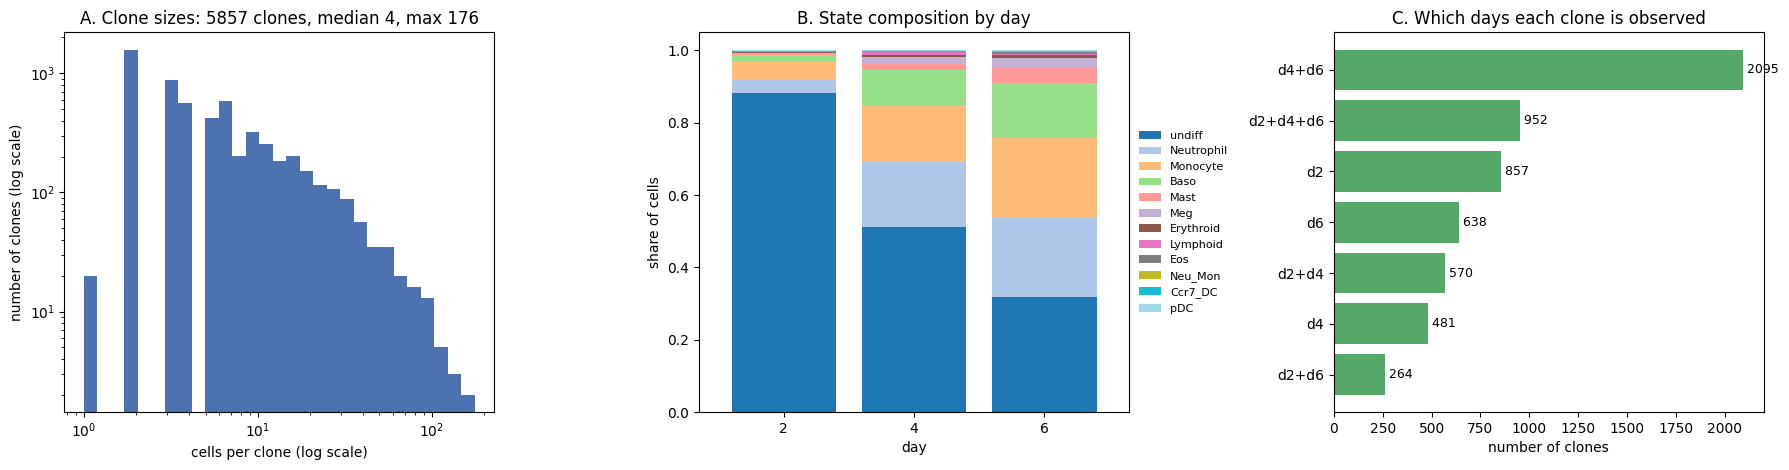

Clones observed on both day 2 and day 6 (the raw pool for day-2 -> fate evaluation): 1216
Share of day-2 cells in the undifferentiated state: 88.3%
Share of day-6 cells in the undifferentiated state: 31.9%


In [5]:
# Visual audit of the LARRY structure (uses the AnnData loaded above)
import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt
try:
    adata
except NameError:
    import anndata as ad
    adata = ad.read_h5ad('/kaggle/working/data/LARRY_adata_preprocessed.h5ad')

C = sp.csr_matrix(adata.obsm['X_clone']); C.sort_indices()
assert (np.diff(C.indptr) == 1).all(), 'expected exactly one clone label per cell'
clone_id = C.indices.copy()
t = pd.to_numeric(adata.obs['time_info'].astype(str), errors='coerce').astype(int).values
state = adata.obs['state_info'].astype(str).values
sizes = np.bincount(clone_id, minlength=C.shape[1]); sizes = sizes[sizes > 0]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))

# A. How big are clones? (the unit of inference is the clone, so this is our real sample-size picture)
ax[0].hist(sizes, bins=np.logspace(0, np.log10(sizes.max() + 1), 30), color='#4c72b0')
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('cells per clone (log scale)'); ax[0].set_ylabel('number of clones (log scale)')
ax[0].set_title(f'A. Clone sizes: {len(sizes)} clones, median {int(np.median(sizes))}, max {int(sizes.max())}')

# B. What do cells look like at each day? (undifferentiated vs committed states)
order = pd.Series(state).value_counts().index.tolist()
comp = pd.crosstab(t, state, normalize='index')[order]
comp.plot(kind='bar', stacked=True, ax=ax[1], width=0.8, colormap='tab20')
ax[1].set_xlabel('day'); ax[1].set_ylabel('share of cells'); ax[1].set_title('B. State composition by day')
ax[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8, frameon=False)
ax[1].tick_params(axis='x', rotation=0)

# C. In which days does each clone appear? (only clones seen early AND late can test state -> fate)
pres = pd.DataFrame({'c': clone_id, 't': t}).drop_duplicates()
pattern = pres.groupby('c')['t'].apply(lambda s: '+'.join(f'd{x}' for x in sorted(s)))
pc = pattern.value_counts()
ax[2].barh(pc.index[::-1], pc.values[::-1], color='#55a868')
ax[2].set_xlabel('number of clones'); ax[2].set_title('C. Which days each clone is observed')
for i, v in enumerate(pc.values[::-1]): ax[2].text(v, i, f' {v}', va='center', fontsize=9)
plt.tight_layout(); plt.show()

print('Clones observed on both day 2 and day 6 (the raw pool for day-2 -> fate evaluation):',
      int(pattern.isin(['d2+d6', 'd2+d4+d6']).sum()))
print('Share of day-2 cells in the undifferentiated state: %.1f%%' % (100 * np.mean(state[t == 2] == 'undiff')))
print('Share of day-6 cells in the undifferentiated state: %.1f%%' % (100 * np.mean(state[t == 6] == 'undiff')))


### Interpretation

**Panel A — clone sizes.** The title agrees with the earlier audit (5,857 clones, median 4, maximum 176). Reading the bars, there are only about 20 clones of size 1, but roughly 1,600 of size 2 (about 27% of all clones), then a long decaying tail. The near-absence of singletons suggests the preprocessed file was filtered to clones with at least two cells (my inference; I did not verify the filtering). Most clones are tiny, so any cell-weighted average is dominated by a few large clones (Part 3.3).
*Reading caution:* the bins are log-spaced and counts are not divided by bin width, so wider bins on the right collect more clones. The slope of the tail is therefore not a decay rate.

**Panel B — state composition by day.** Undifferentiated cells fall from 88% (day 2) to 51% (day 4) to 32% (day 6), matching the printed shares. Neutrophil and Monocyte grow from thin slices into the two largest committed bands, Baso becomes visible from day 4, and Mast, Meg and the remaining states stay slivers at every day.
*A selection effect:* 88% of **all** day-2 cells are undifferentiated, but 98% (737 of 750) of the day-2 cells in the **evaluation set** are. Already-committed day-2 cells are therefore mostly absent from eligible clones. I haven't investigated why; it means the primary task is not representative of day-2 cells in general.

**Panel C — which days each clone is observed.** The counts match the earlier audit table exactly: d4+d6 2,095; d2+d4+d6 952; d2 857; d6 638; d2+d4 570; d4 481; d2+d6 264.
- Only 952 + 264 = **1,216 clones (21%)** span day 2 and day 6, the pool for the primary question.
- 1,976 clones (34%) are seen on a single day and cannot test state → fate.
- The most common pattern is d4+d6, which is why day 4 has more clones and more power.

### Exercises (Part 2)
1. Why does counting 5,857 clones as “5,857 independent observations” overstate your evidence, and by roughly how much would it overstate it if you counted cells instead?
2. The audit shows ~41% multi-fate clones. Propose a scoring rule that respects this, and one that does not. What would each reward?
3. The notebook excludes precomputed columns such as `progenitor_Monocyte`. Describe an experiment that would *test* whether they leak clonal information (hint: what happens to a classifier’s test accuracy if you add one as a feature?).

## Part 3 — Benchmark design: protocol, leakage, and the first metric audit

### Concept: pre-specify the estimand and the splits, then freeze them
Before any model exists we decide:
- **Unit of splitting and inference: the clone.** Folds are made of whole clones, so no test cell has a sister in training. (Part 3.2 *demonstrates* why.)
- **Primary endpoint:** day-2 cells whose clone has ≥3 late differentiated cells in the five major fates (≥500 late cells overall). Day 4 is a pre-specified *secondary* analysis. Fixing this *before* seeing results limits how much a result can be tuned.
- **Scoring rule:** for each clone, the mean log-likelihood, over the clone’s *observed late cells*, of the fate probabilities the model assigned to the early cell. This is a **proper scoring rule**: it rewards honest probabilities, handles multi-fate clones, and each clone counts once (the *clone-weighted* mean).
- **Folds:** 5 clone-disjoint folds, stratified by each clone’s dominant fate, with an assertion that no clone appears in two folds.

**Relation to the paper.** The paper scores similarity to constructed trajectories. We deliberately choose an outcome that no model produced, at the cost of using a coarse (five-fate) target.

In [6]:
# =========================
# CELL 4: Define task, labels, clone-disjoint folds (no modelling)
# =========================
import numpy as np, pandas as pd, scipy.sparse as sp, anndata as ad, json
from pathlib import Path
from sklearn.model_selection import StratifiedKFold

WORK = Path("/kaggle/working"); RES = WORK / "results"; RES.mkdir(exist_ok=True)
try:
    adata
except NameError:
    adata = ad.read_h5ad(WORK / "data" / "LARRY_adata_preprocessed.h5ad")

# ---------- PRE-SPECIFIED PROTOCOL (fixed before any model is run) ----------
CFG = dict(seed=0,
           primary_early_time=2,      # primary endpoint
           secondary_early_time=4,    # pre-specified secondary
           late_time=6,
           min_late_diff=3,           # clone needs >=3 late cells in major fates
           min_fate_cells=500,        # "major fate" = >=500 late cells overall
           n_folds=5, undiff_label="undiff")
EARLY = [CFG["primary_early_time"], CFG["secondary_early_time"]]
EXCLUDED_AS_FEATURES = [c for c in adata.obs.columns if c not in ("time_info", "state_info")] \
                       + ["obsm:X_pca", "obsm:X_emb", "obsm:X_clone"]

n = adata.n_obs
t = pd.to_numeric(adata.obs["time_info"].astype(str), errors="coerce").values
states = adata.obs["state_info"].astype(str).values

# ---------- clone id per cell (each cell has exactly one clone label) ----------
C = sp.csr_matrix(adata.obsm["X_clone"]); C.sort_indices()
per_cell = np.diff(C.indptr)
assert (per_cell == 1).all(), "Expected exactly one clone per cell"
clone_id = C.indices.copy()
n_clones = C.shape[1]

# ---------- major fates from late differentiated cells ----------
late = (t == CFG["late_time"]) & (states != CFG["undiff_label"])
fate_counts = pd.Series(states[late]).value_counts()
major = fate_counts[fate_counts >= CFG["min_fate_cells"]].index.tolist()
minor = fate_counts[fate_counts < CFG["min_fate_cells"]]
print("Major fates:", major)
print("Excluded minor-fate late cells:", int(minor.sum()), "|", minor.to_dict())
late_major = late & np.isin(states, major)

# ---------- clone-level table ----------
cl = pd.DataFrame({"clone_id": np.arange(n_clones)})
for tt in sorted(np.unique(t[~np.isnan(t)])):
    cl[f"n_d{int(tt)}"] = np.bincount(clone_id[t == tt], minlength=n_clones)
for f in major:
    cl[f"late_{f}"] = np.bincount(clone_id[late_major & (states == f)], minlength=n_clones)
fate_cols = [f"late_{f}" for f in major]
cl["late_major"] = cl[fate_cols].sum(1)
props = cl[fate_cols].div(cl["late_major"].replace(0, np.nan), axis=0).fillna(0)
cl["dominant"] = props.idxmax(axis=1).str.replace("late_", "", regex=False)
cl.loc[cl["late_major"] == 0, "dominant"] = "none"
cl["purity"] = props.max(axis=1)
cl["n_fates"] = (cl[fate_cols] > 0).sum(1)
ncols = [c for c in cl.columns if c.startswith("n_d")]
cl = cl[cl[ncols].sum(1) > 0].copy()                      # drop empty clone columns

# ---------- sensitivity of eligibility (report only; k is already fixed) ----------
print("\nEligible clones by early day and k (sensitivity; main analysis uses k=%d):" % CFG["min_late_diff"])
rows = []
for e in EARLY:
    for k in [1, 3, 5]:
        sel = (cl[f"n_d{e}"] > 0) & (cl["late_major"] >= k)
        rows.append({"early_day": e, "k": k, "clones": int(sel.sum()), "cells": int(cl.loc[sel, f"n_d{e}"].sum())})
print(pd.DataFrame(rows).to_string(index=False))

# ---------- eligible clones under pre-specified k ----------
has_early = np.zeros(len(cl), bool)
for e in EARLY: has_early |= (cl[f"n_d{e}"].values > 0)
elig = cl[has_early & (cl["late_major"] >= CFG["min_late_diff"])].copy().reset_index(drop=True)
print(f"\nEligible clones overall: {len(elig)}")
print("dominant fate:\n", elig["dominant"].value_counts().to_string())
print("distinct fates per clone:\n", elig["n_fates"].value_counts().sort_index().to_string())
print("purity quantiles:", elig["purity"].quantile([.1, .25, .5, .75, .9]).round(2).to_dict())
p2 = elig[elig[f"n_d{CFG['primary_early_time']}"] > 0]
print(f"\nPRIMARY (day {CFG['primary_early_time']}) clones: {len(p2)} | dominant fate:\n",
      p2["dominant"].value_counts().to_string())

# ---------- clone-disjoint, stratified folds ----------
vc = elig["dominant"].value_counts()
strat = elig["dominant"].where(elig["dominant"].map(vc) >= CFG["n_folds"], "rare")
skf = StratifiedKFold(CFG["n_folds"], shuffle=True, random_state=CFG["seed"])
elig["fold"] = -1
for k, (_, te) in enumerate(skf.split(elig, strat)):
    elig.loc[te, "fold"] = k
assert (elig["fold"] >= 0).all() and elig["clone_id"].is_unique

# ---------- cell-level evaluation table ----------
fold_of = dict(zip(elig["clone_id"], elig["fold"]))
mask = np.isin(t, EARLY) & np.isin(clone_id, elig["clone_id"].values)
cells = pd.DataFrame({"cell_idx": np.where(mask)[0]})
cells["obs_name"] = adata.obs_names[cells["cell_idx"]].values
cells["time"] = t[cells["cell_idx"]].astype(int)
cells["state"] = states[cells["cell_idx"]]
cells["clone_id"] = clone_id[cells["cell_idx"]]
cells["fold"] = cells["clone_id"].map(fold_of)
cells = cells.merge(elig[["clone_id", "late_major", "dominant", "purity", "n_fates"] + fate_cols],
                    on="clone_id", how="left")

# ---------- leakage guard ----------
assert (cells.groupby("clone_id")["fold"].nunique() == 1).all(), "A clone appears in >1 fold"
print("\nLEAKAGE CHECK PASSED: every clone is in exactly one fold.")

print("\nEvaluation cells by day x fold:\n", pd.crosstab(cells["time"], cells["fold"]).to_string())
print("\nClones per fold x dominant fate:\n", pd.crosstab(elig["fold"], elig["dominant"]).to_string())
print("\nState of early evaluation cells (rows) by day (cols):\n",
      pd.crosstab(cells["state"], cells["time"]).to_string())

# ---------- floors (fate prior) on the PRIMARY endpoint, using sister-cell log-likelihood ----------
# prior = overall late-cell fate frequencies among eligible clones; score = mean log p(fate) over late cells
fate_tot = elig[fate_cols].sum()
prior = (fate_tot / fate_tot.sum()).values
sc = []
for e_day in EARLY:
    sub = elig[elig[f"n_d{e_day}"] > 0]
    ll = (sub[fate_cols].values * np.log(prior)).sum() / sub[fate_cols].values.sum()
    sc.append((e_day, len(sub), float(ll)))
print("\nFLOOR: fate-prior-only mean log-lik per late cell (any model must beat this):")
for e_day, nn, ll in sc: print(f"  day {e_day}: clones={nn}, mean log-lik={ll:.3f}")
print("  prior:", dict(zip(major, prior.round(3))))

# ---------- save ----------
cells.to_csv(RES / "eval_cells.csv", index=False)
elig.to_csv(RES / "eval_clones.csv", index=False)
(RES / "protocol.json").write_text(json.dumps(
    {"config": CFG, "major_fates": major, "excluded_as_features": EXCLUDED_AS_FEATURES,
     "n_eligible_clones": int(len(elig)), "n_eval_cells": int(len(cells)),
     "note": "X row sums are constant (~2878.7): library size not testable; use n_genes as proxy"},
    indent=2))
print("\nSaved eval_cells.csv, eval_clones.csv, protocol.json to", RES)

Major fates: ['Monocyte', 'Neutrophil', 'Baso', 'Mast', 'Meg']
Excluded minor-fate late cells: 651 | {'Erythroid': 282, 'Eos': 132, 'Neu_Mon': 92, 'Lymphoid': 88, 'Ccr7_DC': 40, 'pDC': 17}

Eligible clones by early day and k (sensitivity; main analysis uses k=3):
 early_day  k  clones  cells
         2  1     961   1344
         2  3     534    750
         2  5     362    505
         4  1    2239  10274
         4  3    1404   7687
         4  5     988   6143

Eligible clones overall: 1464
dominant fate:
 dominant
Monocyte      553
Neutrophil    457
Baso          315
Mast           75
Meg            64
distinct fates per clone:
 n_fates
1    958
2    451
3     51
4      4
purity quantiles: {0.1: 0.67, 0.25: 0.83, 0.5: 1.0, 0.75: 1.0, 0.9: 1.0}

PRIMARY (day 2) clones: 534 | dominant fate:
 dominant
Monocyte      206
Neutrophil    190
Baso           93
Mast           27
Meg            18

LEAKAGE CHECK PASSED: every clone is in exactly one fold.

Evaluation cells by day x fold:
 fold

### Interpretation 
**The primary task is genuinely non-trivial.** The primary endpoint has **534 clones / 750 cells** (1.4 cells per clone). 737 of the 750 day-2 cells (98%) are still `undiff` — the model must predict fate *before* commitment is visible. The dominant fates of the 534 clones are Monocyte 206, Neutrophil 190, Baso 93, Mast 27, Meg 18, so **Mast and Meg are too thin for per-fate claims** (roughly 4–5 clones per fold).

**Day 4 is a weaker test.** The secondary analysis has 1,404 clones / 7,687 cells (5.5 cells per clone), and 3,765 of those cells (49%) are already differentiated. Predicting a differentiated cell’s clone fate is partly trivial, so day-4 results must always be reported separately for undifferentiated cells.

**The leakage check passed** — every clone is in exactly one fold. The fold tables show balanced fold sizes. *Caution when reading them:* the “clones per fold × dominant fate” table covers **all 1,464 eligible clones** (day 2 or day 4), not only the 534 primary clones.

**Fate multiplicity among all eligible clones:** 958 (65%) one fate, 451 (31%) two, 55 with three or four. The median purity is 1.0, but the 10th percentile is 0.67, again supporting a distribution-valued target.

**The “FLOOR” lines at the bottom should not be trusted as a final floor.** They report −1.245 for day 2. That number is *cell-weighted* (all late cells pooled before averaging) and *transductive* (the prior used every eligible clone, including the ones being scored). The metric we actually adopt is clone-weighted and cross-fitted, and a later part reports **−1.328** for the same task. Why these differ is the first metric audit — see 3.3. This is an example of a number that looks like a result but is an artifact of an unmatched estimand.

### 3.2 Concept: why the unit of splitting matters — a leakage demonstration
If you split **cells** at random, sister cells land on both sides of the split. A classifier can then score well simply by recognizing *the clone* (its shared transcriptional signature), which is not the same as predicting fate for a *new* lineage. The same features and model, evaluated two ways, isolate the effect of the split.

**Pre-registered prediction:** the apparent-skill gap between the cell-level and clone-level splits should be **larger on day 4 than on day 2**, because day-4 clones contribute ≈5.5 cells each against ≈1.4 on day 2, so far more test cells have a sister in training. If the gap is not larger on day 4, my reasoning about *why* leakage arises is wrong, and that is worth knowing.

Simplifications: the target here is the clone’s *dominant* fate (a hard label), the features are the dataset’s global PCA (identical for both splits, so it cannot explain a difference), and the metric is macro AUROC.

 day                   split  cells  clones  cells_per_clone  test_cells_with_sister_in_train  macro_AUROC  accuracy  majority_class_accuracy
   2 cell-level random split    750     534             1.40                            0.445        0.874     0.635                    0.388
   2    clone-disjoint split    750     534             1.40                            0.000        0.855     0.631                    0.388
   4 cell-level random split   7687    1404             5.48                            0.950        0.946     0.784                    0.359
   4    clone-disjoint split   7687    1404             5.48                            0.000        0.942     0.780                    0.359


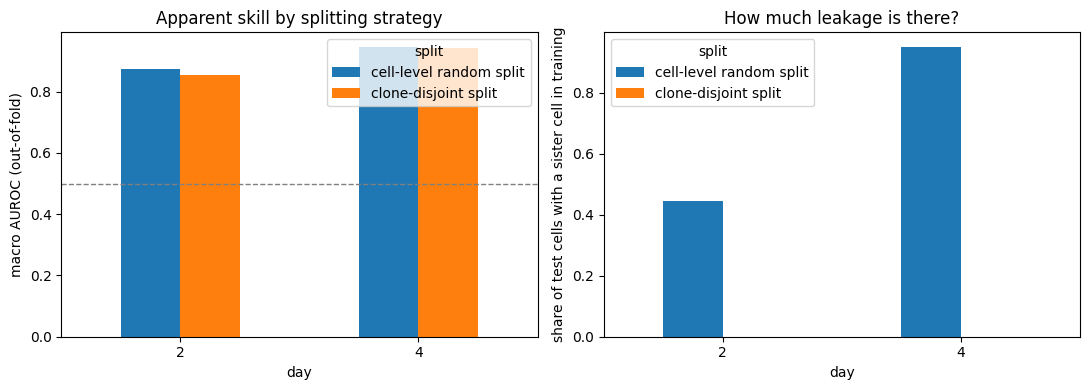

In [7]:
#  Leakage demonstration: SAME features, SAME model, two ways of splitting.
#Task: predict a clone's DOMINANT late fate from an early cell's 30 PCs.
# We use the dataset's global X_pca for BOTH splits, so it cannot explain any difference between them.
import numpy as np, pandas as pd, json, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

RES = Path('/kaggle/working/results')
cells = pd.read_csv(RES / 'eval_cells.csv', dtype={'obs_name': str})
try:
    adata
except NameError:
    import anndata as ad
    adata = ad.read_h5ad('/kaggle/working/data/LARRY_adata_preprocessed.h5ad')
PCS = np.asarray(adata.obsm['X_pca'])[:, :30]
classes = sorted(cells['dominant'].unique()); cid = {c: i for i, c in enumerate(classes)}

def oof_probs(X, y, folds, C=0.1):
    """Out-of-fold class probabilities. Scaler and classifier are fit on training folds only."""
    P = np.zeros((len(y), len(classes)))
    for k in np.unique(folds):
        tr, te = folds != k, folds == k
        sc = StandardScaler().fit(X[tr])
        clf = LogisticRegression(C=C, max_iter=300).fit(sc.transform(X[tr]), y[tr])
        P[np.ix_(te, clf.classes_)] = clf.predict_proba(sc.transform(X[te]))
    return P

def leak_share(clone, folds):
    """Share of test cells that have at least one SISTER cell (same clone, same day) in the training folds."""
    out = []
    for k in np.unique(folds):
        train_clones = set(clone[folds != k])
        out.append(np.mean([c in train_clones for c in clone[folds == k]]))
    return float(np.mean(out))

rows = []
for day in [2, 4]:
    sub = cells[cells['time'] == day].reset_index(drop=True)
    X, y = PCS[sub['cell_idx'].values], sub['dominant'].map(cid).values
    clone, folds_clone = sub['clone_id'].values, sub['fold'].values        # the notebook's clone-disjoint folds
    folds_cell = np.zeros(len(sub), int)                                    # naive split: ignores clones entirely
    for k, (_, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=0).split(X, y)):
        folds_cell[te] = k
    assert all(set(clone[folds_clone == k]).isdisjoint(clone[folds_clone != k]) for k in range(5)), 'clone folds leak!'
    for name, folds in [('cell-level random split', folds_cell), ('clone-disjoint split', folds_clone)]:
        P = oof_probs(X, y, folds)
        rows.append(dict(day=day, split=name, cells=len(sub), clones=len(set(clone)),
                         cells_per_clone=round(len(sub) / len(set(clone)), 2),
                         test_cells_with_sister_in_train=round(leak_share(clone, folds), 3),
                         macro_AUROC=round(roc_auc_score(y, P, multi_class='ovr', average='macro', labels=list(range(len(classes)))), 3),
                         accuracy=round(float(np.mean(P.argmax(1) == y)), 3),
                         majority_class_accuracy=round(float(np.max(np.bincount(y)) / len(y)), 3)))
res = pd.DataFrame(rows)
print(res.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
piv = res.pivot(index='day', columns='split', values='macro_AUROC')
piv.plot(kind='bar', ax=ax[0], rot=0); ax[0].set_ylabel('macro AUROC (out-of-fold)'); ax[0].set_title('Apparent skill by splitting strategy')
ax[0].axhline(0.5, color='grey', ls='--', lw=1)
piv2 = res.pivot(index='day', columns='split', values='test_cells_with_sister_in_train')
piv2.plot(kind='bar', ax=ax[1], rot=0); ax[1].set_ylabel('share of test cells with a sister cell in training'); ax[1].set_title('How much leakage is there?')
plt.tight_layout(); plt.show()


### Interpretation 
**Exposure vs effect — two different things.**
- **Exposure (a property of the split).** With a random cell-level split, **44.5%** of day-2 test cells and **95.0%** of day-4 test cells have a sister cell in training. The clone-disjoint split has exactly 0 by construction. So the first half of the pre-registered reasoning held: exposure is far larger on day 4.
- **Effect (a property of the split *and* the model).** Apparent skill barely moves:

| | cell-level split | clone-disjoint | gap |
|---|---|---|---|
| day 2 macro AUROC | 0.874 | 0.855 | +0.019 |
| day 2 accuracy | 0.635 | 0.631 | +0.004 |
| day 4 macro AUROC | 0.946 | 0.942 | +0.004 |
| day 4 accuracy | 0.784 | 0.780 | +0.004 |


**The two panels tell different stories, and that is the lesson.**

**Right panel — exposure.** With a random cell-level split, 44.5% of day-2 test cells and 95.0% of day-4 test cells have a sister cell in training. The clone-disjoint bars are at exactly 0 by construction; they are invisible because their height is zero, not because data are missing.

**Left panel — effect.** Macro AUROC is about 0.874 vs 0.855 on day 2 and 0.946 vs 0.942 on day 4. The two splits are almost indistinguishable even though exposure differs enormously between days. This is the visual form of the failed pre-registered prediction: more exposure on day 4 did not produce more apparent skill.

**Why the figure can mislead.**
- The y-axis starts at 0, so gaps of 0.019 and 0.004 look like nothing. That is honest about their size, but it also hides whether the day-2 gap is real.
- There are **no intervals** and only one random split. I cannot tell whether either gap differs from zero.
- Both splits sit far above the 0.5 line on day 4, largely because half of day-4 cells are already differentiated, so state alone predicts clone fate. High absolute skill can coexist with leakage.
- The legend covers the top of the day-4 bars.

**Conclusion that the figure supports:** for this low-capacity model on this task, leakage exposure did not translate into visible inflation. It does **not** show that cell-level splitting is harmless in general: a flexible model that can memorize clones (1-nearest-neighbour, boosted trees) may behave very differently, and that is untested.

**Better version of the figure (optional):** repeat the random split over many seeds and show the spread, add value labels (including the zeros), and show the gap with a bootstrap interval.

**The pre-registered prediction was not supported.** I predicted a *larger* gap on day 4. The AUROC gap is *smaller* on day 4 (0.004 vs 0.019) and the accuracy gaps are equal. My reasoning about *exposure* was right; my inference that more exposure means more inflation was incomplete.

**Hypotheses for why (untested):**
1. *Capacity.* A regularized logistic regression on 30 components cannot memorize a clone’s signature. Leakage mostly inflates skill for models that can — 1-nearest-neighbour, boosted trees, deep networks. This predicts that the gap would grow with a more flexible learner (an easy follow-up: repeat with `KNeighborsClassifier(n_neighbors=1)`).
2. *An easy task.* On day 4, 49% of cells are already differentiated, so state alone predicts clone fate well (AUROC ≈ 0.94) and leaves little room for clone memorization to add.

**What can and cannot be concluded.**
- This is **one run with no confidence intervals**, so I cannot say whether any of these gaps differs from zero — including the 0.019 on day 2.
- The result does **not** show that cell-level splitting is harmless. It shows that for *this* low-capacity model on *this* task the inflation was small. The later parts use flexible models (small-k kNN, Transformer arms), where it may matter more.
- The clone-disjoint design remains the right default because it removes the exposure regardless of model, which is exactly what you want when you don’t yet know which models you will try.

**Caveats of the demonstration itself:** hard dominant-fate labels, the dataset’s global PCA (shared by both splits), and macro AUROC that includes already-committed day-4 cells.

**Take-away:** *leakage exposure is not leakage effect.* Measure both.

### 3.3 Concept: the weighting discrepancy — one number, several definitions
The Part 3 printout reported a floor of −1.245, and a later cell reports −1.328 for the “same” task. Before calling either one an error, separate **four independent choices** that differ between them:

1. **How the score is averaged.** *Cell-weighted* (pool all late cells, then average) lets large clones dominate; *clone-weighted* (average within each clone, then across clones) counts each clone once. These are two different estimands.
2. **Transductive vs cross-fitted.** If the prior is estimated using the very clones being scored, the floor is optimistic. Cross-fitting estimates the prior for each fold from the *other* folds.
3. **Which clones estimate the prior** — all eligible clones, or only the day-2 clones being scored.
4. **How the estimating clones are weighted** — pooled late-cell frequencies (big clones count more) or the average of per-clone fractions (every clone counts once).

A small piece of math explains why the fourth choice matters. For a clone-weighted score, maximizing the average log-likelihood over constant distributions `p` gives `p_f ∝ Σ_clones (fraction of the clone’s late cells with fate f)` — the **mean of clone fractions**, not the pooled late-cell frequency. So using pooled frequencies as the prior for a clone-weighted score is a *mismatched, slightly suboptimal* floor. A better-specified constant can beat it — by about 0.014 nats on this task, with an interval that just touches zero — and that is the symptom that appeared later: a shuffled-label control showed a small apparent gain over such a floor, which a correctly specified constant removed.

**Is this an implementation error or a conceptual problem?** Based on the later numbers it was *conceptual* (an estimand mismatch), not a coding bug — but this cell lets you verify that by reproducing each earlier number from its definition, then changing one choice at a time.

**Why it matters for conclusions.** A weak floor inflates every “gain over the floor”, and it can make a null control look like a small positive effect. The size of the effect here is small compared with the gains of the best supervised model, so it changes *controls and small effects*, not the headline.

A  cell-weighted, transductive pooled prior (day-2 clones: 534) : -1.245
                                                floor  mean_loglik              ci    change_vs_row_above
         B  clone-weighted, transductive pooled prior       -1.327 [-1.371,-1.286]                       
    C  cross-fitted pooled prior, all eligible clones       -1.328 [-1.372,-1.286] -0.001 [-0.003,+0.001]
      D  cross-fitted pooled prior, day-2 clones only       -1.332 [-1.401,-1.268] -0.004 [-0.031,+0.022]
E  cross-fitted clone-mean prior, all eligible clones       -1.318 [-1.362,-1.275] +0.014 [-0.010,+0.039]
  F  cross-fitted clone-mean prior, day-2 clones only       -1.314 [-1.366,-1.265] +0.004 [-0.006,+0.014]

Priors (fractions of each fate), all eligible clones:
                            Monocyte  Neutrophil   Baso   Mast    Meg
pooled late-cell frequency     0.339       0.324  0.237  0.065  0.035
mean of clone fractions        0.365       0.325  0.210  0.055  0.045

Reproduction checks again

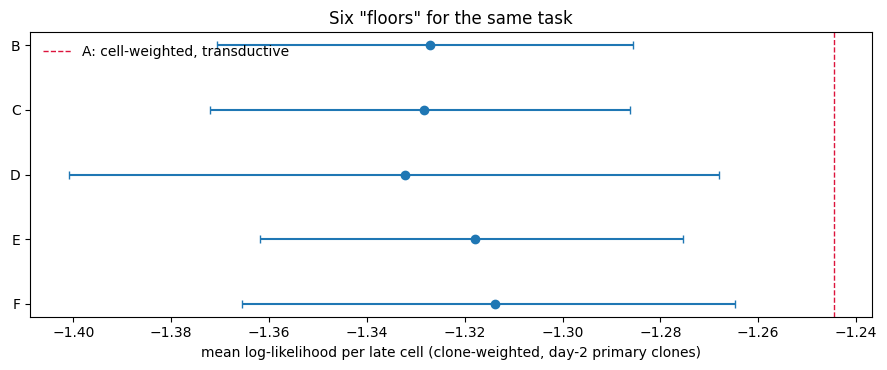

In [8]:
# Weighting audit: why do different "prior floors" disagree?
# Every floor below is a CONSTANT fate distribution. They differ in (1) how the score is averaged, (2) whether the
# prior was estimated using the test fold, (3) which clones estimate it, (4) how those clones are weighted.
import numpy as np, pandas as pd, json, matplotlib.pyplot as plt
from pathlib import Path

RES = Path('/kaggle/working/results')
proto = json.loads((RES / 'protocol.json').read_text())
major = proto['major_fates']; fate_cols = [f'late_{f}' for f in major]
elig = pd.read_csv(RES / 'eval_clones.csv')
cnt = elig[fate_cols].values.astype(float)               # late-cell counts per fate, per clone
m = cnt.sum(1); frac = cnt / m[:, None]                  # each clone's fate fractions
fold = elig['fold'].values
is2 = elig['n_d2'].values > 0                            # the 534 day-2 primary clones
ALL = np.ones(len(elig), bool)

def pooled(rows):                                        # late-cell frequencies: big clones count more
    v = cnt[rows].sum(0); return v / v.sum()
def clone_mean(rows):                                    # average of per-clone fractions: every clone counts once
    v = frac[rows].mean(0); return v / v.sum()
def clone_ll(P):                                         # per-clone mean log-likelihood per late cell
    return (cnt * np.log(P)).sum(1) / m
def crossfit(estimator, pool_mask):                      # prior for each fold uses ONLY clones outside that fold
    P = np.zeros((len(elig), len(major)))
    for k in np.unique(fold):
        P[fold == k] = estimator((fold != k) & pool_mask)
    return P

# (A) cell-weighted score, one prior estimated from ALL eligible clones (includes the test clones)
P_all = pooled(ALL)
cell_weighted = float((cnt[is2] * np.log(P_all)).sum() / m[is2].sum())
# (B) clone-weighted score, same transductive prior; (C-F) clone-weighted, cross-fitted priors
floor_variants = {
 'B  clone-weighted, transductive pooled prior':             clone_ll(np.tile(P_all, (len(elig), 1)))[is2],
 'C  cross-fitted pooled prior, all eligible clones':        clone_ll(crossfit(pooled, ALL))[is2],
 'D  cross-fitted pooled prior, day-2 clones only':          clone_ll(crossfit(pooled, is2))[is2],
 'E  cross-fitted clone-mean prior, all eligible clones':    clone_ll(crossfit(clone_mean, ALL))[is2],
 'F  cross-fitted clone-mean prior, day-2 clones only':      clone_ll(crossfit(clone_mean, is2))[is2],
}

def boot(x, B=2000, seed=0):
    g = np.random.default_rng(seed); mu = x[g.integers(0, len(x), (B, len(x)))].mean(1)
    return float(x.mean()), np.percentile(mu, [2.5, 97.5])

print(f'A  cell-weighted, transductive pooled prior (day-2 clones: {int(is2.sum())}) : {cell_weighted:.3f}')
rows, prev = [], None
for name, x in floor_variants.items():
    mu, ci = boot(x)
    d = '' if prev is None else '%+.3f [%+.3f,%+.3f]' % ((lambda r: (r[0], r[1][0], r[1][1]))(boot(x - prev)))
    rows.append(dict(floor=name, mean_loglik=round(mu, 3), ci=f'[{ci[0]:.3f},{ci[1]:.3f}]', change_vs_row_above=d))
    prev = x
print(pd.DataFrame(rows).to_string(index=False))

print('\nPriors (fractions of each fate), all eligible clones:')
print(pd.DataFrame({'pooled late-cell frequency': pooled(ALL), 'mean of clone fractions': clone_mean(ALL)}, index=major).round(3).T.to_string())

print('\nReproduction checks against earlier cells of the original notebook:')
print(f'  A should be close to -1.245 (Cell 4 printout)  -> {cell_weighted:.3f}')
print(f'  C should be close to -1.328 (Cell 5 / 6D prior) -> {floor_variants["C  cross-fitted pooled prior, all eligible clones"].mean():.3f}')
print(f'  F minus C should be near +0.014 (Cell 10)       -> {(floor_variants["F  cross-fitted clone-mean prior, day-2 clones only"] - floor_variants["C  cross-fitted pooled prior, all eligible clones"]).mean():+.3f}')

names = list(floor_variants); vals = [boot(floor_variants[n]) for n in names]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.errorbar([v[0] for v in vals], range(len(names)), xerr=[[v[0] - v[1][0] for v in vals], [v[1][1] - v[0] for v in vals]], fmt='o', capsize=3)
ax.axvline(cell_weighted, color='crimson', ls='--', lw=1, label='A: cell-weighted, transductive')
ax.set_yticks(range(len(names))); ax.set_yticklabels([n.split(' ')[0] for n in names]); ax.invert_yaxis()
ax.set_xlabel('mean log-likelihood per late cell (clone-weighted, day-2 primary clones)'); ax.legend(frameon=False)
ax.set_title('Six "floors" for the same task'); plt.tight_layout(); plt.show()


### Interpretation 
**All three reproduction checks match exactly** (A = −1.245, C = −1.328, F − C = +0.014). So the earlier numbers are fully accounted for by the four design choices; there is no hidden bug in these floors.

### figure

**Left panel.** The red bin means with 95% intervals match the printed table: about +0.79 (3–4 late cells), +0.85 (5–9), +0.96 (10–19) and +0.78 (≥20). Three features stand out.
1. **The gain is not a uniform cloud.** Clones sit in horizontal bands near +1.0, in groups near +2.1 and +2.7 (and up to about +3.2), and in a cluster at or below zero among 3–5-cell clones.
2. **The vertical streaks at x = 3, 4, 5 are an artifact of integer clone sizes.** A clone with 3 late cells has a one-cell half A and a two-cell half B, so only a few outcomes are possible.
3. **A hand calculation reproduces the clusters.** For a pure (single-fate) clone with half-A size a and smoothing α = 1, the oracle gain is about log((a + P)/(a + 1)) − log(P), where P is the prior probability of the clone’s fate. Using the printed pooled priors (0.339, 0.324, 0.237, 0.065, 0.035), for a 3-cell pure clone (a = 1) this gives roughly: Monocyte 0.68, Neutrophil 0.71, Baso 0.96, **Mast 2.10, Meg 2.69**. These match the clusters near 0.7, 1.0, 2.1 and 2.7 at x = 3. For large pure clones the gain approaches −log(P): 1.08, 1.13, 1.44, 2.73, 3.35, matching the band near +1.0 and the highest points. The prior in the code is the cross-fitted one, so this is approximate, and I have not confirmed it with a cross-tabulation by fate (optional cell 4.3).
4. **The cluster at or below zero** consists of small, mixed-fate clones where the single half-A cell points to a different fate than the half-B cells (my reading). It is the 14% of 3–4-cell clones where the oracle loses to the prior.

**Right panel.** The shuffled control is centred near −0.7 and lies almost entirely left of zero. The oracle distribution has its main mass near +0.7 to +1.1, a shoulder between 0 and +0.5, and a long right tail from about +1.8 to +3.2. Overlap is thin, around zero (the 5.8% of clones where the oracle underperforms). The tail is made of rare-fate clones, so a clone-weighted mean gain is pulled up by Mast and Meg clones.

**Consequences.** A single oracle number hides this structure. The gain is largely set by *which fate* a clone has and by how many cells half A contains, which is why it should be reported as a range and, ideally, by fate.

**What the figure does not show:** why the gain falls for the largest clones (≥20), or the exact fate composition of each band.

**Where the discrepancy comes from.** The gap between the Part 3 printout (−1.245) and the adopted floor (−1.328) is 0.083 nats:
- **A → B (averaging: cell- vs clone-weighted, same prior): −1.245 → −1.327 = −0.082.** Almost the entire gap.
- **B → C (transductive → cross-fitted): −0.001 [−0.003, +0.001].** Estimating the prior with the test clones inside it cost essentially nothing here — the prior is estimated from ~1,460 clones and is stable.
So **the discrepancy is a difference of *estimand* (whose performance is averaged), not leakage in the prior and not a coding error.** (A → B is a difference of two point estimates; the follow-up cell below adds an interval.)

**The other choices matter much less.**
- **C → D** (prior from day-2 clones only): −0.004 [−0.031, +0.022] — no detectable effect, with a wider interval because fewer clones contribute.
- **Pooled vs clone-mean estimator.** The two priors visibly differ (Monocyte 0.339 vs 0.365, Baso 0.237 vs 0.210, Meg 0.035 vs 0.045). By point estimate, switching to the clone-mean prior improves the floor by about +0.010 (all eligible clones, C → E) and +0.018 (day-2 clones only, D → F); these are differences of rounded printed means, so treat them as approximate. The earlier combined contrast (F − C) was +0.014 with an interval that just touches zero.

**Careful with the printed table.** Its last column compares each row with the row directly above. Row E’s +0.014 is **E − D**, which changes *both* the population and the estimator; row F’s +0.004 is F − E. They are not clean one-factor contrasts, which is why the follow-up cell computes them properly.

**Pre-registered expectations — result.**
- Clone-mean priors should tend to score at least as well as pooled ones: **held in point estimates** (both differences positive), magnitude small, intervals not yet shown.
- Cross-fitting should cost a little: **held** (≈0).
- I did not predict which choice dominates: it is the **averaging estimand**.

**Why it matters.**
- Within one weighting, a floor difference cancels in a *paired* comparison of two models scored the same way; across weightings, numbers are not comparable at all. Always state the estimand next to the number.
- The 0.082-nat averaging effect is about 18% of the supervised model’s 0.46-nat gain — small for the headline, but large enough to change how controls and small effects look.
- Choose the estimand from the question: **clone-weighted** = “how well do we predict a *new lineage*?” (each lineage one vote); **cell-weighted** = “how well do we predict a random *cell’s* descendants?” (large clones dominate).

**Why would cell-weighting give a *higher* floor?** One candidate: larger clones are easier for the prior. The earlier floor/oracle output (Part 4 later) shows the prior’s score rising with clone size — −1.433 (3–4 late cells), −1.337 (5–9), −1.227 (≥10) — consistent with this, though computed slightly differently. That is a hypothesis; the next cell tests it with an exact identity.

### 3.4 Follow-up: clean contrasts, and an exact explanation of the cell- vs clone-weighting gap
The table above could not give clean one-factor contrasts for the estimator and population choices, and it explained the averaging gap only by hypothesis. The cell below does both:
1. Paired, clone-level bootstrap intervals for each single change (A→B, B→C, C→D, E→F, C→E, D→F, C→F).
2. The exact identity **cell-weighted − clone-weighted = cov(clone size, clone score) / mean clone size**. This is algebra, not a finding — it shows that the gap is *entirely* the covariance between how big a clone is and how well it scores. The informative part is the *sign and size* of that covariance, and the score by clone-size bin.

**Pre-registered rule:** the identity must hold to about 1e-4; if it does not, there is a bug. The **prediction** is a positive correlation between clone size and score, since larger clones scored better under the prior in the earlier output. If the correlation is near zero, the covariance explanation fails and the 0.082-nat gap needs another explanation.

In [9]:
import numpy as np, pandas as pd
from scipy.stats import spearmanr
need = ['floor_variants', 'cnt', 'm', 'is2', 'pooled', 'ALL']
assert all(n in globals() for n in need), 'run the weighting-audit cell first'
fl = {k.split()[0]: v for k, v in floor_variants.items()}          # keys B..F: per-clone mean log-lik over the day-2 clones
idx2 = np.where(is2)[0]; n2 = len(idx2); mm = m[idx2]
tot = (cnt[idx2] * np.log(pooled(ALL))).sum(1)             # per-clone TOTAL log-lik of its late cells under the pooled prior
per = tot / mm                                              # per-clone MEAN log-lik (this is floor B)

def paired(d, B=4000, seed=0):
    g = np.random.default_rng(seed); mu = d[g.integers(0, len(d), (B, len(d)))].mean(1)
    return d.mean(), np.percentile(mu, [2.5, 97.5])

g = np.random.default_rng(0); ab = np.empty(4000)           # A vs B: resample clones for BOTH estimands at once
for b in range(4000):
    i = g.integers(0, n2, n2); ab[b] = per[i].mean() - tot[i].sum() / mm[i].sum()
A_ = tot.sum() / mm.sum(); B_ = per.mean()
contrasts = [
 ('A->B  averaging: cell-weighted -> clone-weighted (same prior)',      (B_ - A_, np.percentile(ab, [2.5, 97.5]))),
 ('B->C  transductive -> cross-fitted pooled prior',                    paired(fl['C'] - fl['B'])),
 ('C->D  prior from all eligible -> day-2 clones only (pooled)',        paired(fl['D'] - fl['C'])),
 ('E->F  prior from all eligible -> day-2 clones only (clone-mean)',    paired(fl['F'] - fl['E'])),
 ('C->E  estimator: pooled -> clone-mean (all eligible clones)',        paired(fl['E'] - fl['C'])),
 ('D->F  estimator: pooled -> clone-mean (day-2 clones only)',          paired(fl['F'] - fl['D'])),
 ('C->F  both of the above (the Cell 10 contrast)',                     paired(fl['F'] - fl['C'])),
]
print(pd.DataFrame([{'contrast': n, 'change (nats)': '%+.3f [%+.3f,%+.3f]' % (r[0], r[1][0], r[1][1])} for n, r in contrasts]).to_string(index=False))

# WHY do the two averages differ?  Exact identity:  cell-weighted - clone-weighted = cov(size, per-clone score) / mean(size)
cov = np.mean((mm - mm.mean()) * (per - per.mean()))
print('\nIdentity check:  A - B = %+.4f   vs   cov(size, score)/mean(size) = %+.4f' % (A_ - B_, cov / mm.mean()))
rho, p = spearmanr(mm, per)
print('Spearman correlation between clone size and per-clone floor score: %+.3f (p = %.2g)' % (rho, p))
bins = pd.cut(mm, [2, 4, 9, np.inf], labels=['3-4', '5-9', '>=10'])
rows = []
for lab in bins.categories:
    sel = np.asarray(bins == lab); mu, ci = paired(per[sel])
    rows.append({'late cells in clone': lab, 'clones': int(sel.sum()), 'floor B (mean log-lik)': '%.3f [%.3f,%.3f]' % (mu, ci[0], ci[1])})
print('\n' + pd.DataFrame(rows).to_string(index=False))


                                                       contrast          change (nats)
  A->B  averaging: cell-weighted -> clone-weighted (same prior) -0.083 [-0.111,-0.054]
                B->C  transductive -> cross-fitted pooled prior -0.001 [-0.003,+0.001]
    C->D  prior from all eligible -> day-2 clones only (pooled) -0.004 [-0.032,+0.023]
E->F  prior from all eligible -> day-2 clones only (clone-mean) +0.004 [-0.006,+0.014]
    C->E  estimator: pooled -> clone-mean (all eligible clones) +0.010 [+0.003,+0.018]
      D->F  estimator: pooled -> clone-mean (day-2 clones only) +0.018 [+0.002,+0.036]
                 C->F  both of the above (the Cell 10 contrast) +0.014 [-0.001,+0.029]

Identity check:  A - B = +0.0827   vs   cov(size, score)/mean(size) = +0.0827
Spearman correlation between clone size and per-clone floor score: +0.090 (p = 0.038)

late cells in clone  clones floor B (mean log-lik)
                3-4     172 -1.430 [-1.532,-1.336]
                5-9     172 -1.337 [

### Interpretation 
**The averaging estimand matters; the other choices barely do.**
- **A → B: −0.083 [−0.111, −0.054].** The only contrast that is clearly non-zero by a wide margin.
- **B → C −0.001 [−0.003, +0.001]**, **C → D −0.004 [−0.032, +0.023]**, **E → F +0.004 [−0.006, +0.014]** — none distinguishable from zero. Estimating the prior with or without the test clones, and from all eligible vs only day-2 clones, does not detectably change the floor here.
- **Estimator (pooled → clone-mean): C → E +0.010 [+0.003, +0.018]; D → F +0.018 [+0.002, +0.036].** Both intervals exclude zero, but only barely, and this is one of seven contrasts with no multiplicity correction. Read it as a *small* advantage of the clone-mean prior, in the direction the maximum-likelihood argument predicts, not as a firm effect. The combined C → F contrast (+0.014 [−0.001, +0.029]) touches zero because it also carries the noisy population change.

**The explanation of the A − B gap is now exact, not a hypothesis.** The identity check matches to four decimals (+0.0827 both ways), so the whole gap is the covariance between clone size and clone score divided by mean clone size. (The identity is algebra: it validates the code and the estimand, it is not a finding.)

**What the data add: larger clones are easier for the prior.** The Spearman correlation is positive as predicted but weak (+0.090, p = 0.038): size explains little of the *rank order* of clone scores. Yet the *means* differ clearly — −1.430 [−1.532, −1.336] for 3–4 late cells, −1.337 for 5–9, and −1.225 [−1.275, −1.181] for ≥10, and the extreme bins’ intervals do not overlap. So cell-weighting, which lets big clones dominate, gives a more flattering number than clone-weighting. **Why** large clones are easier is not tested here; one candidate is that they are dominated by the common fates, which the prior favours. A quick check (exercise 5 below) is to cross-tabulate clone size with dominant fate.

**Decision carried forward.** Use the **clone-weighted** estimand, a **cross-fitted clone-mean** floor, and state the estimand next to every number.

### Exercises (Part 3)
1. Construct a toy example with two clones — one with 1 late cell, one with 100 — where cell-weighted and clone-weighted averages of the same predictions differ substantially. Which one corresponds to “how well do we predict a *new lineage*”?
2. Why does the leakage in Part 3.2 depend on **cells per clone**? Predict what would happen to the demonstration if every clone had exactly one early cell.
3. Explain, in your own words, why a floor that is mis-specified for the metric can produce a *positive* result from a shuffled-label control. What would you check in any new benchmark to catch this?
4. The protocol fixes the eligibility threshold (≥3 late cells) before modelling. Name one way a threshold chosen *after* seeing results could bias a conclusion.

## Part 4 — The floor and the clone-mate reference: bracketing what is possible

### Concept
Before judging any model we need two reference points.

**The floor** is the score of a constant fate distribution that ignores the cell. A model at or below it has shown no cell-specific signal (or its probabilities are badly calibrated — a distinction that becomes important in Part 6).

**The clone-mate reference (“oracle”)** answers: *how much could a prediction gain if it knew the clone’s identity, including hidden, stable properties that no transcriptome shows?* It is built like this:
1. Split each clone’s late cells at random into halves A (⌊m/2⌋ cells) and B (the rest).
2. Estimate the clone’s fate distribution from half A, shrunk toward the cross-fitted prior with weight α (primary α = 1): `q = (counts_A + α·prior) / (|A| + α)`.
3. Score `q` on the cells of half B. Score the **prior on the same half-B cells**, so the comparison is paired.
4. Repeat over 100 random splits and average.
5. **Negative control:** score *another clone’s* `q` on half B. It must come out worse than the prior; if not, the scoring is broken.

**Why it is not a ceiling — in either direction.** (a) No transcriptome-only model can see the barcode, so it cannot be expected to reach it. (b) A clone with 3 late cells builds its estimate from a single cell, which is very noisy, so the reference probably *underestimates* what clone identity could buy. We therefore use it for **scale only** and report absolute gains in nats; we avoid statements like “the model reaches 55% of the oracle”.

**Relation to the paper.** The paper has no independent reference of this kind (its simple baseline is delta extrapolation). An independent outcome lets us put every later number on a scale.

**A caveat from Part 3.** This cell uses the *pooled* cross-fitted prior as both floor and shrinkage target. Part 3.4 showed that a clone-mean prior is slightly better (by roughly 0.01–0.02 nats), so the absolute gains below are slightly overstated. Later model comparisons use the clone-mean floor.

In [10]:
# =========================
# CELL 5: Cross-fitted prior floor + clone-mate reference (no models yet)
# =========================
import numpy as np, pandas as pd, json
from pathlib import Path

WORK = Path("/kaggle/working"); RES = WORK / "results"
proto = json.loads((RES / "protocol.json").read_text())
major = proto["major_fates"]; fate_cols = [f"late_{f}" for f in major]
elig = pd.read_csv(RES / "eval_clones.csv")
counts = elig[fate_cols].values.astype(int)          # late-cell fate counts per clone
fold = elig["fold"].values
nC, F = counts.shape
m = counts.sum(1)
assert (m >= proto["config"]["min_late_diff"]).all()
mA = m // 2                                          # half A size (>=1); half B = rest (>=2)
EPS, R, ALPHAS, PRIMARY_ALPHA = 1e-12, 100, [0.5, 1.0, 2.0], 1.0

# cross-fitted prior: for clones in fold k, use late-cell fate frequencies from the other folds
P = np.zeros((nC, F))
for k in sorted(np.unique(fold)):
    tr = counts[fold != k].sum(0).astype(float)
    P[fold == k] = tr / tr.sum()

def ll(cnt, q):                                      # mean log-lik per late cell, per clone
    return (cnt * np.log(q + EPS)).sum(1) / np.maximum(cnt.sum(1), 1)

# ---- reference computed over R random half-splits ----
rng = np.random.default_rng(proto["config"]["seed"])
acc = {a: {"oracle": np.zeros(nC), "shuffled": np.zeros(nC)} for a in ALPHAS}
prior_B = np.zeros(nC)
for r in range(R):
    cntA = np.zeros_like(counts)
    for i in range(nC):
        cntA[i] = rng.multivariate_hypergeometric(counts[i], int(mA[i]))
    cntB = counts - cntA
    perm = rng.permutation(nC)
    prior_B += ll(cntB, P)                           # prior scored on the SAME B cells (paired)
    for a in ALPHAS:
        qA = (cntA + a * P) / (mA[:, None] + a)
        acc[a]["oracle"] += ll(cntB, qA)
        acc[a]["shuffled"] += ll(cntB, qA[perm])     # negative control: another clone's estimate
prior_B /= R
for a in ALPHAS:
    for k in acc[a]: acc[a][k] /= R

# ---- clone-level bootstrap ----
def boot(x, B=2000, seed=0):
    g = np.random.default_rng(seed); idx = g.integers(0, len(x), (B, len(x)))
    mu = x[idx].mean(1); return float(x.mean()), [float(v) for v in np.percentile(mu, [2.5, 97.5])]

subsets = {
    "day2 PRIMARY (all)": elig["n_d2"].values > 0,
    "day4 secondary (all)": elig["n_d4"].values > 0,
    "day2, late cells 3-4": (elig["n_d2"].values > 0) & (m <= 4),
    "day2, late cells 5-9": (elig["n_d2"].values > 0) & (m >= 5) & (m <= 9),
    "day2, late cells >=10": (elig["n_d2"].values > 0) & (m >= 10),
}
a = PRIMARY_ALPHA
rows, out = [], {}
for name, msk in subsets.items():
    if msk.sum() < 20:
        print(f"skip {name}: only {msk.sum()} clones"); continue
    pr, orc, sh = prior_B[msk], acc[a]["oracle"][msk], acc[a]["shuffled"][msk]
    d_or, d_sh = orc - pr, sh - pr
    r_ = {"subset": name, "clones": int(msk.sum()),
          "prior_ll": boot(pr), "oracle_ll": boot(orc),
          "oracle_minus_prior": boot(d_or), "shuffled_minus_prior": boot(d_sh)}
    out[name] = r_
    rows.append([name, msk.sum(), f"{r_['prior_ll'][0]:.3f}", f"{r_['oracle_ll'][0]:.3f}",
                 f"{r_['oracle_minus_prior'][0]:+.3f} [{r_['oracle_minus_prior'][1][0]:+.3f},{r_['oracle_minus_prior'][1][1]:+.3f}]",
                 f"{r_['shuffled_minus_prior'][0]:+.3f} [{r_['shuffled_minus_prior'][1][0]:+.3f},{r_['shuffled_minus_prior'][1][1]:+.3f}]"])
print(f"\nClone-weighted mean log-lik per late cell (alpha={a}, R={R} half-splits, 95% clone-bootstrap CI)")
print(pd.DataFrame(rows, columns=["subset", "clones", "prior", "oracle", "oracle-prior", "shuffled-prior (control)"]).to_string(index=False))

pm = subsets["day2 PRIMARY (all)"]
print("\nSmoothing sensitivity, day-2 primary (oracle - prior):")
for al in ALPHAS:
    d = acc[al]["oracle"][pm] - prior_B[pm]; mu, ci = boot(d)
    print(f"  alpha={al}: {mu:+.3f} [{ci[0]:+.3f}, {ci[1]:+.3f}]")

full_prior = ll(counts, P)                            # prior scored on ALL late cells, cross-fitted
print("\nCross-fitted prior floor on all late cells, clone-weighted:")
for name in ["day2 PRIMARY (all)", "day4 secondary (all)"]:
    mu, ci = boot(full_prior[subsets[name]]); print(f"  {name}: {mu:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]")

print("\nSanity checks:")
d_sh = out["day2 PRIMARY (all)"]["shuffled_minus_prior"]
print("  shuffled control <= 0 (must be):", d_sh[0] <= 0)
print("  oracle > prior on day2 primary:", out["day2 PRIMARY (all)"]["oracle_minus_prior"][1][0] > 0)

pd.DataFrame({"clone_id": elig["clone_id"], "n_late": m, "fold": fold, "n_d2": elig["n_d2"],
              "n_d4": elig["n_d4"], "prior_ll_B": prior_B,
              "oracle_ll_B": acc[a]["oracle"], "shuffled_ll_B": acc[a]["shuffled"]}
             ).to_csv(RES / "ceiling_per_clone.csv", index=False)
(RES / "ceiling.json").write_text(json.dumps({"alpha": a, "R": R, "results": out}, indent=2))
print("\nSaved ceiling.json and ceiling_per_clone.csv in", RES)


Clone-weighted mean log-lik per late cell (alpha=1.0, R=100 half-splits, 95% clone-bootstrap CI)
               subset  clones  prior oracle           oracle-prior shuffled-prior (control)
   day2 PRIMARY (all)     534 -1.329 -0.486 +0.843 [+0.796,+0.893]   -0.714 [-0.736,-0.694]
 day4 secondary (all)    1404 -1.374 -0.458 +0.915 [+0.882,+0.948]   -0.736 [-0.749,-0.723]
 day2, late cells 3-4     172 -1.433 -0.641 +0.792 [+0.691,+0.901]   -0.745 [-0.788,-0.705]
 day2, late cells 5-9     172 -1.337 -0.488 +0.849 [+0.761,+0.938]   -0.718 [-0.757,-0.682]
day2, late cells >=10     190 -1.227 -0.344 +0.883 [+0.821,+0.948]   -0.683 [-0.712,-0.655]

Smoothing sensitivity, day-2 primary (oracle - prior):
  alpha=0.5: +0.892 [+0.840, +0.946]
  alpha=1.0: +0.843 [+0.796, +0.893]
  alpha=2.0: +0.753 [+0.712, +0.798]

Cross-fitted prior floor on all late cells, clone-weighted:
  day2 PRIMARY (all): -1.328 [-1.372, -1.286]
  day4 secondary (all): -1.373 [-1.405, -1.345]

Sanity checks:
  shuffled c

### Interpretation 
**Floor and reference (day-2 primary, 534 clones; clone-weighted; α = 1).**
- Prior: **−1.329** nats per late cell. Clone-mate reference: **−0.486**. Gain: **+0.843 [+0.796, +0.893]**.
- **Negative control passes:** the shuffled-clone estimate is **−0.714 [−0.736, −0.694] nats worse than the prior**, as it must be (a control with a gain at or above zero would signal a scoring bug). Both printed sanity checks are `True`.
- Day 4 (secondary): prior −1.374, reference gain **+0.915 [+0.882, +0.948]**.

**The reference number is not a single number.** Changing the shrinkage α across a factor of four moves the day-2 gain from **+0.892 (α = 0.5)** to **+0.843 (α = 1)** to **+0.753 (α = 2)** — a span of about 0.14 nats, *larger than the entire cell-vs-clone weighting effect* from Part 3. So quote it as a **range, about +0.75 to +0.89 nats**, never as one value.

**Clone size.** The gain rises with the number of late cells — +0.792 [+0.691, +0.901] (3–4), +0.849 (5–9), +0.883 [+0.821, +0.948] (≥10) — which is what you would expect if tiny halves make the estimate noisy. But the intervals overlap, so this is *consistent with* that explanation, not a demonstration of it — and, as the finer bins in 4.2 show, the three-bin picture turns out to be too coarse.

**Floors.** The cross-fitted prior floor on *all* late cells is −1.328 [−1.372, −1.286] (day 2) and −1.373 [−1.405, −1.345] (day 4), matching the half-B value, as it should.

**What this does and does not show.** It shows that clone identity carries a lot of information about late fate (the reference beats the prior by a wide margin and the control behaves). It does **not** say a transcriptome can capture any particular fraction of it, and it should not be read as an attainable accuracy.

### 4.2 Concept: look at the reference at clone level
A mean hides structure. Is the reference gain driven by a few clones? Does it fail for clones whose half-A has only one or two cells? The next cell reads the per-clone file saved above (no recomputation) and breaks the gain down by clone size.

**Pre-registered predictions:**
1. The oracle-minus-prior gain is **positive on average in every size bin**.
2. The share of clones where the oracle is **worse than the prior** is **largest in the smallest bin** (half-A of 1–2 cells is noisy). If it is not, the “small halves make it conservative” explanation weakens.
3. The shuffled-control gain is **negative on average in every bin**.
4. The Spearman correlation between clone size and oracle gain is **positive**.

late cells  clones  mean half-A size         oracle - prior share of clones where oracle < prior shuffled - prior (control)
       3-4     172               1.4 +0.792 [+0.691,+0.901]                                14.0%     -0.745 [-0.788,-0.705]
       5-9     172               3.0 +0.849 [+0.761,+0.938]                                 4.1%     -0.718 [-0.757,-0.682]
     10-19     114               6.5 +0.955 [+0.876,+1.049]                                 0.0%     -0.680 [-0.721,-0.640]
      >=20      76              16.8 +0.775 [+0.691,+0.866]                                 0.0%     -0.687 [-0.731,-0.649]

All day-2 primary clones (n=534): oracle - prior = +0.843 [+0.796,+0.893] | share with oracle < prior: 5.8%
Spearman(clone size, oracle gain) = +0.170 (p = 8.1e-05)


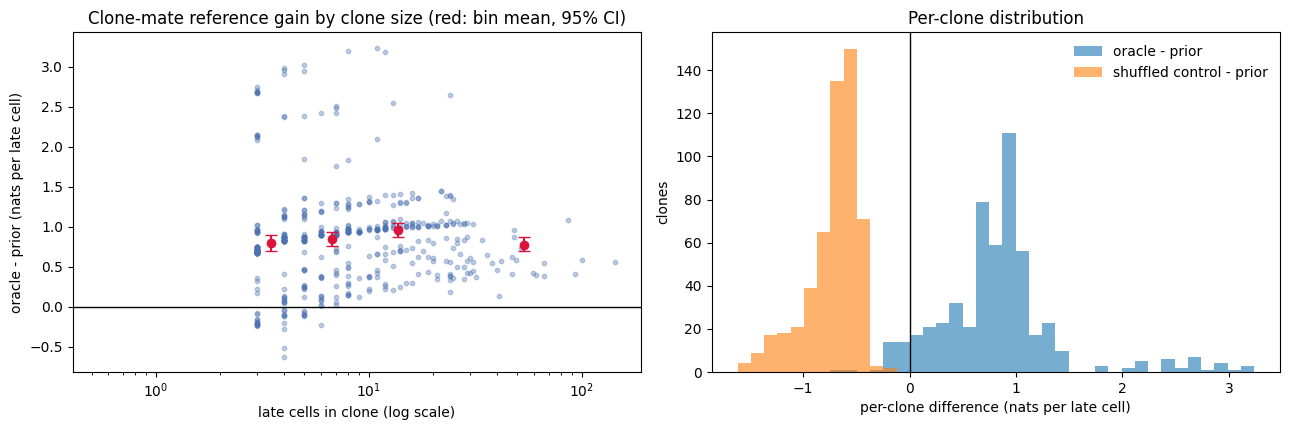

In [11]:
# Oracle diagnostics from the per-clone file saved by the previous cell (no recomputation).
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr

RES = Path('/kaggle/working/results')
d = pd.read_csv(RES / 'ceiling_per_clone.csv')
d = d[d['n_d2'] > 0].copy()                                   # the day-2 primary clones
d['oracle_gain'] = d['oracle_ll_B'] - d['prior_ll_B']         # clone-mate reference minus prior, on the SAME half-B cells
d['shuffled_gain'] = d['shuffled_ll_B'] - d['prior_ll_B']     # negative control: another clone's estimate
d['half_A'] = d['n_late'] // 2                                # cells used to build the reference estimate

def boot(x, B=2000, seed=0):
    x = np.asarray(x, float); g = np.random.default_rng(seed)
    mu = x[g.integers(0, len(x), (B, len(x)))].mean(1); return x.mean(), np.percentile(mu, [2.5, 97.5])
fmt_ci = lambda r: '%+.3f [%+.3f,%+.3f]' % (r[0], r[1][0], r[1][1])

d['size_bin'] = pd.cut(d['n_late'], [2, 4, 9, 19, np.inf], labels=['3-4', '5-9', '10-19', '>=20'])
rows = []
for lab, g in d.groupby('size_bin', observed=True):
    rows.append({'late cells': lab, 'clones': len(g), 'mean half-A size': round(g['half_A'].mean(), 1),
                 'oracle - prior': fmt_ci(boot(g['oracle_gain'])),
                 'share of clones where oracle < prior': '%.1f%%' % (100 * np.mean(g['oracle_gain'] < 0)),
                 'shuffled - prior (control)': fmt_ci(boot(g['shuffled_gain']))})
print(pd.DataFrame(rows).to_string(index=False))
print('\nAll day-2 primary clones (n=%d): oracle - prior = %s | share with oracle < prior: %.1f%%'
      % (len(d), fmt_ci(boot(d['oracle_gain'])), 100 * np.mean(d['oracle_gain'] < 0)))
rho, p = spearmanr(d['n_late'], d['oracle_gain'])
print('Spearman(clone size, oracle gain) = %+.3f (p = %.2g)' % (rho, p))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].scatter(d['n_late'], d['oracle_gain'], s=10, alpha=0.35, color='#4c72b0', label='clone')
ax[0].axhline(0, color='k', lw=1); ax[0].set_xscale('log')
mids = [np.sqrt(a * b) for a, b in [(3, 4), (5, 9), (10, 19), (20, d['n_late'].max())]]
for mid, (lab, g) in zip(mids, d.groupby('size_bin', observed=True)):
    mu, ci = boot(g['oracle_gain']); ax[0].errorbar(mid, mu, yerr=[[mu - ci[0]], [ci[1] - mu]], fmt='o', color='crimson', capsize=4)
ax[0].set_xlabel('late cells in clone (log scale)'); ax[0].set_ylabel('oracle - prior (nats per late cell)')
ax[0].set_title('Clone-mate reference gain by clone size (red: bin mean, 95% CI)')
bins = np.linspace(min(d['oracle_gain'].min(), d['shuffled_gain'].min()), max(d['oracle_gain'].max(), d['shuffled_gain'].max()), 40)
ax[1].hist(d['oracle_gain'], bins=bins, alpha=0.6, label='oracle - prior'); ax[1].hist(d['shuffled_gain'], bins=bins, alpha=0.6, label='shuffled control - prior')
ax[1].axvline(0, color='k', lw=1); ax[1].legend(frameon=False); ax[1].set_xlabel('per-clone difference (nats per late cell)'); ax[1].set_ylabel('clones')
ax[1].set_title('Per-clone distribution'); plt.tight_layout(); plt.show()


### Interpretation 
**The four pre-registered predictions all held.**
1. *Positive gain in every bin:* **held** — +0.792 [+0.691, +0.901], +0.849 [+0.761, +0.938], +0.955 [+0.876, +1.049], +0.775 [+0.691, +0.866].
2. *Oracle worse than the prior most often in the smallest bin:* **held, and monotone** — 14.0% of 3–4-cell clones, 4.1% of 5–9, then 0% and 0% (5.8% overall). Where half A averages only 1.4 cells, the reference is noisy enough to lose to the prior about one clone in seven. This supports the “small halves make it conservative” explanation.
3. *Shuffled control negative in every bin:* **held** (−0.745 to −0.680).
4. *Positive size–gain correlation:* **held, but weak** — Spearman +0.170 (p = 8.1e-05).

**A correction to Part 4.1.** The three-bin view suggested the gain *rises* with clone size. With four bins it rises to a peak at 10–19 cells (+0.955) and **falls for ≥20 cells (+0.775)**; the two intervals only just separate ([0.691, 0.866] vs [0.876, 1.049]). So the gain is not monotone in size. A candidate explanation, consistent with Part 3.4 but **untested**: large clones are easier for the *prior* too (its score rises from −1.430 to −1.225 across size bins), so the gain *over* the prior shrinks when the prior is already doing well. The per-bin prior and oracle scores are in the saved file, so this is directly checkable (exercise 5).

**Reading the figure**:
- The left panel is **not a uniform cloud**. Many clones sit in horizontal bands near +1.0 to +1.4, a smaller group sits near +2.1 to +3.2, and a cluster sits at or below zero among 3–5-cell clones. For a *pure* clone and a perfect reference, the gain is about −log(prior probability of its fate): Monocyte ≈ 1.08, Neutrophil ≈ 1.13, Baso ≈ 1.44, Mast ≈ 2.73, Meg ≈ 3.35 (from the printed pooled priors 0.339, 0.324, 0.237, 0.065, 0.035). The bands roughly match, so the per-clone gain looks largely determined by **which fate the clone has**, with rare-fate clones contributing far more. To confirm, cross-tabulate gain by dominant fate.
- The right panel shows the control distribution entirely to the left of the oracle’s, with a thin overlap near zero — the 5.8% of clones where the oracle underperforms, mostly small ones.

**Consequences.**
- A clone-weighted mean gain is partly driven by rare-fate clones. This will matter again in Part 5, where the supervised model’s gain is also dominated by Mast and Meg per unit of share.
- Report the reference as a **range** (+0.75 to +0.89 from α) and, ideally, **by fate**, never as one number.

**What this does not show:** why large clones’ gain drops, or that the bands correspond exactly to fates; both are checkable but unchecked.

### 4.3 Optional check: does the gain depend on the clone’s dominant fate? 
The figure reading in 4.2 suggests the per-clone gain is set largely by *which fate* a clone has, and the size pattern may reflect the prior “catching up” in large clones. The next cell tests both from the saved file.

**Predictions:** mean gain is largest for Meg and Mast clones and smallest for Monocyte and Neutrophil clones; the prior’s own score *improves* with clone size, and by more than the oracle’s does (so the gap shrinks for the largest clones). If neither holds, the explanations offered in 4.2 are wrong.

In [12]:
import numpy as np, pandas as pd
from pathlib import Path
RES = Path('/kaggle/working/results')
d = pd.read_csv(RES / 'ceiling_per_clone.csv')
el = pd.read_csv(RES / 'eval_clones.csv')[['clone_id', 'dominant']]
d = d[d['n_d2'] > 0].merge(el, on='clone_id', how='inner')       # the 534 day-2 primary clones
d['gain'] = d['oracle_ll_B'] - d['prior_ll_B']
print('Gain by dominant fate (a pure clone with a perfect reference would gain about -log(prior prob. of its fate)):')
print(d.groupby('dominant').agg(clones=('gain', 'size'), mean_gain=('gain', 'mean'),
                                prior_score=('prior_ll_B', 'mean'), oracle_score=('oracle_ll_B', 'mean')).round(3).to_string())
d['size_bin'] = pd.cut(d['n_late'], [2, 4, 9, 19, np.inf], labels=['3-4', '5-9', '10-19', '>=20'])
print('\nPrior and oracle scores separately, by clone size:')
print(d.groupby('size_bin', observed=True).agg(clones=('gain', 'size'), prior_score=('prior_ll_B', 'mean'),
                                              oracle_score=('oracle_ll_B', 'mean'), gain=('gain', 'mean')).round(3).to_string())
print('\nShare of clones of each dominant fate within each size bin:')
print(pd.crosstab(d['size_bin'], d['dominant'], normalize='index').round(2).to_string())


Gain by dominant fate (a pure clone with a perfect reference would gain about -log(prior prob. of its fate)):
            clones  mean_gain  prior_score  oracle_score
dominant                                                
Baso            93      0.984       -1.491        -0.507
Mast            27      1.807       -2.622        -0.815
Meg             18      2.546       -3.328        -0.782
Monocyte       206      0.682       -1.090        -0.408
Neutrophil     190      0.649       -1.135        -0.486

Prior and oracle scores separately, by clone size:
          clones  prior_score  oracle_score   gain
size_bin                                          
3-4          172       -1.433        -0.641  0.792
5-9          172       -1.337        -0.488  0.849
10-19        114       -1.251        -0.296  0.955
>=20          76       -1.191        -0.416  0.775

Share of clones of each dominant fate within each size bin:
dominant  Baso  Mast   Meg  Monocyte  Neutrophil
size_bin               

### Exercises (Part 4)
1. Why must the prior be scored on the **same half-B cells** as the oracle? What would be misleading about scoring it on all late cells?
2. Explain how the oracle can be *worse than the prior* for a particular clone even though it is better on average.
3. Why is the oracle not a ceiling for a transcriptome-only model — and why is it not a strict upper bound for *any* model either?
4. The oracle gain changes by ~0.14 nats across α ∈ {0.5, 1, 2}. What does that imply about how it should be reported?
5. (From Part 3.4) Cross-tabulate clone size against dominant fate for the 534 day-2 clones. Do large clones concentrate in the fates the prior favours? How would you test whether that explains their higher floor score?

## Part 5 — Supervised baselines under leakage-safe preprocessing

### Concept: a baseline is an *instrument*, not a competitor
These models use **clonal labels from other clones** for training, so they are not label-free and are not what the CellTempo paper does. Their role is to answer: *given real fate supervision, how much fate information can a transcriptome carry, under a split that rules out clone memorization?* That number gives every later (label-free) arm something to be compared against.

### What “leakage-safe” means here
1. **Preprocessing is fit inside each fold.** HVG selection, scaling and PCA are *fit* on cells outside the test fold’s clones and then applied to the test cells. No labels are used, but unsupervised fitting on test cells would still let test data shape the features. (Contrast with the Part 3.2 demonstration, which used the dataset’s global PCA on purpose, for both splits.) `log1p` is element-wise with no fitted parameters, so it is applied once.
2. **Targets are soft.** Each early cell is trained toward its clone’s late fate *fractions*, and each clone-day counts once (weights sum to 1 per clone and day). The weights use clone membership, never fate.
3. **Nested model selection.** kNN’s `k ∈ {15, 50, 150}` and logistic regression’s `C ∈ {0.01, 0.1, 1}` are chosen by a 3-fold *clone-grouped* CV inside the training folds, so the outer test fold never influences the choice.
4. **A negative control.** The full pipeline is rerun with labels shuffled across *training* clones (test labels untouched). A real model must beat it; a pipeline that gains under shuffled labels is leaking.
5. **Four experiments:** day-2 primary; day-2 with days 2+4 pooled for training (sensitivity); day-4 secondary; day-4 undifferentiated cells only. Together with real/shuffled and 5 folds, that is **40 resumable units**, each saved with a settings fingerprint so stale checkpoints cannot be reused.

**Relation to the paper.** The paper’s simple baseline is delta extrapolation on constructed trajectories; here the baseline is a supervised classifier on an independent outcome. They answer different questions, and neither is a substitute for the other.

### 5.1 Setup, restore and alignment audit
The first cell loads the data once, builds the fold structure, defines all model functions and, importantly, **verifies that the evaluation table is aligned with the AnnData object** using attributes that do not depend on name formatting.

In [13]:
# =========================
# CELL 6A: setup, restore from earlier sessions, checkpoint infrastructure
# Run first in every session (fast).
# =========================
import os, sys, json, time, gc, hashlib, shutil, glob, warnings
from pathlib import Path
import numpy as np, pandas as pd, scipy.sparse as sp, anndata as ad
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
warnings.filterwarnings("ignore")

CODE_VERSION = "cell6-resumable-v1"
WORK = Path("/kaggle/working"); DATA = WORK / "data"; RES = WORK / "results"; CK = WORK / "ckpt"
for p in (DATA, RES, CK): p.mkdir(parents=True, exist_ok=True)
T0 = time.time()

def rss_gb():
    try:
        for l in open("/proc/self/status"):
            if l.startswith("VmRSS"): return int(l.split()[1]) / 1e6
    except Exception: pass
    return float("nan")
def log(msg): print(f"[{(time.time()-T0)/60:6.1f} min | RSS {rss_gb():4.1f} GB] {msg}", flush=True)

# ---------- restore files from a previous session (mounted under /kaggle/input) ----------
def restore_from_inputs():
    n = 0
    for name in ["data", "results", "ckpt"]:
        for src in glob.glob(f"/kaggle/input/*/{name}") + glob.glob(f"/kaggle/input/*/*/{name}"):
            for f in Path(src).rglob("*"):
                if f.is_file():
                    out = WORK / name / f.relative_to(src)
                    if not out.exists():
                        out.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(f, out); n += 1
    log(f"restore: copied {n} missing file(s) from /kaggle/input" if n else "restore: nothing to copy (fresh session or already restored)")
restore_from_inputs()

need = [DATA / "LARRY_adata_preprocessed.h5ad", RES / "protocol.json", RES / "eval_cells.csv", RES / "eval_clones.csv"]
missing = [str(p) for p in need if not p.exists()]
if missing: raise FileNotFoundError("Missing (re-run Cells 2c-4 or attach the previous notebook output as input): " + str(missing))

# ---------- atomic writers ----------
def save_npz_atomic(path, **arrs):
    tmp = path.with_suffix(".tmp.npz"); np.savez_compressed(tmp, **arrs); os.replace(tmp, path)
def save_json_atomic(path, obj):
    tmp = path.with_suffix(".tmp"); tmp.write_text(json.dumps(obj, indent=2, default=str)); os.replace(tmp, path)
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:16]

# ---------- fixed protocol + hyperparameters ----------
proto = json.loads((RES / "protocol.json").read_text())
CFG, major = proto["config"], proto["major_fates"]
fate_cols = [f"late_{f}" for f in major]; F = len(major)
SEED, NPC, PCA_DIM, N_HVG = CFG["seed"], 30, 50, 2000
CONFIGS = [("knn", {"k": 15}), ("knn", {"k": 50}), ("knn", {"k": 150}),
           ("lr", {"C": 0.01}), ("lr", {"C": 0.1}), ("lr", {"C": 1.0})]
ORACLE_GAIN = {"day2": 0.843, "day4": 0.915}   # Cell 5 (alpha=1), context only
EXPS = [dict(name="day2_PRIMARY", train_days=[2], test_day=2, filt=None, oracle=ORACLE_GAIN["day2"]),
        dict(name="day2_sens_pooled_train", train_days=[2, 4], test_day=2, filt=None, oracle=ORACLE_GAIN["day2"]),
        dict(name="day4_secondary_all", train_days=[4], test_day=4, filt=None, oracle=ORACLE_GAIN["day4"]),
        dict(name="day4_secondary_undiff_only", train_days=[4], test_day=4, filt="undiff", oracle=None)]

# ---------- fingerprint: refuse stale checkpoints ----------
FP = hashlib.sha256((CODE_VERSION + json.dumps(CFG, sort_keys=True) + json.dumps([NPC, PCA_DIM, N_HVG, CONFIGS, EXPS], default=str)
                     + sha(RES / "eval_cells.csv") + sha(RES / "eval_clones.csv")).encode()).hexdigest()[:16]
meta_p = CK / "meta.json"
if meta_p.exists():
    old = json.loads(meta_p.read_text())
    if old["fingerprint"] != FP:
        raise RuntimeError(f"Checkpoints in {CK} were made with different settings/data (fp {old['fingerprint']} vs {FP}). "
                           "Move or delete the ckpt folder to start fresh. Refusing to mix results.")
    log(f"checkpoint fingerprint matches ({FP}): existing checkpoints are valid")
else:
    save_json_atomic(meta_p, {"fingerprint": FP, "code_version": CODE_VERSION, "created": time.strftime("%Y-%m-%d %H:%M:%S")})
    log(f"new checkpoint directory (fingerprint {FP})")


# ---------- load data ONCE; log1p once (element-wise, no fitting => no leakage) ----------
log("loading LARRY h5ad ...")
_a = ad.read_h5ad(DATA / "LARRY_adata_preprocessed.h5ad")
X = sp.csr_matrix(_a.X, dtype=np.float32); X.data = np.log1p(X.data)
_C = sp.csr_matrix(_a.obsm["X_clone"]); _C.sort_indices(); clone_of_cell = _C.indices.copy()
obs_names = np.array(_a.obs_names).astype(str)
obs_time  = pd.to_numeric(_a.obs["time_info"].astype(str), errors="coerce").values
obs_state = _a.obs["state_info"].astype(str).values
del _a, _C; globals().pop("adata", None); gc.collect()

elig  = pd.read_csv(RES / "eval_clones.csv")
cells = pd.read_csv(RES / "eval_cells.csv", dtype={"obs_name": str})
idx = cells["cell_idx"].values

# ---------- alignment audit: cell_idx is a POSITION, so verify it against independent attributes ----------
checks = {
    "obs_name": obs_names[idx] == cells["obs_name"].astype(str).values,
    "time":     obs_time[idx]  == cells["time"].values,
    "state":    obs_state[idx] == cells["state"].astype(str).values,
    "clone":    clone_of_cell[idx] == cells["clone_id"].values,
}
print("Alignment audit (eval_cells.csv row -> position in the h5ad):")
for k, v in checks.items():
    print(f"  {k:9s}: {int(v.sum())}/{len(v)} match ({v.mean():.1%})")
print("  sample obs_names from h5ad     :", list(obs_names[idx][:4]))
print("  sample obs_name in eval_cells  :", list(cells['obs_name'].astype(str).values[:4]))
print("  obs_names unique in h5ad       :", len(set(obs_names)) == len(obs_names))

core_ok = all(checks[k].all() for k in ("time", "state", "clone"))
if not core_ok:
    bad = np.where(~(checks["time"] & checks["state"] & checks["clone"]))[0]
    print("First mismatching rows (position, h5ad time/state/clone vs table):")
    for i in bad[:5]:
        print(f"  pos {idx[i]}: h5ad ({obs_time[idx[i]]}, {obs_state[idx[i]]}, {clone_of_cell[idx[i]]})"
              f" vs table ({cells['time'].iloc[i]}, {cells['state'].iloc[i]}, {cells['clone_id'].iloc[i]})")
    raise AssertionError("Real misalignment: time/state/clone do not match. Do NOT proceed; paste this output.")
if not checks["obs_name"].all():
    print("NOTE: obs_name differs while time/state/clone all match -> a name formatting issue, not misaligned rows.")
else:
    print("All four checks match.")
fold_of_clone = dict(zip(elig["clone_id"], elig["fold"]))
cell_fold = np.array([fold_of_clone.get(c, -1) for c in clone_of_cell])
cnt = elig[fate_cols].values.astype(float)
row_of_clone = {c: i for i, c in enumerate(elig["clone_id"])}
crow = cells["clone_id"].map(row_of_clone).values
ctime, cstate, cfold, cclone = cells["time"].values, cells["state"].values, cells["fold"].values, cells["clone_id"].values
cw = 1.0 / cells.groupby(["clone_id", "time"])["cell_idx"].transform("size").values
efold = elig["fold"].values

# ---------- model functions (unchanged logic from the earlier Cell 6) ----------
def select_hvg(Xl, n_top):
    mean = np.asarray(Xl.mean(0)).ravel()
    var = np.maximum(np.asarray(Xl.multiply(Xl).mean(0)).ravel() - mean ** 2, 0)
    d = pd.DataFrame({"mean": mean, "disp": np.log(var / (mean + 1e-9) + 1e-9)})
    d["bin"] = pd.qcut(d["mean"].rank(method="first"), 20, labels=False)
    z = d.groupby("bin")["disp"].transform(lambda s: (s - s.mean()) / (s.std() + 1e-9)).fillna(-np.inf)
    z[d["mean"] < 0.0125] = -np.inf
    return np.argsort(-z.values)[:n_top]

def predict_knn(Ztr, Ptr, wtr, Zte, prior, k, lam=1.0):
    idx = NearestNeighbors(n_neighbors=min(k, len(Ztr))).fit(Ztr).kneighbors(Zte, return_distance=False)
    W = wtr[idx]
    return ((W[:, :, None] * Ptr[idx]).sum(1) + lam * prior) / (W.sum(1)[:, None] + lam)

def predict_lr(Ztr, Ptr, wtr, Zte, Creg):
    sc = StandardScaler().fit(Ztr); A, B = sc.transform(Ztr), sc.transform(Zte)
    n = len(A); w = (wtr[:, None] * Ptr).ravel(); keep = w > 0
    clf = LogisticRegression(C=Creg, max_iter=300).fit(np.repeat(A, F, 0)[keep], np.tile(np.arange(F), n)[keep], sample_weight=w[keep])
    Q = np.full((len(B), F), 1e-6); Q[:, clf.classes_] = clf.predict_proba(B)
    return Q / Q.sum(1, keepdims=True)

def fit_predict(cfg, Ztr, Ptr, wtr, Zte, prior):
    name, p = cfg
    return predict_knn(Ztr, Ptr, wtr, Zte, prior, p["k"]) if name == "knn" else \
           predict_lr(Ztr[:, :NPC], Ptr, wtr, Zte[:, :NPC], p["C"])

def cell_ll(Q, rows, cnt_used):
    cc = cnt_used[crow[rows]]
    return (cc * np.log(Q + 1e-12)).sum(1) / cc.sum(1)

def select_cfg(family, tr, Ztr, Ptr, wtr, cnt_tr):
    groups = cclone[tr]; best, best_sc = None, -np.inf
    for cfg in [c for c in CONFIGS if c[0] == family]:
        s = []
        for a, b in GroupKFold(3).split(Ztr, groups=groups):
            pr_in = (wtr[a][:, None] * Ptr[a]).sum(0); pr_in /= pr_in.sum()
            ll = cell_ll(fit_predict(cfg, Ztr[a], Ptr[a], wtr[a], Ztr[b], pr_in), tr[b], cnt_tr)
            s.append(pd.Series(ll).groupby(groups[b]).mean().mean())
        if np.mean(s) > best_sc: best, best_sc = cfg, np.mean(s)
    return best

def boot(x, B=2000, seed=0):
    g = np.random.default_rng(seed); mu = x[g.integers(0, len(x), (B, len(x)))].mean(1)
    return float(x.mean()), [float(v) for v in np.percentile(mu, [2.5, 97.5])]

UNITS = [(e, shuf, k) for shuf in [False, True] for e in EXPS for k in range(CFG["n_folds"])]
def unit_id(e, shuf, k): return f"{e['name']}__{'shuf' if shuf else 'real'}__f{k}"
log(f"ready: X {X.shape} nnz={X.nnz:,} | {len(UNITS)} model units | existing unit checkpoints: "
    f"{sum((CK / f'unit_{unit_id(*u)}.npz').exists() for u in UNITS)}")

[   0.0 min | RSS  1.1 GB] restore: nothing to copy (fresh session or already restored)
[   0.0 min | RSS  1.1 GB] new checkpoint directory (fingerprint 9467926421427ab0)
[   0.0 min | RSS  1.1 GB] loading LARRY h5ad ...
Alignment audit (eval_cells.csv row -> position in the h5ad):
  obs_name : 8437/8437 match (100.0%)
  time     : 8437/8437 match (100.0%)
  state    : 8437/8437 match (100.0%)
  clone    : 8437/8437 match (100.0%)
  sample obs_names from h5ad     : [np.str_('4409'), np.str_('4411'), np.str_('4419'), np.str_('4421')]
  sample obs_name in eval_cells  : ['4409', '4411', '4419', '4421']
  obs_names unique in h5ad       : True
All four checks match.
[   0.1 min | RSS  1.7 GB] ready: X (49116, 25289) nnz=71,079,357 | 40 model units | existing unit checkpoints: 0


### Interpretation
- **Alignment passed:** all 8,437 evaluation rows match the AnnData on name, time, state and clone. Every downstream number depends on this mapping, so it is worth an explicit check. (An earlier version of the name comparison failed only because names were strings in one place and integers in another; comparing *independent* attributes — time, state, clone — is what distinguished a formatting issue from a real misalignment.)
- 40 units are defined, none complete (a fresh run); resident memory was 2.0 GB.
- The settings fingerprint (`9467926421427ab0`) will be written next to every checkpoint, so a later change to the protocol or hyperparameters is refused rather than silently mixed in.

### 5.2 Per-fold PCA
The next cell fits the preprocessing separately for each of the five folds, on 42,767–43,919 cells that exclude the test fold’s clones, and keeps 50 components (30 are used by the models). It also pins the numerical-library thread count to 1.

In [14]:
# =========================
# CELL 6B (thread-pinned, instrumented)
# =========================
from threadpoolctl import threadpool_limits
_TP = threadpool_limits(limits=1)      # global; keep this reference alive. Later: _TP.unregister() or restart kernel to undo
log("threads pinned to 1 for all BLAS/OpenMP pools")

Z = {}
Xe_rows = cells["cell_idx"].values
def step(msg, t0): log(f"    {msg}: {time.time()-t0:.1f}s")
for k in range(CFG["n_folds"]):
    p = CK / f"pca_fold{k}.npz"
    if p.exists():
        Z[k] = np.load(p)["Z"]; log(f"PCA fold {k}: RESUMING from checkpoint {p.name}"); continue
    log(f"PCA fold {k}: computing ...")
    fit_idx = np.where(cell_fold != k)[0]
    t = time.time(); Xl = X[fit_idx]; step("row slice", t)
    t = time.time(); hvg = select_hvg(Xl, N_HVG); step("HVG selection", t)
    t = time.time(); Xh = Xl[:, hvg].toarray(); mu, sd = Xh.mean(0), Xh.std(0) + 1e-6; step("column slice + dense", t)
    t = time.time(); pca = PCA(PCA_DIM, svd_solver="randomized", random_state=SEED).fit(np.clip((Xh - mu) / sd, -10, 10)); step("PCA fit", t)
    del Xl, Xh; gc.collect()
    t = time.time(); Zk = pca.transform(np.clip((X[Xe_rows][:, hvg].toarray() - mu) / sd, -10, 10)).astype(np.float32); step("transform eval cells", t)
    save_npz_atomic(p, Z=Zk, hvg=hvg); Z[k] = Zk
    log(f"PCA fold {k}: saved ({len(fit_idx)} fit cells; test-fold clones excluded)")
log("PCA stage complete")

[   0.1 min | RSS  1.7 GB] threads pinned to 1 for all BLAS/OpenMP pools
[   0.1 min | RSS  1.7 GB] PCA fold 0: computing ...
[   0.1 min | RSS  2.2 GB]     row slice: 0.2s
[   0.1 min | RSS  2.2 GB]     HVG selection: 1.2s
[   0.1 min | RSS  2.5 GB]     column slice + dense: 1.2s
[   0.2 min | RSS  2.6 GB]     PCA fit: 4.9s
[   0.2 min | RSS  1.7 GB]     transform eval cells: 0.4s
[   0.2 min | RSS  1.7 GB] PCA fold 0: saved (42767 fit cells; test-fold clones excluded)
[   0.2 min | RSS  1.7 GB] PCA fold 1: computing ...
[   0.2 min | RSS  2.2 GB]     row slice: 0.2s
[   0.3 min | RSS  2.2 GB]     HVG selection: 1.2s
[   0.3 min | RSS  2.6 GB]     column slice + dense: 1.3s
[   0.4 min | RSS  2.6 GB]     PCA fit: 5.0s
[   0.4 min | RSS  1.7 GB]     transform eval cells: 0.3s
[   0.4 min | RSS  1.7 GB] PCA fold 1: saved (43919 fit cells; test-fold clones excluded)
[   0.4 min | RSS  1.7 GB] PCA fold 2: computing ...
[   0.4 min | RSS  2.2 GB]     row slice: 0.1s
[   0.4 min | RSS  2.2 

### Interpretation 
Each fold’s PCA fit took about 3.7 s, and its *test-fold clones were excluded from the fit* (the log states the number of fit cells). The files are checkpointed so a restart skips this stage. 

### 5.3 Fit the 40 units
For every (experiment, real/shuffled, fold) the cell selects hyperparameters by clone-grouped inner CV, fits kNN and logistic regression, and saves out-of-fold predictions. It checks a time budget and stops cleanly, so an interrupted session can resume. Only the first and last lines of its progress log are kept below.

In [15]:
# =========================
# CELL 6C: models, one checkpoint per (experiment, real/shuffled, fold)
# =========================
MAX_MINUTES = 540          # stop cleanly after this many minutes in THIS run (keep well under your session limit)
MAX_UNITS_THIS_RUN = None     # 1 = timing test first; then set to None

done_before = sum((CK / f"unit_{unit_id(*u)}.npz").exists() for u in UNITS)
log(f"{done_before}/{len(UNITS)} units already complete" + (" -> RESUMING" if done_before else " -> starting fresh"))
run_t0, done_now, unit_times = time.time(), 0, []

for i, (e, shuf, k) in enumerate(UNITS):
    uid = unit_id(e, shuf, k); path = CK / f"unit_{uid}.npz"
    if path.exists(): continue
    if MAX_UNITS_THIS_RUN is not None and done_now >= MAX_UNITS_THIS_RUN:
        log(f"stopping: MAX_UNITS_THIS_RUN={MAX_UNITS_THIS_RUN} reached"); break
    elapsed = (time.time() - run_t0) / 60
    if elapsed + 1.5 * (max(unit_times) if unit_times else 0) > MAX_MINUTES:
        log(f"stopping gracefully: time budget ({MAX_MINUTES} min) nearly reached. RE-RUN 6A, 6B, 6C to continue."); break

    log(f"unit {i+1}/{len(UNITS)} [{uid}] computing ...")
    u0 = time.time()
    rng = np.random.default_rng(SEED * 10000 + EXPS.index(e) * 100 + k)
    tr = np.where((cfold != k) & np.isin(ctime, e["train_days"]))[0]
    keep_te = (cstate == "undiff") if e["filt"] == "undiff" else np.ones(len(cells), bool)
    te = np.where((cfold == k) & (ctime == e["test_day"]) & keep_te)[0]
    cnt_tr = cnt.copy()
    if shuf:                                   # negative control: shuffle labels across TRAINING clones only
        rows = np.where(efold != k)[0]; cnt_tr[rows] = cnt[rng.permutation(rows)]
    Ptr = cnt_tr[crow[tr]] / cnt_tr.sum(1)[crow[tr]][:, None]; wtr = cw[tr]
    prior = cnt[efold != k].sum(0); prior = prior / prior.sum()
    Ztr, Zte = Z[k][tr], Z[k][te]
    out = {}
    for fam in ["knn", "lr"]:
        f0 = time.time()
        cfg = select_cfg(fam, tr, Ztr, Ptr, wtr, cnt_tr)
        out[f"Q_{fam}"] = fit_predict(cfg, Ztr, Ptr, wtr, Zte, prior).astype(np.float32)
        out[f"cfg_{fam}"] = np.array(list(cfg[1].values())[0])
        log(f"    {fam}: chose {cfg[1]} ({time.time()-f0:.0f}s; train cells={len(tr)}, test cells={len(te)})")
    save_npz_atomic(path, te=te, prior=prior, **out)
    unit_times.append((time.time() - u0) / 60); done_now += 1
    left = len(UNITS) - done_before - done_now
    log(f"unit saved ({unit_times[-1]:.1f} min). remaining: {left} | est. remaining: ~{left*np.mean(unit_times):.0f} min")
    gc.collect()

total = sum((CK / f"unit_{unit_id(*u)}.npz").exists() for u in UNITS)
log(f"progress: {total}/{len(UNITS)} units complete" + ("  -> ALL DONE, run 6D" if total == len(UNITS) else "  -> re-run 6C to continue"))

[   0.8 min | RSS  1.7 GB] 0/40 units already complete -> starting fresh
[   0.8 min | RSS  1.7 GB] unit 1/40 [day2_PRIMARY__real__f0] computing ...
[   0.8 min | RSS  1.7 GB]     knn: chose {'k': 15} (0s; train cells=610, test cells=140)
[   0.8 min | RSS  1.7 GB]     lr: chose {'C': 0.1} (0s; train cells=610, test cells=140)
[   0.8 min | RSS  1.7 GB] unit saved (0.0 min). remaining: 39 | est. remaining: ~0 min
[   0.8 min | RSS  1.7 GB] unit 2/40 [day2_PRIMARY__real__f1] computing ...
[   0.8 min | RSS  1.7 GB]     knn: chose {'k': 15} (0s; train cells=590, test cells=160)
[   0.8 min | RSS  1.7 GB]     lr: chose {'C': 0.1} (0s; train cells=590, test cells=160)
[   0.8 min | RSS  1.7 GB] unit saved (0.0 min). remaining: 38 | est. remaining: ~0 min
[   0.8 min | RSS  1.7 GB] unit 3/40 [day2_PRIMARY__real__f2] computing ...
[   0.8 min | RSS  1.7 GB]     knn: chose {'k': 15} (0s; train cells=598, test cells=152)
[   0.8 min | RSS  1.7 GB]     lr: chose {'C': 0.1} (0s; train cells=598,

### Interpretation
All 40 units completed in about a minute of compute (0.7 → 1.6 min on the log clock). Unit sizes explain why: a day-2 unit trains on ~600 cells, a day-4 unit on ~6,000. This stage is cheap; the effort in this part is in the *design*, not the computing.

### 5.4 Aggregate and test against controls
The aggregation cell turns saved predictions into the clone-weighted mean log-likelihood, with a paired clone-level bootstrap for the **gain over the cross-fitted prior**. Its first check is a *self-check*: the prior’s score must reproduce the Part 4 value (−1.328) — if it does not, something is mis-wired and no result should be read.

**Pre-registered reading rules:** (1) the self-check must pass; (2) shuffled-label rows must show no gain over the prior (an interval above zero would mean leakage); (3) real-label gains on the day-2 primary endpoint are judged by their intervals, and an interval that crosses zero is a valid null result.

In [16]:
# =========================
# CELL 6D: aggregate saved units into the results table
# =========================
rows_out, per_clone, chosen = [], [], {}
for e in EXPS:
    for shuf in [False, True]:
        paths = [CK / f"unit_{unit_id(e, shuf, k)}.npz" for k in range(CFG["n_folds"])]
        miss = [p.name for p in paths if not p.exists()]
        if miss: print(f"SKIP {e['name']} ({'shuffled' if shuf else 'real'}): {len(miss)} unit(s) missing"); continue
        L = [np.load(p) for p in paths]
        te = np.concatenate([l["te"] for l in L])
        Qs = {"prior": np.vstack([np.tile(l["prior"], (len(l["te"]), 1)) for l in L]),
              "knn": np.vstack([l["Q_knn"] for l in L]), "lr": np.vstack([l["Q_lr"] for l in L])}
        chosen[f"{e['name']}|{'shuf' if shuf else 'real'}"] = {"knn_k": [int(l["cfg_knn"]) for l in L], "lr_C": [float(l["cfg_lr"]) for l in L]}
        res = {m: pd.Series(cell_ll(Q, te, cnt)).groupby(cclone[te]).mean() for m, Q in Qs.items()}
        for m in ["prior", "knn", "lr"]:
            mu, _ = boot(res[m].values); d = (res[m] - res["prior"]).values; dmu, dci = boot(d)
            frac = f"{dmu / e['oracle']:.0%}" if (e["oracle"] and m != "prior" and not shuf) else "-"
            rows_out.append(dict(experiment=e["name"], labels="SHUFFLED(control)" if shuf else "real", model=m, clones=len(res[m]),
                                 ll=f"{mu:.3f}", gain_vs_prior=f"{dmu:+.3f} [{dci[0]:+.3f},{dci[1]:+.3f}]", pct_of_oracle_ctx=frac))
            per_clone.append(pd.DataFrame({"clone_id": res[m].index, "ll": res[m].values, "model": m, "experiment": e["name"], "shuffled": shuf}))

if not rows_out:
    print("No complete experiment yet.")
else:
    tab = pd.DataFrame(rows_out)
    print("=== Clone-weighted mean log-lik per late cell; gain over cross-fitted prior (paired clone bootstrap 95% CI) ===")
    for ex in tab["experiment"].unique():
        print(f"\n[{ex}]"); print(tab[tab.experiment == ex].drop(columns="experiment").to_string(index=False))
    r = tab[(tab.experiment == "day2_PRIMARY") & (tab.model == "prior") & (tab.labels == "real")]
    if len(r):
        v = float(r["ll"].iloc[0]); print(f"\nSELF-CHECK day-2 prior ll = {v:.3f} (Cell 5: -1.328):", "OK" if abs(v + 1.328) < 0.003 else "MISMATCH - investigate")
    print("\nChosen hyperparameters per fold:"); [print(" ", k_, v) for k_, v in chosen.items() if k_.endswith("real")]
    tab.to_csv(RES / "baselines_summary.csv", index=False); pd.concat(per_clone).to_csv(RES / "baselines_per_clone.csv", index=False)
    save_json_atomic(RES / "baselines_chosen.json", chosen); print("\nSaved baselines_summary.csv, baselines_per_clone.csv")

=== Clone-weighted mean log-lik per late cell; gain over cross-fitted prior (paired clone bootstrap 95% CI) ===

[day2_PRIMARY]
           labels model  clones     ll          gain_vs_prior pct_of_oracle_ctx
             real prior     534 -1.328 +0.000 [+0.000,+0.000]                 -
             real   knn     534 -0.950 +0.378 [+0.320,+0.434]               45%
             real    lr     534 -0.852 +0.476 [+0.409,+0.542]               57%
SHUFFLED(control) prior     534 -1.328 +0.000 [+0.000,+0.000]                 -
SHUFFLED(control)   knn     534 -1.330 -0.001 [-0.013,+0.011]                 -
SHUFFLED(control)    lr     534 -1.336 -0.008 [-0.024,+0.009]                 -

[day2_sens_pooled_train]
           labels model  clones     ll          gain_vs_prior pct_of_oracle_ctx
             real prior     534 -1.328 +0.000 [+0.000,+0.000]                 -
             real   knn     534 -0.914 +0.414 [+0.360,+0.469]               49%
             real    lr     534 -0.846 +0.482 

### Interpretation 
**Checks.** The self-check passes (−1.328). No shuffled-label row has an interval above zero; three day-4 rows are slightly *negative* (kNN −0.039 and −0.031, LR −0.009), which is what overfitting noise looks like and not leakage.

**Day-2 primary (534 clones).** Gain over the pooled-prior floor: **kNN +0.375 [+0.317, +0.431]**, **logistic regression +0.476 [+0.409, +0.542]**. Against the stronger clone-mean floor of Part 3 the logistic regression’s gain is **+0.462 [+0.392, +0.531]**, so the headline barely moves. Because 98% of these cells are still undifferentiated and the folds are clone-disjoint, this shows a transcriptome carries fate information *within the undifferentiated pool*, beyond what clone memorization could explain.

**Day 4.** The gain is larger (+0.726 / +0.763), but restricting to cells that are still undifferentiated lowers it (+0.585 / +0.629), consistent with part of the all-cells gain coming from already-committed cells — the “partly trivial” reading planned in Part 3.

**The `pct_of_oracle_ctx` column should be ignored.** It divides by the Part 4 reference, which depends on a smoothing parameter (+0.75 to +0.89) and is not a ceiling. I decided not to quote percentages of it; the column is left in the stored output as an example of a number that looks informative but is not.

**Hyperparameters at grid edges.** kNN chose its *smallest* k (15) in every day-2 fold, and day-4 logistic regression chose its *largest* C (1.0) in every fold. The grids may be too narrow. I did not widen them after seeing the results, because that would be tuning on results; a widened grid is a legitimate, clearly labelled sensitivity analysis.

**What this does not show:** that any gain reflects *biology*. A clone-level signal in the transcriptome could also reflect experiment-level structure (e.g. batch or starting-population differences)

### 5.5 Diagnostics: how good is the best supervised model, and where does its gain come from?
A mean gain hides structure. This cell reports: (A) the paired logistic-regression-minus-kNN difference; (B) fold-by-fold consistency; (C) the gain split by fate; (D) a calibration table for the predicted probabilities; (E) gain by clone size.

**Pre-registered expectations:** the gain should be positive in every fold; the gain should *rise* with clone size (small clones have noisier labels); calibration should be reasonable in the middle of the range.

In [17]:
# =========================
# CELL 6E: paired tests, fold consistency, per-fate, calibration, clone-size (no refitting)
# =========================
def load_exp(e, shuf=False):
    L = [np.load(CK / f"unit_{unit_id(e, shuf, k)}.npz") for k in range(CFG["n_folds"])]
    te = np.concatenate([l["te"] for l in L])
    Q = {"prior": np.vstack([np.tile(l["prior"], (len(l["te"]), 1)) for l in L]),
         "knn": np.vstack([l["Q_knn"] for l in L]).astype(np.float64),
         "lr": np.vstack([l["Q_lr"] for l in L]).astype(np.float64)}
    return te, Q

clone_fold = dict(zip(elig["clone_id"], elig["fold"]))
m_clone = pd.Series(cnt.sum(1), index=elig["clone_id"].values)
def fmt(x): mu, ci = boot(np.asarray(x, float)); return f"{mu:+.3f} [{ci[0]:+.3f},{ci[1]:+.3f}]"

per = {}
for e in EXPS:
    te, Q = load_exp(e)
    per[e["name"]] = (te, Q, {m: pd.Series(cell_ll(Qm, te, cnt)).groupby(cclone[te]).mean() for m, Qm in Q.items()})

print("=== A. Paired difference LR - kNN (clone-level, 95% bootstrap CI) ===")
for name, (te, Q, res) in per.items():
    print(f"  {name:28s} {fmt((res['lr'] - res['knn']).values)}")

print("\n=== B. Fold consistency: LR gain over prior, mean per fold (clones) ===")
for name in ["day2_PRIMARY", "day4_secondary_all"]:
    g = (per[name][2]["lr"] - per[name][2]["prior"])
    f_ = pd.Series(g.index.map(clone_fold), index=g.index)
    s = g.groupby(f_).agg(["mean", "size"])
    print(f"  {name}: " + " | ".join(f"f{int(k)}: {r['mean']:+.3f} (n={int(r['size'])})" for k, r in s.iterrows()))

print("\n=== C. Per-fate contribution to LR gain, day2_PRIMARY (sums to total gain) ===")
te, Q, res = per["day2_PRIMARY"]
cc = cnt[crow[te]]
contrib = cc * (np.log(Q["lr"] + 1e-12) - np.log(Q["prior"] + 1e-12)) / cc.sum(1, keepdims=True)
dfc = pd.DataFrame(contrib, columns=major); dfc["clone"] = cclone[te]
cl_c = dfc.groupby("clone").mean()
share = cnt.sum(0) / cnt.sum()
for f, sh in zip(major, share):
    print(f"  {f:11s} late-cell share {sh:5.1%} | contribution {fmt(cl_c[f].values)}")
print(f"  TOTAL                              {fmt(cl_c.sum(1).values)}")

print("\n=== D. Calibration of LR fate probabilities, day2_PRIMARY (weighted; 8 quantile bins of predicted prob.) ===")
obs = cc / cc.sum(1, keepdims=True); wt = cw[te]
P, O, W = Q["lr"].ravel(), obs.ravel(), np.repeat(wt, F)
b = pd.qcut(P, 8, duplicates="drop")
d = pd.DataFrame({"b": b, "p": P * W, "o": O * W, "w": W}).groupby("b", observed=True).sum()
d["pred"], d["obs"] = d.p / d.w, d.o / d.w
print(d[["pred", "obs", "w"]].rename(columns={"w": "weight"}).round(3).to_string())
print(f"  weighted mean |pred-obs| = {(d.w * (d.pred - d.obs).abs()).sum() / d.w.sum():.3f}")

print("\n=== E. LR gain by clone size (late cells), day2_PRIMARY ===")
g = per["day2_PRIMARY"][2]["lr"] - per["day2_PRIMARY"][2]["prior"]
msz = m_clone.loc[g.index].values
for lab, msk in [("3-4", msz <= 4), ("5-9", (msz >= 5) & (msz <= 9)), (">=10", msz >= 10)]:
    print(f"  late cells {lab:5s} clones={int(msk.sum()):3d}  gain {fmt(g.values[msk])}")

=== A. Paired difference LR - kNN (clone-level, 95% bootstrap CI) ===
  day2_PRIMARY                 +0.099 [+0.061,+0.137]
  day2_sens_pooled_train       +0.068 [+0.036,+0.098]
  day4_secondary_all           +0.036 [+0.024,+0.048]
  day4_secondary_undiff_only   +0.043 [+0.029,+0.058]

=== B. Fold consistency: LR gain over prior, mean per fold (clones) ===
  day2_PRIMARY: f0: +0.555 (n=96) | f1: +0.389 (n=111) | f2: +0.472 (n=112) | f3: +0.430 (n=108) | f4: +0.548 (n=107)
  day4_secondary_all: f0: +0.820 (n=281) | f1: +0.713 (n=280) | f2: +0.773 (n=283) | f3: +0.765 (n=277) | f4: +0.733 (n=283)

=== C. Per-fate contribution to LR gain, day2_PRIMARY (sums to total gain) ===
  Monocyte    late-cell share 33.9% | contribution +0.180 [+0.149,+0.214]
  Neutrophil  late-cell share 32.4% | contribution +0.105 [+0.069,+0.139]
  Baso        late-cell share 23.7% | contribution +0.048 [+0.016,+0.080]
  Mast        late-cell share  6.5% | contribution +0.081 [+0.048,+0.122]
  Meg         late-cel

### Interpretation 
**A. LR vs kNN.** Logistic regression beats kNN in all four experiments, with paired intervals excluding zero (day 2: +0.101 [+0.063, +0.140]). Part of the day-2 gap may be the kNN grid edge noted above.

**B. Consistency.** The day-2 gain is positive in all five folds (+0.389 to +0.555) and so is day 4 (+0.713 to +0.832): no single fold carries the result. With ~100 clones per fold, fold-level intervals are wide.

**C. By fate.** The contributions sum to the total: Monocyte +0.180 [+0.149, +0.214], Neutrophil +0.105, Baso +0.048, **Mast +0.081 [+0.048, +0.122]**, **Meg +0.062 [+0.030, +0.097]**. Mast and Meg are ~10% of late cells but ~30% of the gain. This matches Part 4.2: a correct call on a rare fate earns a large log-ratio. Treat these two with caution: they rest on 27 and 18 dominant clones.

**D. Calibration.** From the mid range upward, predicted and observed agree well (0.253 vs 0.240; 0.448 vs 0.479; 0.733 vs 0.729). At the low end, the model predicts 0.001 where 1.0% occurred and 0.039 where 2.2% occurred. The summary “mean |pred − obs| = 0.011” is dominated by the many near-zero predictions and is a weak measure; for a log-likelihood metric the confidently-wrong low end is the costly part. Nothing was tuned in response.

**E. Clone size.** The gain does **not** rise with clone size (+0.553, +0.417, +0.461; intervals overlap). My pre-registered expectation failed. One could guess that small clones are easier (many are single-fate), but that is untested — and given Part 4.2’s finding that per-clone gains depend strongly on *which fate* a clone has, fate composition is a more likely driver than size.

### Exercises (Part 5)
1. Explain why fitting PCA on all cells (including test-fold clones) is a form of leakage even though no labels are used. Design an experiment to measure whether it matters here.
2. The negative control shuffles labels across *training* clones only. Why not also shuffle the test labels? What would that control measure instead?
3. Several day-4 shuffled rows were significantly *negative*. Why can a model trained on random labels score *worse* than a constant prediction, and why does that not indicate leakage?
4. kNN chose the edge of its grid. Describe a labelled sensitivity analysis, and say what outcome would make you worry about the headline result.
5. In 5.5-C, Mast and Meg contribute ~30% of the gain. How would you report a model’s performance so that this is visible, and what would you do about their small sample size?

## Part 6 — Label-free trajectory arms: what fails, and why

### Concept: what “without clonal supervision” means here
The arms in this part use **only** (i) each cell’s timepoint, (ii) its transcriptome (the fold-specific PCs from Part 5) and (iii) the *annotated state* of observed cells, which tells us which cells have already differentiated. They never see which cells are clone-mates. That is the information a trajectory method built from static snapshots has.

**How this relates to CellTempo.** The paper builds trajectories from snapshots (velocity, a CellRank 2 transition matrix, a pseudotime constraint) and then *learns a forecaster* on them. The arms here are **simplified stand-ins for the construction step** — graph propagation instead of velocity, with no learned forecaster yet (that comes in Part 8). They let us ask: *how much fate information can be read from the snapshot geometry alone, scored against independent clonal outcomes?*

**Reference points.** The floor (Parts 3–4) and the supervised logistic regression (Part 5, +0.46 nats). A label-free arm that sits between them is informative; one below the floor needs a *diagnosis*, not a shrug.

### The method of this part: a diagnostic ladder
When an arm underperforms, we test one candidate explanation at a time — **coverage** (enough labelled neighbours?), **convergence** (is the algorithm finished?), **bias** (does it favour one fate?), **calibration** (are probabilities on the right scale?), **ranking** (does it order cells sensibly regardless of scale?) — and we keep a record of which explanations the data *refute*. A summary table at the end of the part lists them.

**Leakage design shared by all arms.** The graph’s reference nodes exclude every cell of the test fold’s clones, the embedding is refit per fold and must reproduce Part 5’s saved embedding (a printed check), and each arm has a shuffled-annotation negative control.

### 6.1 Arms A and B: propagate annotated states from later cells (label propagation)
- **Arm A (one step):** for each day-2 test cell, take its *k* nearest day-6 reference cells and use their annotated states as the fate distribution (only the five major fates count; other cells are dropped and the rest renormalized).
- **Arm B (two steps):** day-2 → nearest day-4 cells → each of their nearest day-6 cells.
- Fixed settings, not tuned: k ∈ {10, 30, 100} (k = 30 primary) and a 5% shrinkage toward a label-free prior (the day-6 reference state frequencies).

**Pre-registered rules:** the embedding must reproduce Part 5’s (max difference ≈ 0); shuffled-annotation controls must show no gain; gains are judged by clone-bootstrap intervals; and we report the *retained mass* (how many of the k neighbours are major-fate cells), because an arm with almost no labelled neighbours cannot be judged on its merits.

In [18]:
# =========================
# CELL 7: label-free trajectory-propagation arms vs clonal-label baselines
# Propagation uses NO clonal labels (only time, transcriptome, state annotation).
# =========================
TRAJ_VERSION = "traj-v1"
K_ALL, K_PRIMARY, LAM = [10, 30, 100], 30, 0.05
st_idx = np.array([{f: i for i, f in enumerate(major)}.get(s, -1) for s in obs_state])
pos_of = cells["cell_idx"].values

def full_embedding(k):
    fit_idx = np.where(cell_fold != k)[0]
    hvg = np.load(CK / f"pca_fold{k}.npz")["hvg"]
    Xh = X[fit_idx][:, hvg].toarray(); mu, sd = Xh.mean(0), Xh.std(0) + 1e-6
    pca = PCA(PCA_DIM, svd_solver="randomized", random_state=SEED).fit(np.clip((Xh - mu) / sd, -10, 10))
    del Xh; gc.collect()
    E = np.zeros((X.shape[0], NPC), np.float32)
    for s in range(0, X.shape[0], 5000):
        blk = X[s:s + 5000][:, hvg].toarray()
        E[s:s + 5000] = pca.transform(np.clip((blk - mu) / sd, -10, 10))[:, :NPC]
    return E, fit_idx

def mass(lab, idx, k):                      # share of k neighbours in each major fate (others lost)
    nb = lab[idx[:, :k]]
    return np.stack([(nb == f).sum(1) for f in range(F)], 1) / k

def finish(M, prior_ref):
    s = M.sum(1, keepdims=True)
    P = np.where(s > 0, M / np.maximum(s, 1e-12), prior_ref[None, :])
    return (1 - LAM) * P + LAM * prior_ref[None, :]

def run_fold(k):
    path = CK / f"{TRAJ_VERSION}_fold{k}.npz"
    if path.exists():
        log(f"traj fold {k}: RESUMING from checkpoint"); return dict(np.load(path))
    log(f"traj fold {k}: embedding all cells ...")
    E, fit_idx = full_embedding(k)
    diff = float(np.abs(E[pos_of] - Z[k][:, :NPC]).max())
    log(f"  PCA reproduction max|diff| vs saved Z[{k}] = {diff:.4f}")
    ref = np.zeros(len(obs_time), bool); ref[fit_idx] = True
    t6 = np.where(ref & (obs_time == 6))[0]; t4 = np.where(ref & (obs_time == 4))[0]
    te2 = np.where((cfold == k) & (ctime == 2))[0]; te4 = np.where((cfold == k) & (ctime == 4))[0]
    out = {"te2": te2, "te4": te4, "pca_maxdiff": np.array(diff)}
    nn6 = NearestNeighbors(n_neighbors=max(K_ALL)).fit(E[t6])
    nn4 = NearestNeighbors(n_neighbors=max(K_ALL)).fit(E[t4])
    i6_q2 = nn6.kneighbors(E[pos_of[te2]], return_distance=False)
    i4_q2 = nn4.kneighbors(E[pos_of[te2]], return_distance=False)
    i6_q4 = nn6.kneighbors(E[pos_of[te4]], return_distance=False)
    i6_t4 = nn6.kneighbors(E[t4], return_distance=False)
    for shuf in [False, True]:
        lab6 = st_idx[t6].copy()
        if shuf: lab6 = np.random.default_rng(SEED * 1000 + k).permutation(lab6)
        prior_ref = np.bincount(lab6[lab6 >= 0], minlength=F) / (lab6 >= 0).sum()
        tag = "shuf_" if shuf else ""
        for kk in ([K_PRIMARY] if shuf else K_ALL):
            MA2 = mass(lab6, i6_q2, kk); out[f"{tag}day2_A_k{kk}"] = finish(MA2, prior_ref)
            MB2 = mass(lab6, i6_t4, kk)[i4_q2[:, :kk]].mean(1); out[f"{tag}day2_B_k{kk}"] = finish(MB2, prior_ref)
            MA4 = mass(lab6, i6_q4, kk); out[f"{tag}day4_A_k{kk}"] = finish(MA4, prior_ref)
            if not shuf:
                out[f"massA2_k{kk}"], out[f"massB2_k{kk}"], out[f"massA4_k{kk}"] = MA2.sum(1), MB2.sum(1), MA4.sum(1)
    save_npz_atomic(path, **out); log(f"traj fold {k}: saved"); del E; gc.collect()
    return out

folds = {k: run_fold(k) for k in range(CFG["n_folds"])}
print("\nPCA reproduction max|diff| per fold:", [round(float(folds[k]["pca_maxdiff"]), 4) for k in folds],
      "(should be ~0; report if > 0.05)")
print("Mean retained major-fate mass (share of k neighbours in a major fate), day-2 Arm A / Arm B, k=30:",
      round(float(np.mean(np.concatenate([folds[k]["massA2_k30"] for k in folds]))), 3), "/",
      round(float(np.mean(np.concatenate([folds[k]["massB2_k30"] for k in folds]))), 3))

# ---------- baselines from saved unit checkpoints ----------
def base_series(e):
    L = [np.load(CK / f"unit_{unit_id(e, False, k)}.npz") for k in range(CFG["n_folds"])]
    te = np.concatenate([l["te"] for l in L])
    Q = {"prior": np.vstack([np.tile(l["prior"], (len(l["te"]), 1)) for l in L]),
         "lr": np.vstack([l["Q_lr"] for l in L]).astype(np.float64)}
    return {m: pd.Series(cell_ll(Qm, te, cnt)).groupby(cclone[te]).mean() for m, Qm in Q.items()}

def arm_series(day, key, filt=None):
    tes, Qs = [], []
    for k in folds:
        te, Q = folds[k][f"te{day}"], folds[k][key]
        if filt == "undiff": msk = cstate[te] == "undiff"; te, Q = te[msk], Q[msk]
        tes.append(te); Qs.append(Q)
    te = np.concatenate(tes)
    return pd.Series(cell_ll(np.vstack(Qs), te, cnt)).groupby(cclone[te]).mean()

def fmt(x): mu, ci = boot(np.asarray(x, float)); return f"{mu:+.3f} [{ci[0]:+.3f},{ci[1]:+.3f}]"

rows = []
for exp_name, day, filt, arms in [("day2_PRIMARY", 2, None, ["A", "B"]),
                                  ("day4_secondary_all", 4, None, ["A"]),
                                  ("day4_secondary_undiff_only", 4, "undiff", ["A"])]:
    e = next(x for x in EXPS if x["name"] == exp_name); base = base_series(e)
    for arm in arms:
        for shuf in [False, True]:
            for kk in ([K_PRIMARY] if shuf else K_ALL):
                s = arm_series(day, f"{'shuf_' if shuf else ''}day{day}_{arm}_k{kk}", filt)
                idx = s.index.intersection(base["prior"].index)
                rows.append(dict(experiment=exp_name, arm=arm, k=kk, labels="SHUFFLED(control)" if shuf else "real",
                                 clones=len(idx), ll=f"{s.loc[idx].mean():.3f}",
                                 gain_vs_prior=fmt((s.loc[idx] - base["prior"].loc[idx]).values),
                                 gain_vs_LR_baseline=fmt((s.loc[idx] - base["lr"].loc[idx]).values)))
tab7 = pd.DataFrame(rows)
print("\n=== Label-free propagation arms: clone-weighted mean log-lik; paired gains (95% clone-bootstrap CI) ===")
for ex in tab7["experiment"].unique():
    print(f"\n[{ex}]"); print(tab7[tab7.experiment == ex].drop(columns="experiment").to_string(index=False))
    b = base_series(next(x for x in EXPS if x["name"] == ex))
    print(f"  (reference) clonal-label LR baseline gain over prior: {fmt((b['lr'] - b['prior']).values)}")
tab7.to_csv(RES / "trajectory_arms_summary.csv", index=False)
print("\nSaved trajectory_arms_summary.csv")

[   2.1 min | RSS  1.7 GB] traj fold 0: embedding all cells ...
[   2.3 min | RSS  1.7 GB]   PCA reproduction max|diff| vs saved Z[0] = 0.0000
[   2.3 min | RSS  1.7 GB] traj fold 0: saved
[   2.3 min | RSS  1.7 GB] traj fold 1: embedding all cells ...
[   2.5 min | RSS  1.8 GB]   PCA reproduction max|diff| vs saved Z[1] = 0.0000
[   2.5 min | RSS  1.8 GB] traj fold 1: saved
[   2.5 min | RSS  1.7 GB] traj fold 2: embedding all cells ...
[   2.7 min | RSS  1.8 GB]   PCA reproduction max|diff| vs saved Z[2] = 0.0000
[   2.7 min | RSS  1.8 GB] traj fold 2: saved
[   2.7 min | RSS  1.7 GB] traj fold 3: embedding all cells ...
[   2.9 min | RSS  1.8 GB]   PCA reproduction max|diff| vs saved Z[3] = 0.0000
[   2.9 min | RSS  1.8 GB] traj fold 3: saved
[   2.9 min | RSS  1.7 GB] traj fold 4: embedding all cells ...
[   3.1 min | RSS  1.8 GB]   PCA reproduction max|diff| vs saved Z[4] = 0.0000
[   3.1 min | RSS  1.8 GB] traj fold 4: saved

PCA reproduction max|diff| per fold: [0.0, 0.0, 0.0, 0

### Interpretation 
**Checks.** The embedding reproduces Part 5’s exactly (difference 0.0000 in every fold). No shuffled control has a positive interval; Arm A’s control is strongly *negative* (−0.128 [−0.180, −0.079]), the signature of an arm that fits noise when its labels are random.

**Results (day-2 primary, gain over the pooled floor).** Arm A: +0.015 [−0.025, +0.053], +0.027 [−0.016, +0.072], +0.057 [+0.010, +0.103] for k = 10, 30, 100. Arm B: +0.017, +0.021 [−0.056, +0.095], +0.054 [−0.030, +0.142]. With six real-label estimates and no multiplicity correction, only Arm A at k = 100 has an interval excluding zero, and borderline. Against the stronger floor of Part 3 each value would be lower by roughly 0.014 (not recomputed here). All arms sit about **0.42–0.46 nats below the supervised baseline** with tight intervals, so that gap is real *for these arms*.

**The red flag is the retained mass: 0.023 and 0.026 on average at k = 30.** That is under one labelled neighbour in thirty. Most predictions are therefore just the shrinkage prior. **Do not read these arms as “label-free methods carry no fate information”** — they were barely given any labelled neighbours to work with.

**Day 4** (partly trivial, as before): +0.339 to +0.384 on all cells, but only +0.080 to +0.148 on the still-undifferentiated cells.

### 6.2 Diagnosis: why so few labelled neighbours?
My first explanation was that day 6 might be mostly undifferentiated, leaving few labels to find. That is testable: the next cell prints the day-by-day composition, the distribution of retained mass, and — descriptively — how the arm’s score differs between cells that did and did not receive any labelled neighbour.

In [19]:
# =========================
# CELL 7b: diagnose label-free arm behaviour (no refitting; uses saved fold checkpoints)
# =========================
print("=== A. Composition by day (whole dataset): share undiff / major-fate / minor-fate ===")
for d in [2, 4, 6]:
    s = obs_time == d
    print(f"  day {d}: cells={int(s.sum()):5d} | undiff {np.mean(obs_state[s]=='undiff'):.1%} | "
          f"major fate {np.mean(st_idx[s]>=0):.1%} | minor fate {np.mean((obs_state[s]!='undiff')&(st_idx[s]<0)):.1%}")

print("\n=== B. Retained major-fate mass for day-2 test cells (share of k neighbours in a major fate) ===")
for kk in K_ALL:
    for arm, key in [("A", f"massA2_k{kk}"), ("B", f"massB2_k{kk}")]:
        mv = np.concatenate([folds[k][key] for k in folds])
        print(f"  arm {arm} k={kk:3d}: zero-mass {np.mean(mv==0):5.1%} | median {np.median(mv):.3f} | p90 {np.percentile(mv,90):.3f} | "
              f"mean effective labelled neighbours {mv.mean()*kk:.1f}")

print("\n=== C. Day-2 Arm A, k=100: descriptive arm-minus-clonal-prior log-lik by retained mass (clone-day weighted) ===")
rows = []
for k in folds:
    te = folds[k]["te2"]; Q = folds[k]["day2_A_k100"]; mv = folds[k]["massA2_k100"]
    pr = cnt[efold != k].sum(0); pr = pr / pr.sum()
    d = cell_ll(Q, te, cnt) - cell_ll(np.tile(pr, (len(te), 1)), te, cnt)
    rows.append(pd.DataFrame({"d": d, "w": cw[te], "has_mass": mv > 0}))
R_ = pd.concat(rows)
for flag, g in R_.groupby("has_mass"):
    print(f"  mass>0 = {flag}: cells={len(g):4d} | weighted mean difference {np.average(g.d, weights=g.w):+.3f}")
print("  (descriptive only; cells with mass=0 receive the label-free reference prior, not the clonal prior)")

print("\n=== D. Day-4 undiff-only Arm A, k=100: zero-mass share ===")
mv4 = np.concatenate([folds[k]["massA4_k100"][cstate[folds[k]['te4']] == "undiff"] for k in folds])
print(f"  zero-mass {np.mean(mv4==0):.1%} | median mass {np.median(mv4):.3f} | mean effective labelled neighbours {mv4.mean()*100:.1f}")

=== A. Composition by day (whole dataset): share undiff / major-fate / minor-fate ===
  day 2: cells= 4585 | undiff 88.3% | major fate 10.9% | minor fate 0.8%
  day 4: cells=14962 | undiff 51.3% | major fate 47.0% | minor fate 1.7%
  day 6: cells=29569 | undiff 31.9% | major fate 65.9% | minor fate 2.2%

=== B. Retained major-fate mass for day-2 test cells (share of k neighbours in a major fate) ===
  arm A k= 10: zero-mass 95.5% | median 0.000 | p90 0.000 | mean effective labelled neighbours 0.2
  arm B k= 10: zero-mass 89.2% | median 0.000 | p90 0.010 | mean effective labelled neighbours 0.2
  arm A k= 30: zero-mass 93.5% | median 0.000 | p90 0.000 | mean effective labelled neighbours 0.7
  arm B k= 30: zero-mass 75.7% | median 0.000 | p90 0.008 | mean effective labelled neighbours 0.8
  arm A k=100: zero-mass 90.4% | median 0.000 | p90 0.000 | mean effective labelled neighbours 2.5
  arm B k=100: zero-mass 54.0% | median 0.000 | p90 0.016 | mean effective labelled neighbours 2.7

==

### Interpretation 
**My first explanation was wrong.** Panel A shows day 6 is 65.9% major-fate cells and only 31.9% undifferentiated. Labelled cells are plentiful *overall*.

**The shortage is about where day-2 cells sit.** At k = 100, **90.4%** of day-2 test cells have *zero* labelled neighbours among day-6 cells (Arm A); even the two-step Arm B leaves 54.1% with none. The mean number of labelled neighbours is 2.5 and 2.7 out of 100. Day-2 undifferentiated cells apparently lie in a region of PC space whose nearest day-6 cells are also undifferentiated. *Why* is not tested here.

**Panel C is a trap.** The 72 cells (about 10%) that did receive labelled neighbours score +0.541 better than the clonal prior; the other 678 score +0.005. The pooled “gain” is therefore almost entirely a small-subset effect. **But those 72 cells were selected by a property of the prediction itself** — being near a differentiated cell — so they may already be partly committed. The +0.541 is descriptive, not evidence that “the method works when it has information.” (The +0.005 also confirms the label-free prior and the clonal prior are nearly the same, so the fallback does not bias the comparison.)

**Panel D:** at day 4, 54.2% of still-undifferentiated test cells also have zero labelled neighbours, with about 7.7 labelled neighbours on average — better, consistent with the small positive day-4 gains.

**Take-away:** the one-step design was weak for this question by construction. A method that propagates over *many steps* should fix the coverage problem; the next arm does that.

### 6.3 Arm C: an absorbing Markov chain (a CellRank-style fate map without velocity)
**Idea.** Build a graph over reference cells with edges pointing forward in time (each undifferentiated cell links to its nearest cells at the same or next timepoint). Treat differentiated major-fate cells as **absorbing** states and undifferentiated cells as **transient**. For any transient cell, the probability of eventually being absorbed in each fate follows from the chain — computed here iteratively. A test cell takes the average fate vector of its nearest graph neighbours. Because probability flows through many steps, the coverage problem of Arm A should disappear.

**Fidelity.** This mimics the *mechanism* of absorption-probability fate maps but uses no velocity and no kernel combination, so it is **not CellRank**. Minor-fate cells (about 1–2%) are removed from the graph; this is disclosed, not neutral.

**⚠ Hidden-state hazard.** This cell sets `N_ITER = 500`. A later cell (6.5) sets `N_ITER = 2000` *globally*. Re-running this cell *after* that one would silently use 2000 iterations and change its numbers. In a production version `N_ITER` should be a function argument.

**Pre-registered rules:** embedding must reproduce Part 5’s; mean absorbed mass should be ≈ 1; the shuffled-annotation control must show no gain; **convergence must be reported**, because a fixed iteration cap is not a convergence guarantee.

In [20]:
# =========================
# CELL 8: absorbing Markov chain on a time-forward kNN graph (NO clonal labels)
# Needs Cell 6A/6B and Cell 7 definitions in memory.
# =========================
TRAJ2_VERSION = "absorb-v1"
KS_ABS, K_PRIM_ABS, N_ITER, TIMES = [10, 30, 100], 30, 500, [2, 4, 6]
minor_mask = (obs_state != "undiff") & (st_idx < 0)

def nn_lists(E_nodes, node_time, src_local, kmax):
    out = np.zeros((len(src_local), kmax), dtype=np.int64)
    for s in TIMES:
        rows = np.where(node_time[src_local] == s)[0]
        if len(rows) == 0: continue
        tgt = np.where(np.isin(node_time, [s, s + 2]))[0]
        nn = NearestNeighbors(n_neighbors=min(kmax + 1, len(tgt))).fit(E_nodes[tgt])
        idx = tgt[nn.kneighbors(E_nodes[src_local[rows]], return_distance=False)]
        selfm = idx == src_local[rows][:, None]
        order = np.argsort(selfm, axis=1, kind="stable")        # non-self neighbours first
        out[rows] = np.take_along_axis(idx, order, 1)[:, :kmax]
    return out

def absorb(nbrs, kk, n_nodes, Y, tr_local):
    n_src = len(tr_local)
    rows = np.repeat(np.arange(n_src), kk); cols = nbrs[:, :kk].ravel()
    W = sp.csr_matrix((np.full(len(rows), 1.0 / kk), (rows, cols)), shape=(n_src, n_nodes))
    PTT = W[:, tr_local].tocsr(); r = W @ Y
    x = r.copy(); delta = np.inf
    for it in range(N_ITER):
        xn = PTT @ x + r; delta = float(np.abs(xn - x).max()); x = xn
        if delta < 1e-7: break
    Xfull = Y.copy(); Xfull[tr_local] = x
    return Xfull, it + 1, delta

def attach(E_nodes, node_time, E_test, tgt_times, kks, Xfull, prior_ref):
    tgt = np.where(np.isin(node_time, tgt_times))[0]
    nn = NearestNeighbors(n_neighbors=max(kks)).fit(E_nodes[tgt])
    idx = tgt[nn.kneighbors(E_test, return_distance=False)]
    out = {}
    for kk in kks:
        fate = Xfull[idx[:, :kk]].mean(1); s = fate.sum(1, keepdims=True)
        P = np.where(s > 1e-9, fate / np.maximum(s, 1e-12), prior_ref[None, :])
        out[kk] = ((1 - LAM) * P + LAM * prior_ref[None, :], s.ravel())
    return out

def run_fold_abs(k):
    path = CK / f"{TRAJ2_VERSION}_fold{k}.npz"
    if path.exists(): log(f"absorb fold {k}: RESUMING from checkpoint"); return dict(np.load(path))
    log(f"absorb fold {k}: embedding ...")
    E, fit_idx = full_embedding(k)
    diff = float(np.abs(E[pos_of] - Z[k][:, :NPC]).max())
    nodes = fit_idx[~minor_mask[fit_idx]]
    E_nodes, node_time = E[nodes], obs_time[nodes].astype(int)
    te2 = np.where((cfold == k) & (ctime == 2))[0]; te4 = np.where((cfold == k) & (ctime == 4))[0]
    out = {"te2": te2, "te4": te4, "pca_maxdiff": np.array(diff)}
    for shuf in [False, True]:
        lab = st_idx[nodes].copy()
        if shuf: lab = np.random.default_rng(SEED * 1000 + k).permutation(lab)
        is_abs = lab >= 0; tr_local = np.where(~is_abs)[0]
        Y = np.zeros((len(nodes), F)); Y[np.where(is_abs)[0], lab[is_abs]] = 1.0
        d6 = (node_time == 6) & is_abs
        prior_ref = np.bincount(lab[d6], minlength=F) / d6.sum()
        kks = [K_PRIM_ABS] if shuf else KS_ABS
        nbrs = nn_lists(E_nodes, node_time, tr_local, max(kks)); tag = "shuf_" if shuf else ""
        for kk in kks:
            Xfull, iters, delta = absorb(nbrs, kk, len(nodes), Y, tr_local)
            for day, te, tgt in [(2, te2, [2, 4]), (4, te4, [4, 6])]:
                Q, s = attach(E_nodes, node_time, E[pos_of[te]], tgt, [kk], Xfull, prior_ref)[kk]
                out[f"{tag}day{day}_k{kk}"], out[f"{tag}s{day}_k{kk}"] = Q, s
            out[f"{tag}conv_k{kk}"] = np.array([iters, delta])
            log(f"  fold {k} {tag}k={kk}: {iters} iters, last delta {delta:.1e}, transient nodes {len(tr_local)}")
    save_npz_atomic(path, **out); del E; gc.collect()
    return out

folds2 = {k: run_fold_abs(k) for k in range(CFG["n_folds"])}
print("\nPCA reproduction max|diff|:", [round(float(folds2[k]["pca_maxdiff"]), 4) for k in folds2])
print("Convergence (iterations, last delta), real k=30:",
      [(int(folds2[k]['conv_k30'][0]), float(f"{folds2[k]['conv_k30'][1]:.1e}")) for k in folds2], f"(cap {N_ITER})")
for kk in KS_ABS:
    s2 = np.concatenate([folds2[k][f"s2_k{kk}"] for k in folds2])
    print(f"Day-2 test cells, k={kk:3d}: mean absorbed fate mass {s2.mean():.3f} | share with mass<0.5: {np.mean(s2<0.5):.1%} | share ~0: {np.mean(s2<1e-9):.1%}")

def arm_series2(day, key, filt=None):
    tes, Qs = [], []
    for k in folds2:
        te, Q = folds2[k][f"te{day}"], folds2[k][key]
        if filt == "undiff": msk = cstate[te] == "undiff"; te, Q = te[msk], Q[msk]
        tes.append(te); Qs.append(Q)
    te = np.concatenate(tes)
    return pd.Series(cell_ll(np.vstack(Qs), te, cnt)).groupby(cclone[te]).mean()

rows = []
for exp_name, day, filt in [("day2_PRIMARY", 2, None), ("day4_secondary_all", 4, None), ("day4_secondary_undiff_only", 4, "undiff")]:
    base = base_series(next(x for x in EXPS if x["name"] == exp_name))
    for shuf in [False, True]:
        for kk in ([K_PRIM_ABS] if shuf else KS_ABS):
            s = arm_series2(day, f"{'shuf_' if shuf else ''}day{day}_k{kk}", filt)
            idx = s.index.intersection(base["prior"].index)
            rows.append(dict(experiment=exp_name, k=kk, labels="SHUFFLED(control)" if shuf else "real", clones=len(idx),
                             ll=f"{s.loc[idx].mean():.3f}", gain_vs_prior=fmt((s.loc[idx] - base["prior"].loc[idx]).values),
                             gain_vs_LR_baseline=fmt((s.loc[idx] - base["lr"].loc[idx]).values)))
tab8 = pd.DataFrame(rows)
print("\n=== Absorbing-chain arm: clone-weighted mean log-lik; paired gains (95% clone-bootstrap CI) ===")
for ex in tab8["experiment"].unique():
    print(f"\n[{ex}]"); print(tab8[tab8.experiment == ex].drop(columns="experiment").to_string(index=False))
    b = base_series(next(x for x in EXPS if x["name"] == ex))
    print(f"  (reference) clonal-label LR baseline gain over prior: {fmt((b['lr'] - b['prior']).values)}")
tab8.to_csv(RES / "absorbing_arm_summary.csv", index=False)
print("\nSaved absorbing_arm_summary.csv")

[   3.2 min | RSS  1.8 GB] absorb fold 0: embedding ...
[   3.4 min | RSS  1.8 GB]   fold 0 k=10: 500 iters, last delta 4.4e-04, transient nodes 19643
[   3.4 min | RSS  1.8 GB]   fold 0 k=30: 500 iters, last delta 1.1e-04, transient nodes 19643
[   3.6 min | RSS  1.8 GB]   fold 0 k=100: 500 iters, last delta 1.8e-05, transient nodes 19643
[   3.6 min | RSS  1.8 GB]   fold 0 shuf_k=30: 25 iters, last delta 6.0e-08, transient nodes 19643
[   3.6 min | RSS  1.8 GB] absorb fold 1: embedding ...
[   3.9 min | RSS  1.8 GB]   fold 1 k=10: 500 iters, last delta 3.8e-04, transient nodes 19886
[   3.9 min | RSS  1.8 GB]   fold 1 k=30: 500 iters, last delta 8.4e-05, transient nodes 19886
[   4.0 min | RSS  1.8 GB]   fold 1 k=100: 500 iters, last delta 1.2e-05, transient nodes 19886
[   4.1 min | RSS  1.8 GB]   fold 1 shuf_k=30: 26 iters, last delta 7.5e-08, transient nodes 19886
[   4.1 min | RSS  1.8 GB] absorb fold 2: embedding ...
[   4.4 min | RSS  1.8 GB]   fold 2 k=10: 500 iters, last delt

### Interpretation 
**Coverage is fixed:** mean absorbed mass is 0.957, 0.994 and 0.999 for k = 10, 30 and 100; no day-2 cell has mass below 0.5. **And the result is worse.**

**Day-2 primary: −0.870, −0.807 [−0.941, −0.679], −0.745 for k = 10, 30, 100 — significantly *below* the floor, at every k.** The arm is worse than ignoring the cell. On the still-undifferentiated day-4 cells it is also negative (−0.376 to −0.281); on all day-4 cells it is roughly zero to +0.075. The shuffled control (−0.050 [−0.074, −0.026]) does not show a positive gain, so this is not a leakage artifact; it is far *better* than the real arm, which shows the real arm’s problem is not noise.

**Convergence was not met by my own criterion.** Every real-label run hit the 500-iteration cap with a last change of 1e-5 to 4e-4 (my threshold was 1e-7). The average mass still in transit was about 4%, 0.6% and 0.1% for k = 10, 30, 100 — small next to a 0.8-nat gap, but this is an average. The next cell checks it directly instead of assuming.

### 6.4 Diagnosis of the absorbing chain: convergence, bias, confidence, ranking
Four separate candidate explanations for “worse than the floor”, each with its own test, **none of them tuned on the test data**:
- **A (bias):** compare the *mean predicted* fate distribution with the observed one.
- **B (confidence):** how spread out are the predictions across cells, and how often is the top probability above 0.95?
- **C (ranking):** the clone-level AUROC for “dominant fate = f”. AUROC ignores scale entirely, so it asks whether the arm *orders* cells sensibly even if its probabilities are badly scaled.
- **D (convergence):** rerun fold 0 with 5,000 iterations and compare.

**Pre-registered decision rules:** if A shows a large shift toward one fate with little spread across cells, the main problem is **bias**; if C shows AUROC well above 0.5, there is ranking information worth rescaling; if D shows small changes, non-convergence is not the cause.

In [21]:
# =========================
# CELL 8b: diagnose the absorbing-chain arm (descriptive; nothing is tuned on test data)
# =========================
from sklearn.metrics import roc_auc_score

kk0 = 30
te2_all = np.concatenate([folds2[k]["te2"] for k in folds2])
Qabs = {kk: np.vstack([folds2[k][f"day2_k{kk}"] for k in folds2]) for kk in KS_ABS}
Lb = [np.load(CK / f"unit_{unit_id(EXPS[0], False, k)}.npz") for k in range(CFG["n_folds"])]
assert (np.concatenate([l["te"] for l in Lb]) == te2_all).all(), "test-cell order differs between arms and baselines"
Qlr  = np.vstack([l["Q_lr"]  for l in Lb]).astype(np.float64)
Qknn = np.vstack([l["Q_knn"] for l in Lb]).astype(np.float64)

# ---- A. bias: mean predicted fate distribution vs the observed late-fate mix ----
cl_ids = np.unique(cclone[te2_all]); rows_ = elig.set_index("clone_id").loc[cl_ids]
obs_mix = (rows_[fate_cols].values / rows_[fate_cols].values.sum(1, keepdims=True)).mean(0)
prior_all = cnt.sum(0) / cnt.sum()
wcell = cw[te2_all]
def wmean(Q): return (Q * wcell[:, None]).sum(0) / wcell.sum()
print("=== A. Mean predicted fate distribution, day-2 test cells (clone-day weighted) ===")
A = pd.DataFrame({"clonal prior (late cells)": prior_all, "observed mean clone mix": obs_mix,
                  "LR baseline": wmean(Qlr), "absorbing k=30": wmean(Qabs[kk0])}, index=major).round(3)
print(A.to_string())

# ---- B. variability and overconfidence ----
print("\n=== B. Across-cell spread and confidence ===")
for name, Q in [("LR baseline", Qlr), ("absorbing k=30", Qabs[kk0])]:
    am = np.bincount(Q.argmax(1), minlength=F) / len(Q)
    print(f"  {name:15s} mean per-fate std across cells {Q.std(0).mean():.3f} | cells with max prob>0.95: {np.mean(Q.max(1) > 0.95):.1%} | "
          f"argmax shares: " + ", ".join(f"{f} {a:.0%}" for f, a in zip(major, am)))

# ---- C. discrimination independent of calibration: clone-level AUROC for 'dominant fate == f' ----
def clone_pred(te, Q):
    d = pd.DataFrame(Q, columns=major); d["c"] = cclone[te]; return d.groupby("c").mean()
dom = elig.set_index("clone_id")["dominant"]
def auc_ci(y, s, B=500, seed=0):
    a = roc_auc_score(y, s); g = np.random.default_rng(seed); n = len(y); v = []
    for _ in range(B):
        i = g.integers(0, n, n)
        if y[i].min() != y[i].max(): v.append(roc_auc_score(y[i], s[i]))
    return a, np.percentile(v, [2.5, 97.5])
CP = {"LR": clone_pred(te2_all, Qlr), "kNN": clone_pred(te2_all, Qknn),
      "abs k=10": clone_pred(te2_all, Qabs[10]), "abs k=30": clone_pred(te2_all, Qabs[30]), "abs k=100": clone_pred(te2_all, Qabs[100])}
print("\n=== C. Clone-level AUROC of predicted probability for 'clone dominant fate = f' (0.5 = no ranking ability; ignores calibration) ===")
rows = []
for f in major:
    y = (dom.loc[CP["LR"].index] == f).values.astype(int)
    if y.sum() < 10: continue
    r = {"fate": f, "clones+": int(y.sum())}
    for nm in ["LR", "kNN", "abs k=30"]:
        a, ci = auc_ci(y, CP[nm][f].values); r[nm] = f"{a:.3f} [{ci[0]:.2f},{ci[1]:.2f}]"
    for nm in ["abs k=10", "abs k=100"]: r[nm] = f"{roc_auc_score(y, CP[nm][f].values):.3f}"
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

# ---- D. convergence re-check: fold 0, k=30, 500 vs 5000 iterations ----
def recheck(n_iter, k=0, kk=30):
    global N_ITER
    old, N_ITER = N_ITER, n_iter
    try:
        E, fit_idx = full_embedding(k); nodes = fit_idx[~minor_mask[fit_idx]]
        E_nodes, node_time = E[nodes], obs_time[nodes].astype(int)
        lab = st_idx[nodes].copy(); is_abs = lab >= 0; tr_local = np.where(~is_abs)[0]
        Y = np.zeros((len(nodes), F)); Y[np.where(is_abs)[0], lab[is_abs]] = 1.0
        d6 = (node_time == 6) & is_abs; prior_ref = np.bincount(lab[d6], minlength=F) / d6.sum()
        nbrs = nn_lists(E_nodes, node_time, tr_local, kk)
        Xf, iters, delta = absorb(nbrs, kk, len(nodes), Y, tr_local)
        te = folds2[k]["te2"]
        Q, s = attach(E_nodes, node_time, E[pos_of[te]], [2, 4], [kk], Xf, prior_ref)[kk]
    finally:
        N_ITER = old
    return Q, s, iters, delta, te
t_ = time.time(); Qn, sn, itn, dn, te0 = recheck(5000)
Q500 = folds2[0]["day2_k30"]
d_ll = cell_ll(Qn, te0, cnt) - cell_ll(Q500, te0, cnt)
print(f"\n=== D. Convergence check, fold 0, k=30 ({time.time()-t_:.0f}s) ===")
print(f"  5000-iter run: {itn} iterations, last delta {dn:.1e}, mean absorbed mass {sn.mean():.4f} (500-iter: {folds2[0]['s2_k30'].mean():.4f})")
print(f"  max |Q5000 - Q500| = {np.abs(Qn - Q500).max():.4f} | mean |diff| = {np.abs(Qn - Q500).mean():.5f}")
print(f"  mean log-lik change per cell (5000 - 500): {d_ll.mean():+.4f}")

=== A. Mean predicted fate distribution, day-2 test cells (clone-day weighted) ===
            clonal prior (late cells)  observed mean clone mix  LR baseline  absorbing k=30
Monocyte                        0.339                    0.383        0.381           0.032
Neutrophil                      0.324                    0.360        0.364           0.887
Baso                            0.237                    0.169        0.168           0.045
Mast                            0.065                    0.051        0.050           0.016
Meg                             0.035                    0.037        0.037           0.021

=== B. Across-cell spread and confidence ===
  LR baseline     mean per-fate std across cells 0.191 | cells with max prob>0.95: 3.6% | argmax shares: Monocyte 37%, Neutrophil 45%, Baso 13%, Mast 3%, Meg 3%
  absorbing k=30  mean per-fate std across cells 0.097 | cells with max prob>0.95: 31.9% | argmax shares: Monocyte 0%, Neutrophil 96%, Baso 2%, Mast 1%, Meg 0

### Interpretation
**D — convergence is not the cause.** With 5,000 iterations the chain converged after about 1,200 (change 1e-7); predictions moved by at most 0.003 and the mean log-likelihood by −0.0013 per cell. (Checked on fold 0 at k = 30 only.)

**A and B — the failure is a systematic bias.** On average the arm predicts **Neutrophil 0.886 and Monocyte 0.032**, against observed 0.360 and 0.383. Its top prediction is Neutrophil for **96%** of cells, and **30.9%** of predictions exceed 0.95 confidence (3.6% for the supervised model). Why Neutrophil? Not tested.

**C — but it ranks well.** Clone-level AUROC at k = 30: Monocyte 0.757, Neutrophil 0.710, Baso 0.813, Mast 0.966, Meg 0.920, against the supervised model’s 0.897, 0.792, 0.870, 0.961, 0.942. Mast and Meg rest on 27 and 18 clones, so their intervals are wide. The arm carries ordering information that its probability scale hides.

**What this does and does not show.** It shows the log-likelihood failure is mostly *scale and bias*, not absence of signal. It does **not** show the arm can match the supervised model — the AUROC gaps for the three large fates (0.06–0.14) are real.

### 6.5 Calibration — rescaling a ranking score, at a declared cost
**Concept.** If an arm ranks sensibly but its probabilities are mis-scaled, we can *calibrate*: learn a mapping from scores to probabilities. We use a temperature-plus-bias model, `softmax(a·log q + b)`, with six parameters — a global sharpness `a` and a per-fate offset `b` — and a five-feature logistic regression as a secondary variant.

**Design to avoid leakage.** The calibrator is fit on predictions made for *training* clones with those clones **removed from the graph** (inner-fold clones are excluded), so the calibration inputs resemble test inputs. It never sees the outer test fold.

**The cost, stated plainly.** Calibration uses clonal labels of training clones. **The calibrated arms are no longer label-free**, and every result below must be reported that way.

**What each outcome would mean (pre-registered).** A global overconfidence explanation predicts a fitted temperature **below 1**. A fate-specific bias predicts large, stable per-fate offsets. A shuffled-annotation control must show no positive gain.

**⚠ Hidden-state hazard (again).** This cell sets `N_ITER = 2000` globally.

In [22]:
# =========================
# CELL 9: calibrate the absorbing-chain score with TRAINING-clone clonal labels only
# NOT label-free: 6 (or 30) parameters are fit on clonal labels of training clones.
# =========================
from scipy.optimize import minimize
from sklearn.metrics import roc_auc_score

CAL_VERSION, K_CAL = "cal-v1", 30
need = ["full_embedding", "nn_lists", "absorb", "attach", "minor_mask", "st_idx", "pos_of",
        "folds2", "base_series", "fmt", "predict_lr"]
miss = [n for n in need if n not in globals()]
if miss: raise RuntimeError(f"Run 6A, 6B, Cell 7 and Cell 8 first; missing: {miss}")
N_ITER = 2000            # converged runs (Cell 8b: ~1200 iterations to delta < 1e-7)

def auc_ci(y, s, B=500, seed=0):
    a = roc_auc_score(y, s); g = np.random.default_rng(seed); n = len(y); v = []
    for _ in range(B):
        i = g.integers(0, n, n)
        if y[i].min() != y[i].max(): v.append(roc_auc_score(y[i], s[i]))
    return a, np.percentile(v, [2.5, 97.5])

# ---------- 0. AUROC restricted to day-2 cells still annotated 'undiff' ----------
print("=== 0. Clone-level AUROC, day-2 cells still annotated 'undiff' only ===")
te2_all = np.concatenate([folds2[k]["te2"] for k in folds2])
Lb = [np.load(CK / f"unit_{unit_id(EXPS[0], False, k)}.npz") for k in range(CFG["n_folds"])]
assert (np.concatenate([l["te"] for l in Lb]) == te2_all).all(), "test-cell order differs"
Q0 = {"LR baseline": np.vstack([l["Q_lr"] for l in Lb]).astype(float),
      "absorbing k=30 (uncal.)": np.vstack([folds2[k]["day2_k30"] for k in folds2])}
und = cstate[te2_all] == "undiff"
dom = elig.set_index("clone_id")["dominant"]
rows = []
for f in major:
    r = {"fate": f}
    for nm, Q in Q0.items():
        d = pd.DataFrame(Q[und], columns=major); d["c"] = cclone[te2_all][und]; cp = d.groupby("c").mean()
        y = (dom.loc[cp.index] == f).values.astype(int)
        if y.sum() < 10: r[nm] = f"skipped (n+={int(y.sum())})"; continue
        a, ci = auc_ci(y, cp[f].values)
        r[nm] = f"{a:.3f} [{ci[0]:.2f},{ci[1]:.2f}] n+={int(y.sum())}/{len(y)}"
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

# ---------- calibrators ----------
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
def fit_ab(L, Y, w):
    wn = w / w.sum()
    def loss(p):
        P = softmax(p[0] * L + p[1:])
        return -(wn * (Y * np.log(P + 1e-12)).sum(1)).sum() + 1e-4 * (p[1:] ** 2).sum()   # tiny ridge pins the bias
    return minimize(loss, np.r_[1.0, np.zeros(F)], method="L-BFGS-B").x
Y_soft = cnt / cnt.sum(1, keepdims=True)

def graph_predict(E, nodes, test_global, shuf, seed, kk=K_CAL):
    E_nodes, node_time = E[nodes], obs_time[nodes].astype(int)
    lab = st_idx[nodes].copy()
    if shuf: lab = np.random.default_rng(seed).permutation(lab)
    is_abs = lab >= 0; tr_local = np.where(~is_abs)[0]
    Y = np.zeros((len(nodes), F)); Y[np.where(is_abs)[0], lab[is_abs]] = 1.0
    d6 = (node_time == 6) & is_abs
    prior_ref = np.bincount(lab[d6], minlength=F) / d6.sum()
    nbrs = nn_lists(E_nodes, node_time, tr_local, kk)
    Xf, iters, delta = absorb(nbrs, kk, len(nodes), Y, tr_local)
    Q, _ = attach(E_nodes, node_time, E[test_global], [2, 4], [kk], Xf, prior_ref)[kk]
    return Q, iters, delta

# ---------- per outer fold (checkpointed) ----------
R = {}
for k in range(CFG["n_folds"]):
    path = CK / f"{CAL_VERSION}_fold{k}.npz"
    if path.exists(): R[k] = dict(np.load(path)); log(f"cal fold {k}: RESUMING from checkpoint"); continue
    log(f"cal fold {k}: embedding ...")
    E, fit_idx = full_embedding(k)
    base_nodes = fit_idx[~minor_mask[fit_idx]]
    te2 = folds2[k]["te2"]; out = {}
    for shuf in [False, True]:
        tag = "shuf_" if shuf else ""; seed = SEED * 1000 + k + (500 if shuf else 0)
        Q_out, it, dl = graph_predict(E, base_nodes, pos_of[te2], shuf, seed)
        Lin, Yin, Win = [], [], []
        for j in range(CFG["n_folds"]):
            if j == k: continue
            rows_j = np.where((cfold == j) & (ctime == 2))[0]
            nodes_j = base_nodes[cell_fold[base_nodes] != j]          # inner-fold clones removed from the graph
            Qj, _, _ = graph_predict(E, nodes_j, pos_of[rows_j], shuf, seed + 10 * (j + 1))
            Lin.append(np.log(Qj + 1e-6)); Yin.append(Y_soft[crow[rows_j]]); Win.append(cw[rows_j])
        Lin, Yin, Win = np.vstack(Lin), np.vstack(Yin), np.concatenate(Win)
        Lout = np.log(Q_out + 1e-6); p = fit_ab(Lin, Yin, Win)
        out[f"{tag}Q_unc"] = Q_out; out[f"{tag}Q_ab"] = softmax(p[0] * Lout + p[1:])
        out[f"{tag}p_ab"] = p; out[f"{tag}Q_lrcal"] = predict_lr(Lin, Yin, Win, Lout, 1.0)
        out[f"{tag}conv"] = np.array([it, dl])
        log(f"  fold {k} {tag or 'real_'}: outer {it} iters (delta {dl:.1e}); calibrator a={p[0]:.2f}, "
            f"calibration cells={len(Lin)}")
    save_npz_atomic(path, **out); R[k] = out; del E; gc.collect()

# ---------- evaluation ----------
base = base_series(EXPS[0])
arms = [("absorbing, uncalibrated (converged)", "Q_unc"),
        ("calibrated: temperature+bias (PRIMARY)", "Q_ab"),
        ("calibrated: 5-feature LR (secondary)", "Q_lrcal"),
        ("CONTROL shuffled annotations, temp+bias", "shuf_Q_ab"),
        ("CONTROL shuffled annotations, 5-feature LR", "shuf_Q_lrcal"),
        ("CONTROL shuffled annotations, uncalibrated", "shuf_Q_unc")]
rows = []
for name, key in arms:
    Q = np.vstack([R[k][key] for k in range(CFG["n_folds"])])
    s = pd.Series(cell_ll(Q, te2_all, cnt)).groupby(cclone[te2_all]).mean()
    idx = s.index.intersection(base["prior"].index)
    rows.append(dict(arm=name, clones=len(idx), ll=f"{s.loc[idx].mean():.3f}",
                     gain_vs_prior=fmt((s.loc[idx] - base["prior"].loc[idx]).values),
                     gain_vs_LR_baseline=fmt((s.loc[idx] - base["lr"].loc[idx]).values)))
print("\n=== Day-2 PRIMARY: absorbing-chain arm after calibration (paired clone-bootstrap 95% CI) ===")
print(pd.DataFrame(rows).to_string(index=False))
print(f"(references) clonal-label LR baseline gain over prior: {fmt((base['lr'] - base['prior']).values)}"
      " | Cell 8 uncalibrated k=30 at 500 iterations: -0.807")
print("\nCalibrator parameters per fold (real): temperature a, per-fate bias b [" + ", ".join(major) + "]")
for k in range(CFG["n_folds"]):
    p = R[k]["p_ab"]; print(f"  fold {k}: a={p[0]:.2f} | b={np.round(p[1:], 2).tolist()}")
print("Convergence (iterations, delta) outer real:", [(int(R[k]['conv'][0]), float(f"{R[k]['conv'][1]:.1e}")) for k in R])
pd.DataFrame(rows).to_csv(RES / "calibrated_absorbing_summary.csv", index=False)
print("\nSaved calibrated_absorbing_summary.csv")

=== 0. Clone-level AUROC, day-2 cells still annotated 'undiff' only ===
      fate                  LR baseline      absorbing k=30 (uncal.)
  Monocyte 0.896 [0.87,0.92] n+=206/527 0.752 [0.71,0.79] n+=206/527
Neutrophil 0.794 [0.76,0.83] n+=189/527 0.712 [0.67,0.75] n+=189/527
      Baso  0.867 [0.83,0.90] n+=92/527  0.815 [0.77,0.86] n+=92/527
      Mast  0.951 [0.88,0.99] n+=22/527  0.958 [0.92,0.98] n+=22/527
       Meg  0.942 [0.85,0.99] n+=18/527  0.920 [0.80,0.99] n+=18/527
[   6.2 min | RSS  1.7 GB] cal fold 0: embedding ...
[   7.0 min | RSS  1.8 GB]   fold 0 real_: outer 1203 iters (delta 9.9e-08); calibrator a=1.22, calibration cells=610
[   7.4 min | RSS  1.8 GB]   fold 0 shuf_: outer 24 iters (delta 7.3e-08); calibrator a=0.06, calibration cells=610
[   7.4 min | RSS  1.7 GB] cal fold 1: embedding ...
[   8.2 min | RSS  1.8 GB]   fold 1 real_: outer 1129 iters (delta 9.9e-08); calibrator a=1.37, calibration cells=590
[   8.5 min | RSS  1.8 GB]   fold 1 shuf_: outer 27 iter

### Interpretation 
**Committed cells are not driving the ranking.** Restricted to day-2 cells still annotated undifferentiated, the AUROCs are essentially unchanged (e.g. Mast 0.957 with 22 clones).

**Calibration recovers a gain, but not the supervised model’s.** Against the pooled floor (day-2 primary): uncalibrated −0.808, temperature+bias **+0.222 [+0.138, +0.303]**, five-feature LR **+0.306 [+0.223, +0.384]**. Their gaps to the supervised model remain real: −0.255 [−0.314, −0.197] and −0.171 [−0.230, −0.112].

**The bias hypothesis is supported; global overconfidence is not.** The fitted temperature is **above 1 in every fold (1.18–1.86)**, meaning that once the bias is removed the scores must be *sharpened*, not softened. The per-fate offsets are stable in sign: Neutrophil strongly negative (−3.0 to −5.2) and Monocyte, Baso and Mast positive in all five folds. Convergence at 2,000 iterations was reached (1,107–1,200 iterations to 1e-7).

**A flag against the rule.** The shuffled-annotation control for the primary calibrator shows **+0.015 [+0.001, +0.029]**, an interval above zero. My pre-registered rule said to distrust the calibrated results if that happened. The next cell tests whether the cause is a weak floor.

### 6.6 Re-checking the control against the correct floor
Part 3.3 showed that the original prior is mis-specified for a clone-weighted score and that a clone-mean constant is slightly better. The next cell applies that lesson to the Part 6.5 control: it builds the stronger floor from the same training data as the supervised baselines, re-expresses all calibrated arms against it, and checks fold-by-fold consistency.

**Pre-registered rule.** If the shuffled temperature+bias control, measured against the stronger floor, has an interval containing or below zero, the weak floor explains the flag. If it is still above zero, the calibrated results stay *unverified* and Cell 6.5 must be audited for a leak. This cell also defines the `floors` used by later parts.

In [23]:
# =========================
# CELL 10: stronger floor (cross-fitted clone-weighted constant) + control re-check. No model refits.
# =========================
assert "base_series" in globals(), "Run Cell 7 definitions first (base_series)"
def fmt(x): mu, ci = boot(np.asarray(x, float)); return f"{mu:+.3f} [{ci[0]:+.3f},{ci[1]:+.3f}]"

def const_series(e):
    """Intercept-only model trained exactly like the baselines: same training cells, weights and soft labels."""
    L = [np.load(CK / f"unit_{unit_id(e, False, k)}.npz") for k in range(CFG["n_folds"])]
    tes, Qs = [], []
    for k, l in enumerate(L):
        tr = np.where((cfold != k) & np.isin(ctime, e["train_days"]))[0]
        P = cnt[crow[tr]] / cnt.sum(1)[crow[tr]][:, None]; w = cw[tr]
        c = (w[:, None] * P).sum(0) / w.sum()
        tes.append(l["te"]); Qs.append(np.tile(c, (len(l["te"]), 1)))
    te = np.concatenate(tes)
    return pd.Series(cell_ll(np.vstack(Qs), te, cnt)).groupby(cclone[te]).mean()

print("=== A. Clone-weighted constant vs the original prior floor ===")
floors = {}
for e in EXPS:
    b = base_series(e); c = const_series(e); floors[e["name"]] = c
    idx = c.index.intersection(b["prior"].index)
    print(f"  {e['name']:28s} floor gain over old prior {fmt((c.loc[idx]-b['prior'].loc[idx]).values)}")
    print(f"  {'':28s} clonal-LR over OLD prior {fmt((b['lr'].loc[idx]-b['prior'].loc[idx]).values)}"
          f" | over NEW floor {fmt((b['lr'].loc[idx]-c.loc[idx]).values)}")

print("\n=== B. Day-2 calibrated arms re-expressed against the stronger floor ===")
e0 = EXPS[0]; c0 = floors[e0["name"]]; b0 = base_series(e0)
te2_all = np.concatenate([np.load(CK / f"unit_{unit_id(e0, False, k)}.npz")["te"] for k in range(CFG["n_folds"])])
Rc = {k: np.load(CK / f"cal-v1_fold{k}.npz") for k in range(CFG["n_folds"])}
clone_fold = dict(zip(elig["clone_id"], elig["fold"]))
rows = []
for name, key in [("absorbing, uncalibrated", "Q_unc"), ("calibrated temp+bias (PRIMARY)", "Q_ab"),
                  ("calibrated 5-feature LR (secondary)", "Q_lrcal"),
                  ("CONTROL shuffled, temp+bias", "shuf_Q_ab"), ("CONTROL shuffled, 5-feature LR", "shuf_Q_lrcal"),
                  ("CONTROL shuffled, uncalibrated", "shuf_Q_unc")]:
    Q = np.vstack([Rc[k][key] for k in range(CFG["n_folds"])]); assert len(Q) == len(te2_all)
    s = pd.Series(cell_ll(Q, te2_all, cnt)).groupby(cclone[te2_all]).mean()
    idx = s.index.intersection(c0.index)
    rows.append(dict(arm=name, gain_vs_NEW_floor=fmt((s.loc[idx] - c0.loc[idx]).values),
                     gain_vs_LR=fmt((s.loc[idx] - b0["lr"].loc[idx]).values)))
print(pd.DataFrame(rows).to_string(index=False))
print(f"  (reference) clonal-label LR over NEW floor: {fmt((b0['lr'] - c0).values)}")

print("\n=== C. Fold consistency: calibrated PRIMARY gain over NEW floor, mean per fold ===")
Q = np.vstack([Rc[k]["Q_ab"] for k in range(CFG["n_folds"])])
g = pd.Series(cell_ll(Q, te2_all, cnt)).groupby(cclone[te2_all]).mean() - c0
f_ = pd.Series(g.index.map(clone_fold), index=g.index)
print("  " + " | ".join(f"f{int(k)}: {v['mean']:+.3f} (n={int(v['size'])})" for k, v in g.groupby(f_).agg(["mean", "size"]).iterrows()))

=== A. Clone-weighted constant vs the original prior floor ===
  day2_PRIMARY                 floor gain over old prior +0.014 [-0.000,+0.029]
                               clonal-LR over OLD prior +0.476 [+0.409,+0.542] | over NEW floor +0.462 [+0.392,+0.531]
  day2_sens_pooled_train       floor gain over old prior +0.012 [+0.004,+0.020]
                               clonal-LR over OLD prior +0.482 [+0.421,+0.543] | over NEW floor +0.470 [+0.408,+0.531]
  day4_secondary_all           floor gain over old prior +0.004 [-0.000,+0.009]
                               clonal-LR over OLD prior +0.761 [+0.721,+0.799] | over NEW floor +0.756 [+0.717,+0.794]
  day4_secondary_undiff_only   floor gain over old prior +0.019 [+0.014,+0.024]
                               clonal-LR over OLD prior +0.627 [+0.583,+0.670] | over NEW floor +0.609 [+0.566,+0.649]

=== B. Day-2 calibrated arms re-expressed against the stronger floor ===
                                arm      gain_vs_NEW_floor         

### Interpretation 
**The flag is explained.** The shuffled temperature+bias control is **+0.001 [−0.002, +0.003]** against the stronger floor, so the weak floor was the cause. The two other shuffled controls are significantly *negative* (−0.042, −0.044), the usual signature of fitting noise, not leakage.

**The floor change is small everywhere** (0.004 to 0.019 nats), and the supervised model’s headline moves from +0.476 to **+0.462 [+0.392, +0.531]**.

**Re-expressed results (day-2 primary):** uncalibrated chain −0.822; calibrated temperature+bias **+0.207 [+0.121, +0.287]**; five-feature LR +0.291 [+0.209, +0.374]. The supervised model remains well ahead.

**Fold consistency is not uniform.** The calibrated gain is positive in four folds (+0.177 to +0.326) and **−0.013 in fold 3**, which also had the most extreme calibrator (temperature 1.86, Neutrophil offset −5.2). With ~100 clones per fold I cannot say whether this is noise or fragility, and I did not test whether the extreme calibrator explains it. It belongs in the limitations either way.

### 6.7 Summary of the diagnostic ladder
| Candidate explanation for “label-free arm fails” | Test | Outcome |
|---|---|---|
| Too few labelled cells exist at day 6 | composition by day (6.2 A) | **refuted** — 66% of day-6 cells are major-fate |
| Too few labelled *neighbours* (coverage) | zero-mass share (6.2 B) | **supported for the one-step arms** (90% zero-mass at k = 100); fixed by the absorbing chain |
| Chain not converged | 5,000-iteration rerun (6.4 D) | **refuted** (fold 0, k = 30 only) |
| Bias toward one fate | mean prediction vs observed (6.4 A) | **supported** — Neutrophil 0.886 vs 0.360 observed |
| Global overconfidence | fitted temperature (6.5) | **not supported** — temperature above 1 in all folds |
| No ordering information | clone-level AUROC (6.4 C, 6.5) | **refuted** — AUROC 0.71–0.97 (rare fates uncertain) |
| Leakage in the controls | shuffled controls vs correct floor (6.6) | **resolved** — control +0.001 after fixing the floor |
| *Why* the chain favours Neutrophil | — | **untested** |

**What the part shows.** Label-free graph constructions (as written here) do not match supervised fate prediction; the chain carries ordering information whose scale is badly biased; rescaling with training-clone labels recovers part of the gap, at the price of no longer being label-free.

### Exercises (Part 6)
1. Arm A’s retained mass was 0.023. Why does a mean this low make the *pooled* day-2 gain nearly uninformative? What per-cell quantity would you stratify by instead — and what bias does stratifying by a prediction-dependent quantity introduce (see 6.2 panel C)?
2. Explain why AUROC can be high while log-likelihood is far below the floor. Construct a two-fate toy example.
3. A calibrator fitted on predictions where the held-out clones were *left in* the graph would be easier to fit. Why would it also be wrong?
4. List three experiments that could reveal *why* the chain favours Neutrophil (hint: look at how many Neutrophil vs Monocyte cells are reachable, and at graph connectivity between them).
5. The control in 6.5 appeared to breach a pre-registered rule and was then explained by the floor. Write the rule you would add to a benchmark protocol so this is checked *by default*.

## Part 7 — Does the label source matter? A controlled test of “inferred supervision”

### Concept
Parts 5–6 compared *models*. This part isolates the *teacher*. Everything is held fixed — the same logistic regression (C = 0.1), the same 30 principal components, the same training cells, the same clone-day weights — and only the **labels the model is trained on** change:
- **(a) clonal** fate fractions (as in Part 5);
- **(b) chain** fate vectors from the label-free absorbing chain of Part 6 — the closest analogue available here of “supervision inferred from snapshots”;
- **(c) shuffled** chain labels (a negative control).
All three are scored against **clonal truth** on held-out clones.

**Relation to the paper.** CellTempo trains a generative forecaster on constructed trajectories and checks it against constructed trajectories. Here a *classifier* is trained on constructed fate vectors and checked against independent outcomes. The question is whether supervision inferred from snapshots **transfers to independent truth** — for *this* chain and *this* classifier.

**Pre-registered rules:** (1) a self-check — arm (a) must reproduce Part 5’s logistic regression to within 0.02 nats; (2) the control (c) must not have an interval above zero; (3) the primary comparison is (b) against (a); (4) a known risk, stated beforehand: the chain favours Neutrophil, so (b) may inherit that bias, and a poor result would then say something about *this chain as a teacher*, not about inferred supervision in general.

**⚠ This cell sets `N_ITER = 2000` globally** (see Appendix B).

In [24]:
# =========================
# CELL 11: does training on label-free chain labels transfer to clonal truth?
# Same LR (C=0.1) and same PCs; only the training LABEL SOURCE differs.
# =========================
SUP_VERSION, K_SUP, C_FIXED = "sup-v1", 30, 0.1
need = ["full_embedding", "nn_lists", "absorb", "minor_mask", "st_idx", "pos_of", "floors", "base_series", "fmt", "predict_lr"]
miss = [n for n in need if n not in globals()]
if miss: raise RuntimeError(f"Run earlier cells first; missing: {miss}")
N_ITER = 2000

def run_fold_sup(k):
    path = CK / f"{SUP_VERSION}_fold{k}.npz"
    if path.exists(): log(f"sup fold {k}: RESUMING from checkpoint"); return dict(np.load(path))
    log(f"sup fold {k}: embedding + chain ...")
    E, fit_idx = full_embedding(k)
    nodes = fit_idx[~minor_mask[fit_idx]]
    E_nodes, node_time = E[nodes], obs_time[nodes].astype(int)
    lab = st_idx[nodes]; is_abs = lab >= 0; tr_local = np.where(~is_abs)[0]
    Y = np.zeros((len(nodes), F)); Y[np.where(is_abs)[0], lab[is_abs]] = 1.0
    nbrs = nn_lists(E_nodes, node_time, tr_local, K_SUP)
    Xf, iters, delta = absorb(nbrs, K_SUP, len(nodes), Y, tr_local)
    node_of = np.full(X.shape[0], -1); node_of[nodes] = np.arange(len(nodes))

    tr = np.where((cfold != k) & (ctime == 2))[0]
    g = node_of[pos_of[tr]]; keep = g >= 0                    # drops minor-fate cells (not in graph)
    tr, g = tr[keep], g[keep]
    chain = Xf[g]; chain = chain / np.maximum(chain.sum(1, keepdims=True), 1e-12)
    clon = cnt[crow[tr]] / cnt.sum(1)[crow[tr]][:, None]; w = cw[tr]
    te = np.where((cfold == k) & (ctime == 2))[0]
    Ztr, Zte = Z[k][tr][:, :NPC], Z[k][te][:, :NPC]
    shuf_chain = chain[np.random.default_rng(SEED * 1000 + k).permutation(len(chain))]
    out = {"te": te, "n_train": np.array(len(tr)), "n_dropped": np.array((~keep).sum()), "conv": np.array([iters, delta])}
    for name, P in [("clonal", clon), ("chain", chain), ("shuf", shuf_chain)]:
        out[f"Q_{name}"] = predict_lr(Ztr, P, w, Zte, C_FIXED)
    out["mean_label_chain"] = (w[:, None] * chain).sum(0) / w.sum()
    out["mean_label_clonal"] = (w[:, None] * clon).sum(0) / w.sum()
    save_npz_atomic(path, **out); del E; gc.collect()
    log(f"  fold {k}: train cells {len(tr)} (dropped {int((~keep).sum())} minor-state), chain iters {iters} delta {delta:.1e}")
    return out

S = {k: run_fold_sup(k) for k in range(CFG["n_folds"])}
te_all = np.concatenate([S[k]["te"] for k in S])
e0 = EXPS[0]; c0 = floors[e0["name"]]; b0 = base_series(e0)
assert (te_all == np.concatenate([np.load(CK / f"unit_{unit_id(e0, False, k)}.npz")["te"] for k in range(CFG["n_folds"])])).all()
ser = {n: pd.Series(cell_ll(np.vstack([S[k][f"Q_{n}"] for k in S]), te_all, cnt)).groupby(cclone[te_all]).mean()
       for n in ["clonal", "chain", "shuf"]}
idx = c0.index

print("=== Mean training label (weighted): clonal vs chain, per fate ===")
print(pd.DataFrame({"clonal": np.mean([S[k]["mean_label_clonal"] for k in S], 0),
                    "chain": np.mean([S[k]["mean_label_chain"] for k in S], 0)}, index=major).round(3).to_string())
print("Training cells per fold:", [int(S[k]["n_train"]) for k in S], "| dropped minor-state:", [int(S[k]["n_dropped"]) for k in S])

chk = float((ser["clonal"].loc[idx] - b0["lr"].loc[idx]).mean())
print(f"\nSELF-CHECK arm (a) vs saved baseline LR, mean difference {chk:+.4f} (expect |.|<0.02):",
      "OK" if abs(chk) < 0.02 else "MISMATCH - investigate")

rows = []
for nm, label in [("clonal", "(a) trained on clonal labels"), ("chain", "(b) trained on label-free chain labels"),
                  ("shuf", "(c) CONTROL shuffled chain labels")]:
    s = ser[nm].loc[idx]
    rows.append(dict(arm=label, gain_vs_floor=fmt((s - c0.loc[idx]).values), gap_to_clonal_a=fmt((s - ser["clonal"].loc[idx]).values)))
print("\n=== Day-2 PRIMARY, clone-weighted; paired clone bootstrap 95% CI; floor = clone-weighted constant ===")
print(pd.DataFrame(rows).to_string(index=False))

g = ser["chain"].loc[idx] - c0.loc[idx]
f_ = pd.Series(idx.map(dict(zip(elig["clone_id"], elig["fold"]))), index=idx)
print("\nFold consistency, arm (b) gain vs floor: " + " | ".join(
    f"f{int(k)}: {v['mean']:+.3f} (n={int(v['size'])})" for k, v in g.groupby(f_).agg(["mean", "size"]).iterrows()))
pd.DataFrame(rows).to_csv(RES / "supervision_source_summary.csv", index=False)
print("Saved supervision_source_summary.csv")

[  12.0 min | RSS  1.8 GB] sup fold 0: embedding + chain ...
[  12.3 min | RSS  1.8 GB]   fold 0: train cells 609 (dropped 1 minor-state), chain iters 1203 delta 9.9e-08
[  12.3 min | RSS  1.7 GB] sup fold 1: embedding + chain ...
[  12.6 min | RSS  1.8 GB]   fold 1: train cells 589 (dropped 1 minor-state), chain iters 1129 delta 9.9e-08
[  12.6 min | RSS  1.7 GB] sup fold 2: embedding + chain ...
[  12.9 min | RSS  1.8 GB]   fold 2: train cells 597 (dropped 1 minor-state), chain iters 1118 delta 9.9e-08
[  12.9 min | RSS  1.7 GB] sup fold 3: embedding + chain ...
[  13.2 min | RSS  1.8 GB]   fold 3: train cells 605 (dropped 1 minor-state), chain iters 1108 delta 9.9e-08
[  13.2 min | RSS  1.7 GB] sup fold 4: embedding + chain ...
[  13.4 min | RSS  1.8 GB]   fold 4: train cells 596 (dropped 0 minor-state), chain iters 1169 delta 9.9e-08
=== Mean training label (weighted): clonal vs chain, per fate ===
            clonal  chain
Monocyte     0.383  0.016
Neutrophil   0.360  0.916
Baso  

### Interpretation 
**Checks pass.** Arm (a) reproduces the Part 5 baseline (difference +0.0002), and the shuffled control has no gain.

**Training on the chain’s labels fails badly.** Day-2 primary, gain over the clone-weighted floor: (a) **+0.462 [+0.392, +0.531]**; (b) **−1.195 [−1.355, −1.042]**; (c) −1.299 [−1.431, −1.176]. The gap between (b) and (a) is −1.657 [−1.818, −1.509], and (b) is negative in every fold (−1.108 to −1.274).

**The cause is visible in the training labels, before any model is fit.** The chain’s mean training label is **91.6% Neutrophil** (Monocyte 1.6%), against 36.0% and 38.3% in the clonal labels. A classifier trained to predict these labels learns what it is taught.

**What this does and does not show.** It shows this chain is a poor teacher *at the log-likelihood scale*. It does **not** show that inferred supervision in general fails, and it says nothing about velocity-derived trajectories. (b) is nominally less bad than the shuffled control (c) by about 0.10 nats, but I did not compute a paired interval for that difference, so I make no claim about it.

### 7.2 Post-hoc: does any *ranking* signal transfer? `[post-hoc]`
A log-likelihood mixes **scale** (are the probabilities the right size?) and **ordering** (are cells ranked sensibly?). Training on a 92%-Neutrophil label can wreck the scale while leaving some ordering intact. The next cell, chosen *after* seeing the result above, reports each arm’s mean prediction and the clone-level AUROC for “dominant fate = f”.

**Decision rules (fixed before looking):** AUROC for (b) near (a)’s for some fate → ordering transfers for that fate; near (c) or 0.5 → nothing useful transferred. As the controls in Part 6 showed, **compare against the shuffled arm, not against 0.5.**

In [25]:
# =========================
# CELL 12 (POST-HOC, exploratory): ranking ability of arms (a), (b), (c); no refitting
# =========================
from sklearn.metrics import roc_auc_score
def auc_ci(y, s, B=500, seed=0):
    a = roc_auc_score(y, s); g = np.random.default_rng(seed); n = len(y); v = []
    for _ in range(B):
        i = g.integers(0, n, n)
        if y[i].min() != y[i].max(): v.append(roc_auc_score(y[i], s[i]))
    return a, np.percentile(v, [2.5, 97.5])

dom = elig.set_index("clone_id")["dominant"]
Qs = {n: np.vstack([S[k][f"Q_{n}"] for k in S]) for n in ["clonal", "chain", "shuf"]}
print("=== Mean predicted fate distribution on day-2 test cells ===")
print(pd.DataFrame({n: Q.mean(0) for n, Q in Qs.items()}, index=major).round(3).to_string())

print("\n=== Clone-level AUROC for 'dominant fate = f' (0.5 = no ranking ability) ===")
rows = []
for f_i, f in enumerate(major):
    r = {"fate": f}
    for n, Q in Qs.items():
        d = pd.DataFrame(Q, columns=major); d["c"] = cclone[te_all]; cp = d.groupby("c").mean()
        y = (dom.loc[cp.index] == f).values.astype(int)
        if y.sum() < 10: r[n] = "skipped"; continue
        a, ci = auc_ci(y, cp[f].values); r[n] = f"{a:.3f} [{ci[0]:.2f},{ci[1]:.2f}]"
    rows.append(r)
print(pd.DataFrame(rows).rename(columns={"clonal": "(a) clonal", "chain": "(b) chain", "shuf": "(c) shuffled"}).to_string(index=False))
print("\nPost-hoc: not part of the pre-specified protocol.")

=== Mean predicted fate distribution on day-2 test cells ===
            clonal  chain   shuf
Monocyte     0.381  0.017  0.018
Neutrophil   0.377  0.923  0.921
Baso         0.163  0.032  0.033
Mast         0.044  0.012  0.012
Meg          0.035  0.016  0.016

=== Clone-level AUROC for 'dominant fate = f' (0.5 = no ranking ability) ===
      fate        (a) clonal         (b) chain      (c) shuffled
  Monocyte 0.897 [0.87,0.92] 0.505 [0.45,0.56] 0.479 [0.43,0.53]
Neutrophil 0.792 [0.76,0.83] 0.568 [0.52,0.62] 0.454 [0.41,0.50]
      Baso 0.870 [0.83,0.91] 0.771 [0.71,0.83] 0.412 [0.35,0.48]
      Mast 0.962 [0.91,0.99] 0.943 [0.88,0.99] 0.572 [0.44,0.70]
       Meg 0.942 [0.86,0.99] 0.953 [0.91,0.98] 0.541 [0.38,0.71]

Post-hoc: not part of the pre-specified protocol.


### Interpretation 
**The classifier mostly outputs the label marginal.** Mean predicted Neutrophil is 0.923 for (b) and 0.921 for the *shuffled* arm (c): almost identical. Whatever ordering (b) has is a small variation around a nearly constant prediction.

**Ordering transfers for some fates and not others.** Clone-level AUROC (b) vs (a): Monocyte **0.505** vs 0.897; Neutrophil **0.569** vs 0.792; Baso **0.771** vs 0.870; Mast **0.943** vs 0.962; Meg **0.953** vs 0.942. So ordering transfers well for Baso, Mast and Meg and **not** for the two large sibling fates. A plausible but untested reason: with only 1.6% Monocyte in the chain’s labels, there is almost no Monocyte-versus-Neutrophil information to learn. Mast and Meg rest on 22 and 18 clones; treat them with caution.

**An unexplained oddity.** The *shuffled* control’s AUROC for Baso is **0.412 [0.35, 0.48]**, an interval that excludes 0.5, and Neutrophil (0.454) and Monocyte (0.478) also sit below 0.5. A control that is not centred at chance means small departures from 0.5 cannot be read at face value. One candidate is a cross-fitting artifact (a fold’s held-out prevalence is anti-correlated with its training prevalence, which can bias the AUROC of near-constant predictors below 0.5), but I have **not tested** it.

**What this does and does not show.** The log-likelihood collapse in 7.1 is not a total loss of signal — but it is not a small scale problem either, and the ordering that survives is selective.

### Exercises (Part 7)
1. Why is (b) a test of *this chain as a teacher* rather than of inferred supervision in general? What would you change to make the claim broader?
2. The chain’s labels contain 1.6% Monocyte. Why would that limit Monocyte-versus-Neutrophil ordering, and why might Mast and Meg still be rankable?
3. The shuffled arm has AUROC 0.412 for Baso. Give two possible explanations and an experiment that discriminates between them (e.g. repeat with many shuffles; examine fold by fold).
4. Imagine correcting the chain’s labels with a bias estimated on *training* clones only, then retraining. What would that test, and in what sense would it no longer be label-free?

## Part 8 — Minimal CellTempo-style models: an ablation, and why its headline table needs care

### Concept: the two-stage design, step by step
**Stage 1 — representation.** A cell becomes a short sequence of numbers a sequence model can handle.
- **VQ-VAE (discrete).** An encoder maps a cell to vectors; each vector is replaced by its *nearest entry in a learned codebook*, giving a short sequence of discrete codes; a decoder reconstructs the cell from the codes. The loss is reconstruction error + a codebook term + a commitment term; gradients pass through the non-differentiable “nearest code” step with a *straight-through* estimator, and unused codes are re-seeded (“dead-code restarts”).
- **Continuous bottleneck.** A linear map to a small latent vector with an L2 penalty — a lightweight PCA-like alternative.

**Stage 2 — the temporal model.** Given a trajectory (a time-ordered sequence of cells), predict the next cell.
- **Autoregressive Transformer** with a *causal mask* (each position sees only earlier positions); at inference it samples future cells one token at a time.
- **GRU** — another autoregressive model without attention.
- **Direct MLP** — maps the first cell straight to all future cells, no autoregression.

**Supervision (what the trajectories are).**
- `walk`: time-monotone random walks on a forward kNN graph — never revisiting a cell, skipping the three nearest neighbours, keeping every third step (the paper’s recipe *minus velocity and CytoTRACE2*);
- `clonal`: a start cell plus its later-time sister cells in time order (lineage-tracing supervision);
- `random`: random cells in time order (a negative control).

**Readout (from forecast to fate).** Sample 16 trajectories per test cell, decode the final cell back to PC space, find its 30 nearest labelled reference cells, convert their fate shares to probabilities with 5% shrinkage. This is **uncalibrated**.

**Fidelity** is in the Part 0 table: 30 PCs and a mean-squared-error loss (not 18,791 genes and a negative-binomial loss), 64 codes and 6 tokens, 2 layers, 0.2–0.7M parameters. Any discrete-vs-continuous result concerns *PCs only*.

**Pre-registered rules.** (1) The random-supervision control’s *gain over the floor* must not have an interval above zero. (2) The clonal-supervision sanity arm’s gain interval must be above zero. (3) Two models count as “equivalent” only if their paired difference interval lies inside ±0.05 nats. (4) A continuous arm with 96 latent dimensions was added to “match capacity” with the VQ’s 6×16 — a decision made before seeing gains, but a flawed one (see below).

**Leakage design.** PCA, scaling, tokenizer, trajectories and readout reference all come from cells outside the test fold’s clones; code asserts no test cell is in the training population; training and validation trajectories never share cells; early stopping uses a *clone-level* validation split.

### 8.1 Model definitions and training loops
This is the longest cell. It defines `VQRep` and `ContRep` (stage 1), `ARModel` and `DirectMLP` (stage 2), the three trajectory builders, the training loops with gradient clipping and early stopping, and the inference wrapper `predict_minimal_celltempo`, which returns a probability matrix compatible with the metric used everywhere else. It keeps total parameters under 3M and asserts it.

In [26]:
# =========================
# CELL 6F-a: Minimal, educational, ablatable CellTempo-STYLE model.
# Needs Cells 6A, 6B, 7, and 8 definitions in memory.
# =========================
import copy, hashlib, json, time
import numpy as np, pandas as pd, torch, torch.nn as nn
import torch.nn.functional as tF        # NOT 'F': in this notebook F is the number of fates
from sklearn.neighbors import NearestNeighbors

_need = ["CFG", "F", "SEED", "CK", "log", "save_npz_atomic", "full_embedding", "nn_lists", "minor_mask", "st_idx",
         "obs_time", "clone_of_cell", "cell_fold", "cfold", "ctime", "pos_of", "cell_ll", "cnt", "cclone", "boot", "fmt", "TIMES"]
_miss = [n for n in _need if n not in globals()]
if _miss: raise RuntimeError(f"Run Cells 6A, 6B, 7, 8 first; missing: {_miss}")
DEV = "cuda" if torch.cuda.is_available() else "cpu"
log(f"Device set to: {DEV}")

DEFAULT_CFG = dict(
    rep="vq",                  # 'vq' (discrete codes) | 'cont' (linear bottleneck + L2)
    temporal="transformer",    # 'transformer' | 'gru' (autoregressive) | 'mlp' (direct x0 -> future)
    supervision="walk",        # 'walk' (time-constrained kNN) | 'clonal' (sister cells) | 'random' (control)
    K=64, n_tok=6, code_dim=16, d_lat=16, hid=128, beta=0.25, l2=1e-3,
    d_model=128, layers=2, heads=4, drop=0.1,
    L=6, stride=3, k_nn=30, skip_nn=3, start_days=[2],
    n_traj=20000, n_traj_val=2000, val_frac=0.1,
    rep_steps=3000, rep_bs=512, seq_steps=3000, seq_bs=128, lr_rep=2e-3, lr_seq=1e-3,
    eval_every=250, patience=5, clip=1.0, use_amp=False,
    n_samples=16, readout_k=30, readout_steps=None, lam=0.05)

# --- Stage 1: Cell Representation ---
class VQRep(nn.Module):
    discrete = True
    def __init__(s, d_in, K, n_tok, cd, hid, beta):
        super().__init__(); s.K, s.n_tok, s.cd, s.beta = K, n_tok, cd, beta
        s.enc = nn.Sequential(nn.Linear(d_in, hid), nn.GELU(), nn.Linear(hid, hid), nn.GELU(), nn.Linear(hid, n_tok * cd))
        s.dec = nn.Sequential(nn.Linear(n_tok * cd, hid), nn.GELU(), nn.Linear(hid, hid), nn.GELU(), nn.Linear(hid, d_in))
        s.cb = nn.Embedding(K, cd); nn.init.uniform_(s.cb.weight, -1.0 / K, 1.0 / K)
        s.register_buffer("usage", torch.zeros(K))
    def _quant(s, z):
        d = z.pow(2).sum(-1, keepdim=True) - 2 * z @ s.cb.weight.t() + s.cb.weight.pow(2).sum(1)
        idx = d.argmin(-1); return idx, s.cb(idx)
    def loss(s, x):
        z = s.enc(x).view(-1, s.n_tok, s.cd); idx, zq = s._quant(z)
        vq = tF.mse_loss(zq, z.detach()) + s.beta * tF.mse_loss(z, zq.detach())
        rec = tF.mse_loss(s.dec((z + (zq - z).detach()).flatten(1)), x)
        if s.training: s.usage += torch.bincount(idx.flatten(), minlength=s.K).float()
        return rec + vq, rec
    @torch.no_grad()
    def restart_dead(s, x):
        dead = (s.usage == 0).nonzero().flatten()
        if len(dead):
            z = s.enc(x).view(-1, s.cd); s.cb.weight.data[dead] = z[torch.randint(len(z), (len(dead),), device=z.device)]
        s.usage.zero_()
    @torch.no_grad()
    def encode(s, x): return s._quant(s.enc(x).view(-1, s.n_tok, s.cd))[0]
    @torch.no_grad()
    def decode(s, ids): return s.dec(s.cb(ids).flatten(1))

class ContRep(nn.Module):
    discrete = False
    def __init__(s, d_in, d_lat, l2):
        super().__init__(); s.l2 = l2; s.enc = nn.Linear(d_in, d_lat); s.dec = nn.Linear(d_lat, d_in)
        s.register_buffer("mu", torch.zeros(d_lat)); s.register_buffer("sd", torch.ones(d_lat))
    def loss(s, x):
        z = s.enc(x); rec = tF.mse_loss(s.dec(z), x); return rec + s.l2 * z.pow(2).mean(), rec
    @torch.no_grad()
    def fit_stats(s, x): z = s.enc(x); s.mu.copy_(z.mean(0)); s.sd.copy_(z.std(0) + 1e-6)
    @torch.no_grad()
    def encode(s, x): return (s.enc(x) - s.mu) / s.sd
    @torch.no_grad()
    def decode(s, c): return s.dec(c * s.sd + s.mu)

# --- Stage 2: Temporal Models ---
def _gauss_nll(out, tgt):
    mu, lv = out.chunk(2, -1); lv = lv.clamp(-6, 2); return (0.5 * (lv + (tgt - mu).pow(2) / lv.exp())).mean()

class ARModel(nn.Module):
    def __init__(s, discrete, K, n_tok, d_lat, L, d, layers, heads, kind, drop):
        super().__init__(); s.discrete, s.kind, s.K, s.L = discrete, kind, K, L
        s.n_tok = n_tok if discrete else 1
        s.inp = nn.Embedding(K, d) if discrete else nn.Linear(d_lat, d)
        s.pos_in, s.pos_cell = nn.Embedding(s.n_tok, d), nn.Embedding(L, d)
        if kind == "transformer":
            lyr = nn.TransformerEncoderLayer(d, heads, 2 * d, drop, activation="gelu", batch_first=True, norm_first=True)
            s.mix = nn.TransformerEncoder(lyr, layers, enable_nested_tensor=False)
        else:
            s.mix = nn.GRU(d, d, layers, batch_first=True, dropout=drop if layers > 1 else 0.0)
        s.norm = nn.LayerNorm(d); s.head = nn.Linear(d, K if discrete else 2 * d_lat)
    def forward(s, x):
        T = x.shape[1]; i = torch.arange(T, device=x.device)
        h = s.inp(x) + s.pos_in(i % s.n_tok) + s.pos_cell(i // s.n_tok)
        if s.kind == "transformer": h = s.mix(h, mask=torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), 1))
        else: h, _ = s.mix(h)
        return s.head(s.norm(h))
    def loss(s, batch):
        if s.discrete:
            B = batch.shape[0]; x = batch.reshape(B, -1); out = s(x[:, :-1]).float()
            ce = tF.cross_entropy(out.reshape(-1, s.K), x[:, 1:].reshape(-1), reduction="none").view(B, -1)
            w = (torch.arange(1, x.shape[1], device=x.device) >= s.n_tok).float()
            return (ce * w).sum() / (w.sum() * B)
        return _gauss_nll(s(batch[:, :-1]).float(), batch[:, 1:])
    @torch.no_grad()
    def generate(s, x0, L, S):
        assert L == s.L; B = x0.shape[0]
        if s.discrete:
            seq = x0.repeat_interleave(S, 0)
            for _ in range(s.n_tok * (L - 1)):
                seq = torch.cat([seq, torch.multinomial(tF.softmax(s(seq)[:, -1], -1), 1)], 1)
            return seq.view(B * S, L, s.n_tok)
        seq = x0.repeat_interleave(S, 0).unsqueeze(1)
        for _ in range(L - 1):
            mu, lv = s(seq)[:, -1].chunk(2, -1)
            seq = torch.cat([seq, (mu + torch.randn_like(mu) * torch.exp(0.5 * lv.clamp(-6, 2))).unsqueeze(1)], 1)
        return seq

class DirectMLP(nn.Module):
    def __init__(s, discrete, K, n_tok, d_lat, L, d, drop):
        super().__init__(); s.discrete, s.K, s.L, s.d_lat = discrete, K, L, d_lat; s.n_tok = n_tok if discrete else 1
        s.emb = nn.Embedding(K, 32) if discrete else None
        d_in = s.n_tok * 32 if discrete else d_lat; d_out = (L - 1) * s.n_tok * K if discrete else (L - 1) * 2 * d_lat
        s.net = nn.Sequential(nn.Linear(d_in, d), nn.GELU(), nn.Dropout(drop), nn.Linear(d, d), nn.GELU(), nn.Dropout(drop), nn.Linear(d, d_out))
    def forward(s, x0):
        o = s.net(s.emb(x0).flatten(1) if s.discrete else x0)
        return o.view(-1, s.L - 1, s.n_tok, s.K) if s.discrete else o.view(-1, s.L - 1, 2 * s.d_lat)
    def loss(s, batch):
        out, tgt = s(batch[:, 0]).float(), batch[:, 1:]
        return tF.cross_entropy(out.reshape(-1, s.K), tgt.reshape(-1)) if s.discrete else _gauss_nll(out, tgt)
    @torch.no_grad()
    def generate(s, x0, L, S):
        assert L == s.L; x = x0.repeat_interleave(S, 0); o = s(x)
        if s.discrete: fut = torch.distributions.Categorical(logits=o).sample()
        else:
            mu, lv = o.chunk(2, -1); fut = mu + torch.randn_like(mu) * torch.exp(0.5 * lv.clamp(-6, 2))
        return torch.cat([x.unsqueeze(1), fut], 1)

# --- Trajectory Builders ---
def walk_trajs(Eraw, tt, sub, n, c, rng):
    Es, ts = Eraw[sub], tt[sub]
    cand_all = nn_lists(Es, ts, np.arange(len(sub)), c["k_nn"])[:, c["skip_nn"]:]
    pool = np.where(np.isin(ts, c["start_days"]))[0]
    cur = rng.choice(pool, n); path = [cur]
    for _ in range((c["L"] - 1) * c["stride"]):
        cand = cand_all[cur]; vis = np.stack(path, 1)
        w = (~(cand[:, :, None] == vis[:, None, :]).any(2)) + 1e-9; w = w / w.sum(1, keepdims=True)
        pick = (rng.random(n)[:, None] > w.cumsum(1)).sum(1).clip(0, cand.shape[1] - 1)
        cur = cand[np.arange(n), pick]; path.append(cur)
    P = np.stack(path, 1)[:, ::c["stride"]]
    return sub[P]

def clonal_trajs(tt, cl, sub, n, c, rng):
    o = sub[np.argsort(cl[sub], kind="stable")]; cut = np.r_[0, np.where(np.diff(cl[o]) != 0)[0] + 1, len(o)]
    groups = [o[cut[i]:cut[i + 1]] for i in range(len(cut) - 1) if cut[i + 1] - cut[i] >= 2]
    out, tries = [], 0
    while len(out) < n:
        tries += 1
        if tries > 50 * n: raise RuntimeError("too few usable clones")
        g = groups[rng.integers(len(groups))]; st = g[np.isin(tt[g], c["start_days"])]
        if len(st) == 0: continue
        s0 = st[rng.integers(len(st))]; pool = g[(tt[g] >= tt[s0]) & (g != s0)]
        if len(pool) == 0: continue
        rest = rng.choice(pool, c["L"] - 1); rest = rest[np.lexsort((rng.random(len(rest)), tt[rest]))]
        out.append(np.r_[s0, rest])
    return np.stack(out)

def random_trajs(tt, sub, n, c, rng):
    ts = tt[sub]; starts = sub[np.isin(ts, c["start_days"])]; after = {t: sub[ts >= t] for t in np.unique(ts)}
    out = np.empty((n, c["L"]), dtype=np.int64)
    for j in range(n):
        s0 = rng.choice(starts); rest = rng.choice(after[tt[s0]], c["L"] - 1); out[j] = np.r_[s0, rest[np.argsort(tt[rest], kind="stable")]]
    return out

# --- Training Loops ---
def train_rep(rep, Xtr, Xva, c):
    opt = torch.optim.AdamW(rep.parameters(), lr=c["lr_rep"]); best, best_sd, bad = np.inf, None, 0
    for step in range(1, c["rep_steps"] + 1):
        rep.train(); xb = Xtr[torch.randint(len(Xtr), (c["rep_bs"],), device=DEV)]
        loss, _ = rep.loss(xb); opt.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(rep.parameters(), c["clip"]); opt.step()
        if hasattr(rep, "restart_dead") and step % 200 == 0 and step <= 0.7 * c["rep_steps"]: rep.restart_dead(xb)
        if step % c["eval_every"] == 0:
            rep.eval()
            with torch.no_grad(): v = float(rep.loss(Xva)[1])
            if v < best - 1e-5: best, best_sd, bad = v, copy.deepcopy(rep.state_dict()), 0
            else: bad += 1
            if bad >= c["patience"]: break
    if best_sd is not None: rep.load_state_dict(best_sd)
    return dict(rep_val_recon=best, rep_steps=step)

def train_seq(model, code_t, T_tr, T_va, c):
    Ttr, Tva = torch.as_tensor(T_tr, device=DEV), torch.as_tensor(T_va, device=DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=c["lr_seq"], weight_decay=0.01)
    amp = bool(c["use_amp"] and DEV == "cuda"); scaler = torch.cuda.amp.GradScaler(enabled=amp)
    best, best_sd, bad = np.inf, None, 0
    for step in range(1, c["seq_steps"] + 1):
        model.train()
        for g in opt.param_groups: g["lr"] = c["lr_seq"] * min(1.0, step / 100)
        batch = code_t[Ttr[torch.randint(len(Ttr), (c["seq_bs"],), device=DEV)]]
        with torch.autocast(device_type=DEV, dtype=torch.float16, enabled=amp): loss = model.loss(batch)
        if not torch.isfinite(loss): raise FloatingPointError(f"non-finite loss at step {step}")
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), c["clip"]); scaler.step(opt); scaler.update()
        if step % c["eval_every"] == 0:
            model.eval()
            with torch.no_grad():
                v = sum(model.loss(code_t[Tva[i:i + 512]]).item() * len(Tva[i:i + 512]) for i in range(0, len(Tva), 512)) / len(Tva)
            if v < best - 1e-4: best, best_sd, bad = v, copy.deepcopy(model.state_dict()), 0
            else: bad += 1
            if bad >= c["patience"]: break
    if best_sd is not None: model.load_state_dict(best_sd)
    return dict(seq_val_loss=best, seq_steps=step)

# --- Fit & Inference Wrapper ---
def fit_minimal_celltempo(E_all, fit_idx, cfg, seed, fold):
    c = {**DEFAULT_CFG, **cfg}; c["readout_steps"] = c["readout_steps"] or [c["L"] - 1]
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed); rng = np.random.default_rng(seed)
    nodes = fit_idx[~minor_mask[fit_idx]]
    assert (cell_fold[nodes] != fold).all(), "LEAK: test-fold clone cells among training nodes"
    Eraw, tt, lab, cl = E_all[nodes].astype(np.float32), obs_time[nodes].astype(int), st_idx[nodes], clone_of_cell[nodes]
    mu, sd = Eraw.mean(0), Eraw.std(0) + 1e-6; Xs = torch.as_tensor((Eraw - mu) / sd, device=DEV)
    uc = np.unique(cl); vc = rng.choice(uc, max(1, int(c["val_frac"] * len(uc))), replace=False)
    is_val = np.isin(cl, vc); tr_pos, va_pos = np.where(~is_val)[0], np.where(is_val)[0]
    tr_t, va_t = torch.as_tensor(tr_pos, device=DEV), torch.as_tensor(va_pos, device=DEV)

    rep = (VQRep(Xs.shape[1], c["K"], c["n_tok"], c["code_dim"], c["hid"], c["beta"]) if c["rep"] == "vq"
           else ContRep(Xs.shape[1], c["d_lat"], c["l2"])).to(DEV)
    diag = train_rep(rep, Xs[tr_t], Xs[va_t], c)
    if not rep.discrete: rep.fit_stats(Xs[tr_t])
    rep.eval()
    code = torch.cat([rep.encode(Xs[i:i + 8192]) for i in range(0, len(Xs), 8192)])
    if rep.discrete:
        cn = torch.bincount(code.flatten(), minlength=rep.K).float(); p = cn / cn.sum()
        diag.update(codes_used=int((cn > 0).sum()), code_perplexity=float(torch.exp(-(p[p > 0] * p[p > 0].log()).sum())))

    if c["temporal"] == "mlp": seq = DirectMLP(rep.discrete, c["K"], c["n_tok"], c["d_lat"], c["L"], 2 * c["d_model"], c["drop"])
    else: seq = ARModel(rep.discrete, c["K"], c["n_tok"], c["d_lat"], c["L"], c["d_model"], c["layers"], c["heads"], c["temporal"], c["drop"])
    seq = seq.to(DEV)
    mk = {"walk": lambda sub, n: walk_trajs(Eraw, tt, sub, n, c, rng), 
          "clonal": lambda sub, n: clonal_trajs(tt, cl, sub, n, c, rng),
          "random": lambda sub, n: random_trajs(tt, sub, n, c, rng)}[c["supervision"]]
    T_tr, T_va = mk(tr_pos, c["n_traj"]), mk(va_pos, c["n_traj_val"])
    diag.update(train_seq(seq, code, T_tr, T_va, c))
    seq.eval()

    ref = np.where(lab >= 0)[0]
    ref_Y = rep.decode(rep.encode(Xs[torch.as_tensor(ref, device=DEV)])).cpu().numpy()
    d6 = ref[tt[ref] == 6]; prior = np.bincount(lab[d6], minlength=F) / len(d6)
    n_par = sum(p.numel() for p in rep.parameters()) + sum(p.numel() for p in seq.parameters()); assert n_par < 3e6
    diag["n_params"] = n_par
    return dict(c=c, rep=rep, seq=seq, mu=mu, sd=sd, ref_Y=ref_Y, ref_lab=lab[ref], prior=prior, diag=diag)

@torch.no_grad()
def predict_minimal_celltempo(b, X_test, n_samples=None, seed=0):
    c, rep, seq = b["c"], b["rep"], b["seq"]; S = n_samples or c["n_samples"]; torch.manual_seed(seed)
    xs = torch.as_tensor((np.asarray(X_test, np.float32) - b["mu"]) / b["sd"], device=DEV)
    gen = seq.generate(rep.encode(xs), c["L"], S)
    knn = NearestNeighbors(n_neighbors=c["readout_k"]).fit(b["ref_Y"]); P = 0
    for s_ in c["readout_steps"]:
        idx = knn.kneighbors(rep.decode(gen[:, s_]).cpu().numpy(), return_distance=False)
        P = P + np.stack([(b["ref_lab"][idx] == f).mean(1) for f in range(F)], 1)
    P = (P / len(c["readout_steps"])).reshape(len(xs), S, F).mean(1)
    return ((1 - c["lam"]) * P + c["lam"] * b["prior"][None, :]).astype(np.float32)

log("Cell 6F-a definitions loaded successfully.")

[  13.7 min | RSS  1.7 GB] Device set to: cpu
[  13.7 min | RSS  1.7 GB] Cell 6F-a definitions loaded successfully.


### 8.2 Run the ablation (seven configurations × five folds)
The cell trains each configuration once per fold (30–50 s each on a T4), caches predictions, and prints the gain over the clone-weighted floor with a paired comparison against the reference (`vq-transformer-walk`). Its verdict logic applies the pre-registered rules: the *controls* are judged on their gain over the floor, the *ablations* on their paired interval against the reference. The long training log is trimmed below.

In [27]:
# =========================
# CELL 6F-b (UPDATED): Run ablations with capacity-matched continuous arm.
# =========================
assert "floors" in globals(), "Run Cell 10 first (clone-weighted floors)"

# --- CONFIGURATION ---
# Change RUN_FOLDS to [0] and SMOKE to True for a quick 2-minute memory/time check first.
RUN_FOLDS = [0, 1, 2, 3, 4]  # Use [0] for smoke test
SMOKE = False                # Set to True ONLY for quick check
DELTA = 0.05                 # Equivalence margin in nats (pre-specified)

base_over = dict(rep_steps=300, seq_steps=300, n_traj=3000, n_traj_val=500, eval_every=100) if SMOKE else {}

def cfg_name(c):
    name = f"{c['rep']}-{c['temporal']}-{c['supervision']}"
    # Append dimension info for continuous models to distinguish capacity-matched runs
    if c['rep'] == 'cont' and c.get('d_lat', 16) != 16:
        name += f"-d{c['d_lat']}"
    return name

ABLATION_CONFIGS = [
    dict(rep="vq",   temporal="transformer", supervision="walk"),          # 1. REFERENCE
    dict(rep="cont", temporal="transformer", supervision="walk", d_lat=16),# 2. Cont. baseline (original, lower capacity)
    dict(rep="cont", temporal="transformer", supervision="walk", d_lat=96),# 3. Cont. CAPACITY-MATCHED (6 tokens * 16 dims = 96)
    dict(rep="vq",   temporal="gru",         supervision="walk"),          # 4. Sequence-model ablation (GRU)
    dict(rep="vq",   temporal="mlp",         supervision="walk"),          # 5. No autoregression (Direct MLP)
    dict(rep="vq",   temporal="transformer", supervision="clonal"),        # 6. SANITY: lineage-tracing supervision
    dict(rep="vq",   temporal="transformer", supervision="random"),        # 7. CONTROL (MUST FAIL: gain CI <= 0)
]

def run_ablation(cfg, folds, test_day=2, tag="v1"):
    full = {**DEFAULT_CFG, **cfg}
    h = hashlib.md5(json.dumps(full, sort_keys=True, default=str).encode()).hexdigest()[:8]
    out = {}
    for k in folds:
        path = CK / f"mct-{tag}_{cfg_name(cfg)}_{h}_f{k}.npz"
        te = np.where((cfold == k) & (ctime == test_day))[0]
        if path.exists(): 
            out[k] = (te, np.load(path)["Q"])
            log(f"{cfg_name(cfg)} fold {k}: RESUMING")
            continue
        
        t0 = time.time()
        E_all, fit_idx = full_embedding(k)
        assert not np.isin(pos_of[te], fit_idx).any(), "LEAK: test cells in training population"
        
        b = fit_minimal_celltempo(E_all, fit_idx, cfg, SEED * 1000 + k, k)
        Q = predict_minimal_celltempo(b, E_all[pos_of[te]])
        save_npz_atomic(path, Q=Q, te=te)
        out[k] = (te, Q)
        log(f"{cfg_name(cfg)} fold {k}: {time.time()-t0:.0f}s | Params: {b['diag']['n_params']} | {b['diag']}")
    return out

def summarize(cfg, out, rows_out, exp="day2_PRIMARY"):
    te = np.concatenate([out[k][0] for k in sorted(out)])
    Q = np.vstack([out[k][1] for k in sorted(out)])
    s = pd.Series(cell_ll(Q, te, cnt)).groupby(cclone[te]).mean()
    fl = floors[exp]
    idx = s.index.intersection(fl.index)
    rows_out.append(dict(experiment=exp, labels="real", model=f"minCT:{cfg_name(cfg)}", clones=len(idx), 
                         ll=f"{s.loc[idx].mean():.3f}", gain_vs_floor=fmt((s.loc[idx] - fl.loc[idx]).values), pct_of_oracle_ctx="-"))
    return s

# --- Execution ---
rows_out = globals().get("rows_out", [])
res = {}
log(f"Starting Ablation Study (SMOKE={SMOKE}, Folds={RUN_FOLDS})...")

for cfg in ABLATION_CONFIGS:
    cfg_run = {**cfg, **base_over}
    res[cfg_name(cfg_run)] = summarize(cfg_run, run_ablation(cfg_run, RUN_FOLDS), rows_out)

# --- Reporting with the PRE-SPECIFIED rules (gain over floor decides controls; paired CI vs ref decides ablations) ---
ref_name = "vq-transformer-walk"; fl = floors["day2_PRIMARY"]
print(f"\n=== day-2 PRIMARY, folds {list(RUN_FOLDS)}; gain vs clone-weighted floor; paired diff vs {ref_name}; margin ±{DELTA} ===\n")
for name, s in res.items():
    idx = s.index.intersection(res[ref_name].index).intersection(fl.index)
    g = boot((s.loc[idx] - fl.loc[idx]).values); d = boot((s.loc[idx] - res[ref_name].loc[idx]).values)
    g_lo, g_hi = g[1]; lo, hi = d[1]
    floor_status = "ABOVE floor" if g_lo > 0 else "BELOW floor" if g_hi < 0 else "not distinguishable from floor"
    if name.endswith("-random"):
        check = "CONTROL PASS (gain CI not above zero)" if g_lo <= 0 else "CONTROL FAIL (gain CI above zero: investigate)"
    elif name.endswith("-clonal"):
        check = "SANITY PASS (gain CI above zero)" if g_lo > 0 else "SANITY FAIL (readout/training broken)"
    elif lo > -DELTA and hi < DELTA: check = "equivalent to ref (CI inside margin)"
    elif lo > 0 or hi < 0: check = "differs from ref (CI excludes 0)"
    else: check = "inconclusive vs ref"
    print(f"{name:30s} | gain {g[0]:+.3f} [{g_lo:+.3f},{g_hi:+.3f}] {floor_status:30s} | vs ref {d[0]:+.3f} [{lo:+.3f},{hi:+.3f}] -> {check}")

if not SMOKE:
    pd.DataFrame(rows_out).to_csv(RES / "ablation_summary.csv", index=False)
    log("Saved ablation_summary.csv")

[  13.7 min | RSS  1.7 GB] Starting Ablation Study (SMOKE=False, Folds=[0, 1, 2, 3, 4])...
[  25.1 min | RSS  2.1 GB] vq-transformer-walk fold 0: 688s | Params: 349886 | {'rep_val_recon': 0.1542784869670868, 'rep_steps': 3000, 'codes_used': 64, 'code_perplexity': 56.28858947753906, 'seq_val_loss': 2.900034101486206, 'seq_steps': 1750, 'n_params': 349886}
[  36.5 min | RSS  2.0 GB] vq-transformer-walk fold 1: 683s | Params: 349886 | {'rep_val_recon': 0.15902796387672424, 'rep_steps': 3000, 'codes_used': 64, 'code_perplexity': 58.38800811767578, 'seq_val_loss': 3.0012578029632566, 'seq_steps': 1750, 'n_params': 349886}
[  47.9 min | RSS  2.1 GB] vq-transformer-walk fold 2: 681s | Params: 349886 | {'rep_val_recon': 0.15485794842243195, 'rep_steps': 3000, 'codes_used': 64, 'code_perplexity': 57.378971099853516, 'seq_val_loss': 3.03011456489563, 'seq_steps': 1750, 'n_params': 349886}
[  59.1 min | RSS  2.1 GB] vq-transformer-walk fold 3: 676s | Params: 349886 | {'rep_val_recon': 0.159545898

### Interpretation 
**Training health.** No tokenizer collapse: all 64 codes were used in every fold (perplexity 55.6–58.5 of 64). Parameter counts are 207k–677k; each configuration trained in 23–50 s. The three VQ models share exactly the same tokenizer within a fold, so their paired differences isolate the temporal model.

**Both controls pass under the pre-registered rules.** The random-supervision control’s gain is **−0.136 [−0.181, −0.092]** (not above zero) and the clonal sanity arm’s is **+0.074 [+0.026, +0.124]** (above zero). *A note on the history:* an earlier draft of this cell tested the random control’s *difference from the reference* and printed a false “FAIL”; the verdict logic here is the corrected one. The line “equivalent to ref” for the reference row is trivially true (it is compared with itself).

**No label-free configuration beats a constant.** Gains over the floor: VQ-Transformer −0.364 [−0.442, −0.287]; continuous 16-d −0.151 [−0.216, −0.085]; continuous 96-d −0.822; VQ-GRU −0.326; VQ-MLP −0.356. The clonal-supervised minimal model reaches only **+0.074**, against **+0.462** for the Part 5 logistic regression.

**The paired verdicts must be read against a failing reference.** “Differs from ref” means different from a model that is itself below the floor; “better” does not mean good. The GRU’s lower bound prints as +0.000 and the MLP’s upper bound (+0.054) just exceeds the ±0.05 margin, so Transformer vs GRU is borderline and Transformer vs MLP is inconclusive — and the autoregressive models are trained with teacher forcing, which the MLP is not.

**The 96-dimensional continuous arm is an invalid test.** Its reconstruction error is about 1e-7: a 96-dimensional latent from a 30-dimensional input is a lossless copy. It is not a capacity-matched control, and it must not be used for any discrete-vs-continuous claim. (The suggestion to add it was mine, and it was a design error.)

**What this does not show:** that continuous representations beat discrete ones, or that the Transformer is unnecessary, or anything about the released CellTempo.

### 8.3 Post-hoc: where does the shortfall come from? `[post-hoc]`
Chosen *after* seeing 8.2. A below-floor score can arise from two different things: the model’s **average prediction being wrong** (a bias), or its **cell-specific variation being wrong**. The decomposition scores each model’s predictions against that model’s *own mean prediction used as a constant*:

`gain over floor = (own-constant score − floor) [bias part] + (cell-specific score − own-constant score) [cell-specific part]`

The cell also reports each model’s mean predicted fate mix, its per-fate spread, and clone-level AUROCs. **Decision rules:** if the cell-specific part’s interval includes zero, the model has shown no cell-specific signal beyond a constant; if the bias part carries nearly all the shortfall, the problem is the *average* prediction.

In [28]:
# =========================
# CELL 6F-c (POST-HOC, exploratory): is any cell-specific signal present? Uses saved predictions.
# =========================
from sklearn.metrics import roc_auc_score
dom = elig.set_index("clone_id")["dominant"]
def auc_ci2(y, s, B=500, seed=0):
    a = roc_auc_score(y, s); g = np.random.default_rng(seed); n = len(y); v = []
    for _ in range(B):
        i = g.integers(0, n, n)
        if y[i].min() != y[i].max(): v.append(roc_auc_score(y[i], s[i]))
    return a, np.percentile(v, [2.5, 97.5])

rows, means = [], {}
for cfg in ABLATION_CONFIGS:
    c = {**cfg, **base_over}; nm = cfg_name(c)
    out = run_ablation(c, RUN_FOLDS)                          # resumes from checkpoints
    te = np.concatenate([out[k][0] for k in sorted(out)]); Q = np.vstack([out[k][1] for k in sorted(out)]).astype(np.float64)
    w = cw[te]; mp = (Q * w[:, None]).sum(0) / w.sum(); means[nm] = mp
    llm = pd.Series(cell_ll(Q, te, cnt)).groupby(cclone[te]).mean()
    llc = pd.Series(cell_ll(np.tile(mp, (len(te), 1)), te, cnt)).groupby(cclone[te]).mean()
    r = {"config": nm, "cell-specific minus own-constant": fmt((llm - llc).values),
         "mean per-fate std": f"{Q.std(0).mean():.3f}", "max-prob>0.95": f"{np.mean(Q.max(1) > 0.95):.1%}"}
    d = pd.DataFrame(Q, columns=major); d["c"] = cclone[te]; cp = d.groupby("c").mean()
    for f in ["Monocyte", "Neutrophil", "Baso"]:
        y = (dom.loc[cp.index] == f).values.astype(int); a, ci = auc_ci2(y, cp[f].values)
        r[f"AUROC {f}"] = f"{a:.3f} [{ci[0]:.2f},{ci[1]:.2f}]"
    rows.append(r)
cl_ids = np.unique(cclone[te]); rr = elig.set_index("clone_id").loc[cl_ids]
obs_mix = (rr[fate_cols].values / rr[fate_cols].values.sum(1, keepdims=True)).mean(0)
print("=== Mean predicted fate distribution vs observed mean clone mix (day-2 test cells) ===")
print(pd.DataFrame({**{"observed": obs_mix}, **means}, index=major).round(3).T.to_string())
print("\n=== Cell-specific signal and ranking (reference AUROCs: LR 0.896/0.794/0.867; chain 0.755/0.712/0.815) ===")
print(pd.DataFrame(rows).to_string(index=False))
print("\nPost-hoc: not part of the pre-specified protocol.")

[ 290.6 min | RSS  2.0 GB] vq-transformer-walk fold 0: RESUMING
[ 290.6 min | RSS  2.0 GB] vq-transformer-walk fold 1: RESUMING
[ 290.6 min | RSS  2.0 GB] vq-transformer-walk fold 2: RESUMING
[ 290.6 min | RSS  2.0 GB] vq-transformer-walk fold 3: RESUMING
[ 290.6 min | RSS  2.0 GB] vq-transformer-walk fold 4: RESUMING
[ 290.6 min | RSS  2.0 GB] cont-transformer-walk fold 0: RESUMING
[ 290.6 min | RSS  2.0 GB] cont-transformer-walk fold 1: RESUMING
[ 290.6 min | RSS  2.0 GB] cont-transformer-walk fold 2: RESUMING
[ 290.6 min | RSS  2.0 GB] cont-transformer-walk fold 3: RESUMING
[ 290.6 min | RSS  2.0 GB] cont-transformer-walk fold 4: RESUMING
[ 290.6 min | RSS  2.0 GB] cont-transformer-walk-d96 fold 0: RESUMING
[ 290.6 min | RSS  2.0 GB] cont-transformer-walk-d96 fold 1: RESUMING
[ 290.7 min | RSS  2.0 GB] cont-transformer-walk-d96 fold 2: RESUMING
[ 290.7 min | RSS  2.0 GB] cont-transformer-walk-d96 fold 3: RESUMING
[ 290.7 min | RSS  2.0 GB] cont-transformer-walk-d96 fold 4: RESUMING


### Interpretation 
**Decomposition (computed by subtraction from the printed numbers):**

| Configuration | Gain vs floor | Bias part | Cell-specific part | Mean predicted Neutrophil (observed 0.36) |
|---|---|---|---|---|
| vq-transformer-walk | −0.364 | −0.376 | +0.012 [−0.034, +0.058] | 0.752 |
| vq-gru-walk | −0.326 | −0.360 | +0.034 [−0.014, +0.079] | 0.744 |
| vq-mlp-walk | −0.356 | −0.366 | +0.010 [−0.042, +0.063] | 0.742 |
| cont-transformer-walk (16-d) | −0.151 | −0.101 | −0.050 [−0.107, +0.005] | 0.565 |
| cont-transformer-walk-d96 | −0.822 | −0.783 | −0.039 [−0.102, +0.027] | 0.870 |
| vq-transformer-clonal | +0.074 | −0.050 | **+0.124 [+0.081, +0.171]** | 0.514 |
| vq-transformer-random | −0.136 | −0.018 | **−0.118 [−0.162, −0.076]** | 0.411 |

**All walk-supervised models share one failure: a biased average prediction.** They predict about 56–87% Neutrophil on average against 36% observed — the same pattern as the Part 6 chain. The bias part carries nearly all of their shortfall, and **no walk-trained model has a cell-specific interval excluding zero.** Only the clonal arm shows cell-specific signal; the random control is significantly negative, as noise should be.

**The 16-d continuous “win” is a bias artifact.** Its +0.213 advantage over the reference comes from a smaller bias (−0.101 vs −0.376); its cell-specific part is slightly *worse*. A hypothesis I proposed earlier — that it scored better because its predictions were *blurrier* — is contradicted by the spread column (0.104 vs 0.064): it is less blurred, not more.

**Ordering is weak.** Walk-arm AUROCs for Monocyte/Neutrophil/Baso are 0.52–0.63; the clonal arm reaches 0.66–0.69; the random control sits at 0.51–0.52. For comparison the Part 6 chain scored 0.76/0.71/0.82 and the supervised model 0.90/0.79/0.87. The generative models rank *worse than the graph they imitate*.

**A hypothesis, untested:** walk supervision produces the Neutrophil bias. The random and clonal arms, which do not use the graph, do not show it.

**What this part supports:** no label-free minimal CellTempo-style model beats a constant on independent clonal fate, mostly through bias. **What it does not support:** any claim about discrete vs continuous representations, Transformer vs GRU vs MLP, or the released CellTempo.

### Exercises (Part 8)
1. Explain the straight-through estimator: why can’t gradients flow through “pick the nearest code”, and what does the trick do instead?
2. Why must the decomposition use each model’s own mean prediction rather than the floor? Construct a toy example in which two models have the same total score but different bias and cell-specific parts.
3. Why does comparing an autoregressive model to a direct MLP by validation loss mix two effects? How would you separate them?
4. The 96-d continuous arm reconstructs its input almost perfectly. What would a *genuinely* capacity-matched continuous control look like for a 30-dimensional input?
5. Design an experiment that would test whether walk supervision *causes* the Neutrophil bias (e.g. vary the walk’s kNN size, or balance the walk’s end states) and say what result would refute the hypothesis.

## Part 9 — Claims ledger, limitations, and how to reuse this notebook

### 9.1 Claims ledger
Every statement in this notebook belongs to exactly one row. **Evaluated** means a number printed in this notebook supports it; **post-hoc** means it was chosen after seeing results.

| # | Claim | Status | Where |
|---|---|---|---|
| 1 | The clone-disjoint protocol, floor and clone-mate reference behave (controls fail as they should) | Evaluated | Parts 3–4 |
| 2 | A supervised logistic regression gains **+0.462 [+0.392, +0.531]** nats over the clone-weighted floor on day 2 | Evaluated | Part 5 |
| 3 | Leakage *exposure* is large for random cell splits (44.5% / 95.0% of test cells), but the *effect* on a low-capacity model was small (AUROC gaps 0.019 / 0.004) | Evaluated, one run, no intervals; flexible-model effect untested | 3.2 |
| 4 | The −1.245 vs −1.328 floor discrepancy is an **estimand** difference (cell- vs clone-weighting, −0.083 [−0.111, −0.054]), not a bug or prior leakage | Evaluated | 3.3–3.4 |
| 5 | One-step kNN propagation is starved of labelled neighbours (90% zero-mass at k = 100) | Evaluated | 6.1–6.2 |
| 6 | The absorbing chain ranks cells sensibly (AUROC 0.71–0.97) but has a strongly biased scale (Neutrophil 0.886 vs 0.360 observed); non-convergence is not the cause | Evaluated | 6.3–6.4 |
| 7 | Calibration with training-clone labels recovers **+0.207 [+0.121, +0.287]** (not label-free); fold 3 is −0.013 | Evaluated | 6.5–6.6 |
| 8 | Training on chain labels gives −1.195; ordering transfers for Baso/Mast/Meg but not Monocyte/Neutrophil | Evaluated; ranking part post-hoc | Part 7 |
| 9 | No label-free minimal CellTempo-style model beats a constant; the shortfall is mostly bias | Evaluated; decomposition post-hoc | Part 8 |
| 10 | Clonal supervision in the minimal model gains only +0.074 vs +0.462 for the logistic regression | Evaluated; source of the gap not separated | 8.2 |
| 11 | Walk supervision causes the Neutrophil bias | **Hypothesis, untested** | 8.3 |
| 12 | The chain favours Neutrophil because of graph structure or reachability | **Hypothesis, untested** | 6.4 |
| 13 | Discrete vs continuous, or Transformer vs GRU vs MLP, matter for fate forecasting | **Not supported** (confounded) | 8.2–8.3 |
| 14 | Shuffled-control AUROCs below 0.5 (Baso 0.412) reflect a cross-fitting artifact | **Unexplained / untested** | 7.2 |
| 15 | Oracle gain depends on dominant fate; the prior “catches up” in large clones | **Unchecked** (cell 4.3 not yet run) | 4.2–4.3 |
| 16 | Anything about the released CellTempo, velocity supervision, negative-binomial tokenization on raw counts, or long-horizon forecasting | **Not tested** | Part 0 |

### 9.2 Limitations to state in any write-up
- **Scope.** Stand-ins, not the released model. Whether the released checkpoint can run on LARRY is unresolved: raw counts are needed (this file is normalized), the gene vocabulary and species are unconfirmed (LARRY is mouse), and training-set overlap is unknown.
- **Proxy truth.** Clone-mates are an imperfect proxy for fate; fate biases hidden from the transcriptome exist.
- **Power.** 534 primary clones; fold-level intervals about ±0.07 nats or wider; Mast (27) and Meg (18) too thin for per-fate claims.
- **Unmeasured confounding.** No batch, library or starting-population labels in the processed file, so experiment-level structure cannot be ruled out as a source of apparent signal.
- **Multiplicity.** Many comparisons, no correction; post-hoc analyses are labelled.
- **Data scope.** A single in-vitro mouse haematopoiesis dataset, three timepoints spanning four days.

### 9.3 Reproducibility checklist
- Seeds fixed; library versions recorded in Part 1; results reproduced across two independent sessions (validation losses matched to ~1e-7).
- Pre-specified protocol (Part 3) frozen before any model ran; every long computation checkpointed with a settings fingerprint (Appendix A).
- Controls for every arm (shuffled labels, shuffled annotations, random supervision), and a sanity arm.
- Every number in a table is produced by code in this notebook; none is typed by hand.
- The floor’s estimand is stated next to every number.

### 9.4 What to do next
1. **Zero-shot feasibility check** for the released CellTempo: gene-vocabulary overlap with LARRY, availability of raw counts, and checkpoint/training-set metadata.
2. A **readout ceiling**: apply the Part 8 readout to the held-out clone’s *true* late cells, to separate readout limits from model limits.
3. Test whether **walk supervision causes the bias** (Exercise 8.5).
4. A **flexible-model leakage demonstration** (e.g. 1-nearest-neighbour) for Part 3.2.
5. A **widened kNN/LR grid** as a labelled sensitivity analysis (Part 5).

### 9.5 Credits and licensing
LARRY: Weinreb et al., *Science* 2020 (GEO GSE140802); the preprocessed file comes from the CoSpar package and is downloaded, not redistributed. The CellTempo preprint (Luo, Gao et al., 2026) is CC BY-NC-ND: this notebook paraphrases and cites it and does not reproduce its text or figures. The notebook’s own code and commentary may be released under a licence of your choice.

## Appendix A — Engineering notes (optional)

### A.1 Resumable execution
Free notebook sessions get interrupted, so long computations are split into **units** (one per experiment, label type and fold; one per PCA fold; one per configuration and fold). Each unit is written **atomically** (to a temporary file, then renamed), so a kill mid-write cannot leave a corrupt checkpoint. A **settings fingerprint** (a hash of the protocol, hyperparameters, code version and data files) is stored with the checkpoints; a mismatch is refused rather than silently mixed in. Loops stop gracefully before a time budget and can simply be re-run.

*Persisting between Kaggle sessions (from memory; confirm in the current Kaggle documentation):* “Save Version → Save & Run All” makes `/kaggle/working` the version’s output; attaching that output as an input in a new session mounts it under `/kaggle/input/`, where the restore function in Part 5 copies `data/`, `results/` and `ckpt/` back. Keep a manual zip of `ckpt/` as well, because I am **not sure** whether a run killed by a time or memory limit still saves its output.

### A.2 Thread contention in the PCA stage
In the author’s original session the PCA fit ran far too long. The two cells below are the diagnostics. They are **optional**, and they overwrite a few working variables (`fit_idx`, `Xs`, …), so run them only at the end. The first checks whether checkpoints exist; the second times the PCA fit on a 5,000-row subset under different thread settings.

In [29]:
# ---- diagnostic: are checkpoints present, and is this machine slower than before? ----
import os, time
print("pca checkpoints present:", sorted(p.name for p in CK.glob("pca_fold*.npz")))
print("unit checkpoints present:", len(list(CK.glob("unit_*.npz"))), "/ 40")
print("other ckpt:", sorted({p.name.split('_fold')[0] for p in CK.glob('*_fold*.npz')} - {"pca"}))
print("cpu cores:", os.cpu_count(), "| load avg:", os.getloadavg())
for l in open("/proc/meminfo"):
    if l.startswith(("MemTotal", "MemAvailable")): print(l.strip())
t = time.time(); _ = X[np.where(cell_fold != 0)[0]]; print(f"row-slice of X for fold 0: {time.time()-t:.1f}s (was ~seconds)")

pca checkpoints present: ['pca_fold0.npz', 'pca_fold1.npz', 'pca_fold2.npz', 'pca_fold3.npz', 'pca_fold4.npz']
unit checkpoints present: 40 / 40
other ckpt: ['absorb-v1', 'cal-v1', 'sup-v1', 'traj-v1']
cpu cores: 4 | load avg: (1.0, 1.0, 1.0)
MemTotal:       32869288 kB
MemAvailable:   29901200 kB
row-slice of X for fold 0: 0.2s (was ~seconds)


In [30]:
# ---- PCA speed diagnostic on a 5,000-row subset (each fit should take seconds) ----
from threadpoolctl import threadpool_info, threadpool_limits
from contextlib import nullcontext


print("BLAS/OpenMP pools:", [(d["internal_api"], d["num_threads"], d.get("filepath", "").split("/")[-1])
                             for d in threadpool_info()])
fit_idx = np.where(cell_fold != 0)[0]
Xl = X[fit_idx]; hvg = select_hvg(Xl, N_HVG)
Xh = Xl[:, hvg].toarray(); mu, sd = Xh.mean(0), Xh.std(0) + 1e-6
Xs = np.clip((Xh - mu) / sd, -10, 10)
print("matrix dtype/shape:", Xs.dtype, Xs.shape, f"| {Xs.nbytes/1e9:.2f} GB")
sub = Xs[:5000]
for nt in [1, 4, None]:
    ctx = threadpool_limits(limits=nt) if nt else nullcontext()
    t = time.time()
    with ctx:
        PCA(PCA_DIM, svd_solver="randomized", random_state=SEED).fit(sub)
    log(f"threads={nt}: {time.time()-t:.1f}s")

BLAS/OpenMP pools: [('openblas', 1, 'libscipy_openblas64_-ff651d7f.so'), ('openmp', 1, 'libgomp.so.1'), ('openblas', 1, 'libscipy_openblas-b75cc656.so'), ('openmp', 1, 'libgomp-a34b3233.so.1.0.0')]
matrix dtype/shape: float32 (42767, 2000) | 0.34 GB
[ 290.9 min | RSS  3.7 GB] threads=1: 0.5s
[ 291.0 min | RSS  3.7 GB] threads=4: 2.1s
[ 291.0 min | RSS  3.7 GB] threads=None: 0.6s


### Interpretation 
Even on a 5,000-row subset **more threads were slower**: 0.5 s with 1 thread, 1.4 s with 4, 1.2 s with the default. The machine had *two* OpenBLAS and *two* OpenMP libraries loaded at once (thread counts 4, 2, 4, 4). Thread oversubscription is the leading explanation, and pinning to one thread made each full PCA fit take seconds, but the mechanism was **not proven**. Pinning can slow other CPU work; relax it for later stages if needed.

## Appendix B — Run order and hidden-state hazards
Run the notebook top to bottom. These hazards are real and worth knowing:
1. **`N_ITER` is changed globally.** Part 6.3 sets it to 500; Parts 6.5 and 7.1 set it to 2000. Re-running 6.3 *after* them would silently change its numbers. A production version should pass it as an argument.
2. **Name reuse across cells.** `floors` is a per-experiment dictionary after Part 6.6, so the Part 3 audit cells use `floor_variants` instead. `fmt` and `boot` are redefined in several cells with compatible behaviour; the Part 4.2 cell uses `fmt_ci` to avoid overriding `fmt`.
3. **`rows_out` accumulates on re-run** (Part 8.2 appends to it); reset it with `rows_out = []` before re-running, or the saved table will contain duplicate rows.
4. **The thread pin (`_TP`) persists** for the rest of the session.
5. **Files are inputs to later cells.** Part 3’s protocol cell writes `eval_cells.csv`, `eval_clones.csv` and `protocol.json`; the Part 4 floor cell writes `ceiling.json` and `ceiling_per_clone.csv`; Part 5 writes `pca_fold*.npz`, `unit_*.npz`, `baselines_*.csv`; Parts 6–8 write their own checkpoints and summaries. Deleting one without re-running its producer breaks later cells or, worse, silently reuses a stale file — which is why checkpoints carry a fingerprint.